# 03 - Direction, volatility and futures trading hypotheses

## Objective and existing components reused
This notebook preserves the original four conditional-rule studies and fixed-parameter ARMA/GARCH experiment, then adds a separate **walk-forward, two-layer trading experiment**. Notebook 1 owns cleaning; Notebook 2 owns the features. No raw data or local research modules are loaded here.

**Inspected project:** all three numbered notebooks, their configuration, segment construction, feature definitions, correlation screening, strategy cells and saved manifests/results. There are 77 source-file instruments and 3,034 delivery symbols in minute bars (2005-2021). Source prices are supplier-selected contract quotes, not a verified back-adjusted tradable continuous future. Contract switches and missing minutes break segments. Returns and model states never bridge those boundaries.

**Preserved definitions:** simple/log close-to-close returns within segments; `bar_range = High - Low`; trailing 30-return sample log-volatility; normalized simple return divided by that log-volatility. Original conditional rules use 30% calibration dates, horizons 1/2/3/5, ordinary exploratory t tests and gross signal-close returns. Original AR(1), MA(1), ARMA(1,1), Gaussian GARCH(1,1) and EWMA comparisons use fixed first-30%-sample parameters, mean horizons 1/2/3/5 and variance horizons 1/5/30. Their original results and conventions are retained below.

**New scope:** the extension separates conditional direction from volatility, adds EGARCH/GJR and logistic direction, historical refits, delayed execution, exposure limits and turnover costs. These are explicitly new assumptions; earlier gross conditional-event tables are not execution backtests. No existing GARCH-sized momentum or breakout execution engine was found; the new controlled comparisons are labelled separately.

Dependencies: `numpy`, `pandas`, `scipy`, `pyarrow`, `matplotlib`, `jinja2`, `numba`, `threadpoolctl`, and a Jupyter Python kernel. All project-owned calculations appear in these three notebooks.

## Findings from the recorded execution
For the 2020-2021 evaluation and the saved feature dataset (`757b2669be27...`):

- Directional/trading comparisons cover **58 instruments and 935,719 completed holding intervals**; standalone volatility comparisons cover **70 instruments**. All 77 files were attempted, with missing-history reasons recorded.
- Raw ARMA and core logistic strict sign accuracy are **50.39% and 50.33%**, respectively, conditional on a nonzero target and a nonneutral forecast. High binary accuracy must not be confused with directional skill on zero-return bars.
- GARCH has median instrument realized-volatility correlation **0.511**. GJR improves QLIKE in **36/70** instruments, with a very small mean advantage. EGARCH improves in **22/70** and has severe forecast outliers; they remain in the losses and are exported for inspection.
- **None of S0-S9 earns a positive net return at 1 bp per side.** The validation-selected variant, S8, loses **19.12%** in the locked period. Even these results assume close-price fills; they are not an execution guarantee.
- The historical sample was examined in earlier research. This is a selection-isolated chronological experiment, not validation on genuinely unseen market history.

These figures describe the recorded configuration: five-minute holding, one-minute execution delay and 1 bp per side. The generated tables and manifest are authoritative when inputs or configuration change.


## Configuration and stage dependencies
Run after Notebook 2, from the same project directory. Missing artifacts cause an explicit error; there is no raw-data fallback.
An instrument is a source-file series. All time shifts stay inside its existing delivery-contract/minute segment.

In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

ARTIFACT_DIR = Path("artifacts")
FEATURE_PATH = ARTIFACT_DIR / "research_features.parquet"
SCREEN_PATH = ARTIFACT_DIR / "significant_combinations.csv"
RESEARCH_MANIFEST = ARTIFACT_DIR / "research_manifest.json"
SEGMENTS_PATH = ARTIFACT_DIR / "segments.parquet"
RESULT_PATH = ARTIFACT_DIR / "strategy_hypothesis_results.csv"
OUTPUT_DIR = ARTIFACT_DIR / "strategies"
HORIZONS = [1,2,3,5]
CALIBRATION_FRACTION = .30
ALPHA = .05
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
input_paths=[FEATURE_PATH,SCREEN_PATH,RESEARCH_MANIFEST,SEGMENTS_PATH]
missing=[str(p) for p in input_paths if not p.exists()]
if missing:
    raise FileNotFoundError("Research artifacts not found. Run 02_research_statistics_features.ipynb first. Missing: "+", ".join(missing))
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
RAW_FIELDS={"open":"Open","high":"High","low":"Low","close":"Close","volume":"Volume","money":"Turnover","open_interest":"Open interest"}
USED_COLUMNS=["instrument","date","symbol","segment_id","segment_start","ID",*RAW_FIELDS.values(),
    "simple_return","log_return","bar_range","rolling_30m_volatility","normalized_return"]
COLORS={"momentum":"#245b85","reversal":"#ba681e","high":"#245b85","low":"#ba681e"}

def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream,"sha256").hexdigest()

source_hashes={str(p):file_hash(p) for p in input_paths}
manifest=json.loads(RESEARCH_MANIFEST.read_text())
if manifest["bar_range"]!="high - low" or manifest["rolling_returns"]!=30 or manifest["std_ddof"]!=1:
    raise ValueError("Upstream feature definitions do not match the preserved strategy experiment.")
if manifest["feature_sha256"]!=source_hashes[str(FEATURE_PATH)]:
    raise ValueError("Feature dataset differs from the completed Notebook 2 manifest; rerun Notebook 2.")
segments_all=pd.read_parquet(SEGMENTS_PATH)
files=sorted(segments_all.instrument.unique().tolist())
coverage=segments_all.groupby("instrument",sort=True).agg(rows=("rows","sum"),segments=("segment_id","size"),
    period_start=("start","min"),period_end=("end","max")).reset_index()
assert coverage.rows.sum()==pq.ParquetFile(FEATURE_PATH).metadata.num_rows
screen=pd.read_csv(SCREEN_PATH,float_precision="round_trip")
print(f"Instruments: {len(files)}; observations: {coverage.rows.sum():,}")
print(f"Date range: {coverage.period_start.min()} to {coverage.period_end.max()}")
print("Columns used: "+", ".join(USED_COLUMNS))
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .18, "figure.dpi": 120})

def show_table(frame, title, rows=15):
    probability_columns = {"p value", "p_screen", "q_by", "p_hac20", "p_hac60"}
    formats = {column: (lambda value: "NA" if not np.isfinite(value) else "<1e-300" if value == 0 else f"{value:.2e}")
               for column in frame.columns if column in probability_columns}
    display(frame.head(rows).style.hide(axis="index").format(formats, precision=6, na_rep="NA")
        .set_caption(title).set_properties(**{"padding": "5px 8px", "font-size": "12px"})
        .set_table_styles([{"selector": "th", "props": [("white-space", "normal"), ("max-width", "150px")]}]))
    if len(frame) > rows:
        print(f"Showing {rows:,} of {len(frame):,} rows; the complete table is exported.")

# Separate time-series experiment; the original strategy configuration is unchanged.
MODEL_OUTPUT_DIR = OUTPUT_DIR / "time_series_models"
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MEAN_MODEL_ORDERS = {"AR(1)": (1, 0), "MA(1)": (0, 1), "ARMA(1,1)": (1, 1)}
MEAN_FORECAST_HORIZONS = [1, 2, 3, 5]
VARIANCE_FORECAST_HORIZONS = [1, 5, 30]
MODEL_MIN_TRAIN_RETURNS = 1000
MODEL_MIN_TRAIN_DATES = 20
MODEL_COEFFICIENT_BOUND = 0.98
MODEL_OPTIMIZER_MAX_ITER = 300
VARIANCE_FLOOR_RATIO = 1e-8
EWMA_DECAY = 0.94


Instruments: 77; observations: 44,011,860
Date range: 2005-01-04 09:01:00 to 2021-10-18 15:15:00
Columns used: instrument, date, symbol, segment_id, segment_start, ID, Open, High, Low, Close, Volume, Turnover, Open interest, simple_return, log_return, bar_range, rolling_30m_volatility, normalized_return


## Research context: magnitude is not direction
The screen used `corr(abs(x[t]), abs(y[t-lag]))`. Volume following an absolute price movement does not itself forecast the sign of the next return.
The table below shows only previously significant lag-1 relationships; the mean among selected files is not a mean across all instruments.

In [2]:
previous_links=[("Volatility persistence","rolling_30m_volatility","rolling_30m_volatility"),
    ("Volume persistence","Volume","Volume"),("Turnover persistence","Turnover","Turnover"),
    ("Volume after absolute return","Volume","log_return"),("Range after Volume","bar_range","Volume"),
    ("Volume after range","Volume","bar_range"),("Open Interest persistence","Open interest","Open interest"),
    ("Absolute return after Open Interest","log_return","Open interest")]
prior=[]
for label,x,y in previous_links:
    part=screen.loc[screen.feature.eq(x)&screen.y_feature.eq(y)&screen.lag.eq(1)
        &screen["transform"].eq("abs")&screen.y_transform.eq("abs")]
    prior.append({"relationship":label,"current_feature":x,"past_feature":y,
        "significant_instruments":part.file.nunique(),"mean_among_significant_files":part.corr_mean.mean()})
prior=pd.DataFrame(prior)
prior.to_csv(OUTPUT_DIR/"previous_significant_dependencies.csv",index=False)
show_table(prior,"Earlier significant relationships",rows=10)

relationship,current_feature,past_feature,significant_instruments,mean_among_significant_files
Volatility persistence,rolling_30m_volatility,rolling_30m_volatility,76,0.920733
Volume persistence,Volume,Volume,76,0.390470
Turnover persistence,Turnover,Turnover,76,0.390466
Volume after absolute return,Volume,log_return,76,0.229261
Range after Volume,bar_range,Volume,76,0.286327
Volume after range,Volume,bar_range,76,0.305156
Open Interest persistence,Open interest,Open interest,76,0.961607
Absolute return after Open Interest,log_return,Open interest,33,0.004355


## Timing, calibration and feature definitions
At the close of bar `t`, its price, volume, range and trailing volatility through `t` are known.
Signals are constructed **before** forward-target columns are added.
`future_return_h = Close[t+h] / Close[t] - 1` is a target only; positive/negative positions multiply it by +1/-1.
It starts after the signal bar and requires all h bar positions to stay in the same uninterrupted segment.
A boundary signal without a target remains in the signal count but not in the evaluated-trade count.

Per instrument, the first **30% of observed calendar dates** form calibration; the remaining dates form evaluation.
All quantiles are fixed using calibration observations only. Supplier calendar dates are not an exchange trading-day calendar.
`bar_range = High - Low` and `normalized_return = simple_return / rolling_30m_volatility` are loaded from Notebook 2 without redefinition.
The denominator uses 30 trailing log returns including the current bar; nonpositive/unknown volatility yields an unknown normalized value.
Overlapping conditional trades are allowed; this is not an equity-curve simulation or an execution model at the signal close.

In [3]:
def load_market(filename):
    frame=pd.read_parquet(FEATURE_PATH,filters=[("instrument","=",filename)]).rename(columns=RAW_FIELDS)
    missing=set(USED_COLUMNS)-set(frame)
    if missing:
        raise ValueError(f"Feature artifact lacks required columns: {sorted(missing)}")
    frame=frame.sort_values(["date","ID"],kind="stable").reset_index(drop=True)
    inside=frame.segment_id.eq(frame.segment_id.shift())
    assert frame.date.diff().loc[inside].eq(pd.Timedelta(minutes=1)).all()
    assert frame.symbol.eq(frame.symbol.shift()).loc[inside].all()
    assert int((~inside).sum())==frame.segment_id.nunique()
    assert frame.loc[~inside,["simple_return","log_return","rolling_30m_volatility"]].isna().all().all()
    return frame

QUANTILE_RULES={"r10":("simple_return",.1),"r90":("simple_return",.9),
    "v20":("Volume",.2),"v80":("Volume",.8),"range90":("bar_range",.9),
    "vol20":("rolling_30m_volatility",.2),"vol80":("rolling_30m_volatility",.8),
    "z10":("normalized_return",.1),"z90":("normalized_return",.9)}
def calibrate(frame):
    dates = np.sort(frame.date.dt.normalize().unique())
    if len(dates) < 2:
        raise ValueError("Insufficient dates to separate calibration and evaluation")
    split = max(1, min(len(dates)-1, int(len(dates)*CALIBRATION_FRACTION)))
    cutoff = pd.Timestamp(dates[split])
    calibration = frame.date.lt(cutoff)
    evaluation = ~calibration
    historical = frame.loc[calibration]
    thresholds = {key: historical[field].replace([np.inf, -np.inf], np.nan).quantile(q)
                  for key, (field, q) in QUANTILE_RULES.items()}
    assert historical.date.max() < frame.loc[evaluation, "date"].min(), "Calibration and evaluation overlap"
    return thresholds, calibration, evaluation, cutoff

def add_future_targets(frame):
    group = frame.groupby("segment_id", sort=False)
    for horizon in HORIZONS:
        future = group["Close"].shift(-horizon)
        future_time = group["date"].shift(-horizon)
        known = np.isfinite(future) & np.isfinite(frame.Close) & future.gt(0) & frame.Close.gt(0)
        frame[f"future_return_{horizon}"] = (future / frame.Close - 1).where(known)
        assert (future_time.loc[known] - frame.loc[known, "date"]).eq(pd.Timedelta(minutes=horizon)).all(), "Target crosses a time gap"
    return frame

## Exact signal definitions
**1. Return + Volume:** strong positive return is `r >= Q90(r)` and `r > 0`; strong negative return is `r <= Q10(r)` and `r < 0`.
Compare high Volume (`>= Q80`) and low Volume (`<= Q20`). Momentum buys positive moves and sells negative moves; reversal sells positive moves and buys negative moves.
This asks whether activity changes continuation versus reversal after a strong movement.

**2. Range + Volume:** large range is `bar_range >= Q90`. The close-to-close return sign gives the bar direction. Apply the same high/low Volume regimes and the same momentum/reversal position mapping.
This tests continuation versus exhaustion after a large bar, motivated by the earlier range/activity relationship.

**3. Volatility regime:** retain the same strong-return Q10/Q90 thresholds as family 1. Compare volatility `>= Q80` with `<= Q20`; each regime tests both position mappings.
Persistent volatility is treated as state, not as an independent directional signal.

**4. Normalized return:** positive Q90/negative Q10 extremes of the upstream normalized return, with strict sign checks, followed by momentum versus reversal.
Percentile rules are primary; no new hand-picked threshold strategy is introduced.

Quantiles can coincide in sparse series. High/low regimes may overlap; report that overlap instead of silently changing inequalities.
Strict return signs prevent a zero return from triggering both directions.

In [4]:
def strong_moves(frame, q):
    r = frame["simple_return"]
    return {1: r.ge(q["r90"]) & r.gt(0), -1: r.le(q["r10"]) & r.lt(0)}

def return_volume_signals(frame, q):
    moves = strong_moves(frame, q)
    regimes = {"return_high_volume": frame.Volume.ge(q["v80"]),
               "return_low_volume": frame.Volume.le(q["v20"])}
    return {(setup, direction): condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def range_volume_signals(frame, q):
    large = frame.bar_range.ge(q["range90"])
    moves = {1: frame.simple_return.gt(0), -1: frame.simple_return.lt(0)}
    regimes = {"range_high_volume": frame.Volume.ge(q["v80"]),
               "range_low_volume": frame.Volume.le(q["v20"])}
    return {(setup, direction): large & condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def volatility_signals(frame, q):
    moves = strong_moves(frame, q)
    regimes = {"return_high_volatility": frame.rolling_30m_volatility.ge(q["vol80"]),
               "return_low_volatility": frame.rolling_30m_volatility.le(q["vol20"])}
    return {(setup, direction): condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def normalized_signals(frame, q):
    z = frame.normalized_return
    return {("normalized_return", 1): z.ge(q["z90"]) & z.gt(0),
            ("normalized_return", -1): z.le(q["z10"]) & z.lt(0)}

SETUPS={
    "return_high_volume":("Return + Volume","High Volume"),
    "return_low_volume":("Return + Volume","Low Volume"),
    "range_high_volume":("Bar Range + Volume","High Volume"),
    "range_low_volume":("Bar Range + Volume","Low Volume"),
    "return_high_volatility":("Volatility Regime","High Volatility"),
    "return_low_volatility":("Volatility Regime","Low Volatility"),
    "normalized_return":("Normalized Return","Calibration extremes")}
VARIANTS={"momentum":"Momentum","reversal":"Reversal"}
SIDES={"long":"Long","short":"Short","combined":"Combined"}

## Common metrics and exploratory significance
Compute count, mean, median, sample STD, `SE = STD / sqrt(n)`, `t = mean / SE`, a two-sided Student t p-value with n-1 degrees of freedom, and strict-positive win rate.
Zero returns remain in the win-rate denominator. With fewer than two values or zero STD, the ordinary t statistic is undefined.
Long returns equal the target; short returns are its negative. Combined returns apply the correct event-specific sign.
Momentum and reversal on identical events are exact negatives, not independent discoveries.

This **ordinary one-sample t-test is exploratory**. Overlapping targets and serial/cross-instrument dependence may make its standard errors too small; no new multiple-testing adjustment is added to these strategy tests.
The earlier correlation search used the full history, including current evaluation dates: thresholds have no lookahead, but hypothesis selection is not a fully independent out-of-sample test.
Underflowed p-values display as `<1e-300`, not literal zero probabilities.

In [5]:
def format_probability(value):
    return "NA" if not np.isfinite(value) else "<1e-300" if value==0 else f"{value:.2e}"
def sample_metrics(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    if not n:
        return dict(n=0, mean=np.nan, median=np.nan, std=np.nan, se=np.nan,
                    t_stat=np.nan, p_value=np.nan, win_rate=np.nan, zero_rate=np.nan)
    mean = float(values.mean())
    std = float(values.std(ddof=1)) if n > 1 else np.nan
    se = std / np.sqrt(n) if n > 1 else np.nan
    statistic = mean / se if np.isfinite(se) and se > 0 else np.nan
    p_value = float(2*stats.t.sf(abs(statistic), df=n-1)) if np.isfinite(statistic) else np.nan
    return dict(n=n, mean=mean, median=float(np.median(values)), std=std, se=se,
                t_stat=statistic, p_value=p_value,
                win_rate=float((values > 0).mean()), zero_rate=float((values == 0).mean()))

def position_samples(up, down, variant):
    multiplier = 1 if variant == "momentum" else -1
    long_returns, short_returns = (up, -down) if multiplier == 1 else (down, -up)
    return {"long": long_returns, "short": short_returns,
            "combined": np.concatenate([multiplier*up, -multiplier*down])}

## Evaluate every instrument
Keep pooled target arrays only for exact medians; complete bars remain in the feature artifact.
Record calibration thresholds, unknown targets, regime overlap, individual-instrument metrics and source-ID examples.

In [6]:
event_samples=defaultdict(list)
signal_counts=defaultdict(int)
normalized_samples={"Calibration":[],"Evaluation":[]}
threshold_rows,quality_rows,instrument_rows,event_examples=[],[],[],[]
for file_number,filename in enumerate(files,1):
    frame=load_market(filename)
    q,calibration,evaluation,cutoff=calibrate(frame)
    conditions={}
    for make_signals in [return_volume_signals,range_volume_signals,volatility_signals,normalized_signals]:
        conditions.update(make_signals(frame,q))
    masks={key:(condition&evaluation).to_numpy() for key,condition in conditions.items()}
    frame=add_future_targets(frame)
    threshold_rows.append({"file":filename,"calibration_start":frame.loc[calibration,"date"].min(),
        "calibration_end":frame.loc[calibration,"date"].max(),"evaluation_start":frame.loc[evaluation,"date"].min(),
        "evaluation_end":frame.loc[evaluation,"date"].max(),"calibration_rows":int(calibration.sum()),
        "evaluation_rows":int(evaluation.sum()),**q})
    for label,period in [("Calibration",calibration),("Evaluation",evaluation)]:
        z=frame.loc[period,"normalized_return"].to_numpy()
        normalized_samples[label].append(z[np.isfinite(z)])
    quality=dict(file=filename,evaluation_rows=int(evaluation.sum()),
        zero_volume=int((evaluation&frame.Volume.eq(0)).sum()),
        unknown_normalized=int((evaluation&frame.normalized_return.isna()).sum()),
        volume_regime_overlap=int((evaluation&frame.Volume.ge(q["v80"])&frame.Volume.le(q["v20"])).sum()),
        volatility_regime_overlap=int((evaluation&frame.rolling_30m_volatility.ge(q["vol80"])
            &frame.rolling_30m_volatility.le(q["vol20"])).sum()),unknown_thresholds=int(pd.Series(q).isna().sum()))
    for horizon in HORIZONS:
        quality[f"known_target_{horizon}"]=int((evaluation&frame[f"future_return_{horizon}"].notna()).sum())
    quality_rows.append(quality)
    for (setup,direction),mask in masks.items():
        signal_counts[(setup,direction)]+=int(mask.sum())
        for idx in np.flatnonzero(mask)[:3]:
            selected=frame.loc[idx,["date","ID","symbol","segment_id","Close","Volume","bar_range",
                "simple_return","rolling_30m_volatility","normalized_return",*[f"future_return_{h}" for h in HORIZONS]]].to_dict()
            event_examples.append({"file":filename,"setup":setup,"direction":direction,"evaluation_cutoff":cutoff,**selected})
    for setup in SETUPS:
        counts={direction:int(masks[(setup,direction)].sum()) for direction in [1,-1]}
        for horizon in HORIZONS:
            future=frame[f"future_return_{horizon}"].to_numpy()
            values={}
            for direction in [1,-1]:
                selected=future[masks[(setup,direction)]]
                values[direction]=selected[np.isfinite(selected)]
                event_samples[(setup,direction,horizon)].append(values[direction])
            for variant in VARIANTS:
                side_counts={"long":counts[1 if variant=="momentum" else -1],
                    "short":counts[-1 if variant=="momentum" else 1],"combined":counts[1]+counts[-1]}
                for side,strategy_returns in position_samples(values[1],values[-1],variant).items():
                    instrument_rows.append(dict(file=filename,setup=setup,variant=variant,side=side,horizon=horizon,
                        signals=side_counts[side],**sample_metrics(strategy_returns)))
    if file_number%10==0 or file_number==len(files):
        print(f"Strategy evaluation: {file_number}/{len(files)} instruments",flush=True)
    del frame
thresholds=pd.DataFrame(threshold_rows)
quality=pd.DataFrame(quality_rows)
instrument_results=pd.DataFrame(instrument_rows)
thresholds.to_csv(OUTPUT_DIR/"calibration_thresholds.csv",index=False)
quality.to_csv(OUTPUT_DIR/"target_and_regime_coverage.csv",index=False)
print(f"Calibration bars: {thresholds.calibration_rows.sum():,}; evaluation bars: {thresholds.evaluation_rows.sum():,}")
show_table(thresholds[["file","calibration_end","evaluation_start","r10","r90","v20","v80"]],"Historical calibration and thresholds")
show_table(quality.loc[quality.volume_regime_overlap.gt(0)|quality.volatility_regime_overlap.gt(0)],"Overlapping high/low regimes")

Strategy evaluation: 10/77 instruments


Strategy evaluation: 20/77 instruments


Strategy evaluation: 30/77 instruments


Strategy evaluation: 40/77 instruments


Strategy evaluation: 50/77 instruments


...

Strategy evaluation: 77/77 instruments


Calibration bars: 11,519,272; evaluation bars: 32,492,588


file,calibration_end,evaluation_start,r10,r90,v20,v80
A9999.XDCE.csv,2010-01-18 15:00:00,2010-01-19 09:01:00,-0.000588,0.000591,120.000000,2166.000000
AG9999.XSGE.csv,2015-04-17 23:59:00,2015-04-18 00:00:00,-0.000483,0.000483,392.000000,4030.000000
AL9999.XSGE.csv,2010-06-17 15:00:00,2010-06-18 09:01:00,-0.000548,0.000547,4.000000,400.000000
AP9999.XZCE.csv,2019-02-15 15:00:00,2019-02-18 09:01:00,-0.000935,0.000958,330.000000,3092.000000
AU9999.XSGE.csv,2012-08-03 15:00:00,2012-08-06 09:01:00,-0.000295,0.000300,26.000000,224.000000
B9999.XDCE.csv,2010-01-19 15:00:00,2010-01-20 09:01:00,0.000000,0.000000,0.000000,0.000000
BB9999.XDCE.csv,2016-03-10 15:00:00,2016-03-11 09:01:00,-0.000742,0.000743,0.000000,360.000000
BC9999.XINE.csv,2021-02-26 23:59:00,2021-02-27 00:00:00,-0.000580,0.000583,5.000000,48.000000
BU9999.XSGE.csv,2016-01-14 23:59:00,2016-01-15 00:00:00,-0.000852,0.000850,0.000000,462.000000
C9999.XDCE.csv,2010-01-12 15:00:00,2010-01-13 09:01:00,-0.000642,0.000642,40.000000,1640.000000


Showing 15 of 77 rows; the complete table is exported.


file,evaluation_rows,zero_volume,unknown_normalized,volume_regime_overlap,volatility_regime_overlap,unknown_thresholds,known_target_1,known_target_2,known_target_3,known_target_5
B9999.XDCE.csv,871320,552456,563499,552456,0,0,861227,851134,841041,820855
GN9999.XZCE.csv,22500,22500,22500,22500,13500,2,22200,21900,21600,21000
JR9999.XZCE.csv,285075,274355,240508,274355,126478,0,281274,277473,273672,266070
LR9999.XZCE.csv,243675,219034,207973,219034,0,0,240426,237177,233928,227430
PM9999.XZCE.csv,350775,349800,341906,349800,0,0,346098,341421,336744,327390
TS9999.CCFX.csv,143490,39475,34060,39475,0,0,142408,141326,140244,138080
WT9999.XZCE.csv,302400,254888,184358,254888,0,0,298368,294336,290304,282240


## Pooled metrics and instrument consistency
Pooled means weight events equally. Instrument consistency weights defined instrument means equally and includes instruments with at least one known target.
Instruments without events remain in detailed output with zero counts; they do not count as confirming evidence.

In [7]:
pooled_rows, group_rows = [], []
for setup in SETUPS:
    for horizon in HORIZONS:
        values = {direction: np.concatenate(event_samples[(setup, direction, horizon)]) for direction in [1, -1]}
        for direction, targets in values.items():
            group_rows.append(dict(setup=setup, direction=direction, horizon=horizon,
                                   signals=signal_counts[(setup, direction)], **sample_metrics(targets)))
        for variant in VARIANTS:
            counts = {"long": signal_counts[(setup, 1 if variant == "momentum" else -1)],
                      "short": signal_counts[(setup, -1 if variant == "momentum" else 1)],
                      "combined": signal_counts[(setup, 1)] + signal_counts[(setup, -1)]}
            for side, returns in position_samples(values[1], values[-1], variant).items():
                metrics = sample_metrics(returns)
                per_instrument = instrument_results.loc[
                    instrument_results.setup.eq(setup) & instrument_results.variant.eq(variant)
                    & instrument_results.side.eq(side) & instrument_results.horizon.eq(horizon)]
                means = per_instrument.loc[per_instrument.n.gt(0), "mean"].dropna()
                n_positive, n_negative, n_zero = int(means.gt(0).sum()), int(means.lt(0).sum()), int(means.eq(0).sum())
                confirming = n_positive if metrics["mean"] > 0 else n_negative if metrics["mean"] < 0 else 0
                pct = 100*confirming/len(means) if len(means) and metrics["mean"] != 0 else np.nan
                pooled_rows.append(dict(setup=setup, variant=variant, side=side, horizon=horizon,
                    signals=counts[side], **metrics, instruments=len(means), positive_instruments=n_positive,
                    negative_instruments=n_negative, zero_instruments=n_zero,
                    median_instrument_mean=means.median(), confirming_instruments=confirming,
                    confirming_pct=pct))
pooled_results = pd.DataFrame(pooled_rows)
group_results = pd.DataFrame(group_rows)
combined_results = pooled_results.loc[pooled_results.side.eq("combined")].copy()
assert len(combined_results) == len(SETUPS)*len(VARIANTS)*len(HORIZONS)

for row in combined_results.itertuples():
    per_file = instrument_results.loc[instrument_results.setup.eq(row.setup) & instrument_results.variant.eq(row.variant)
        & instrument_results.side.eq("combined") & instrument_results.horizon.eq(row.horizon)]
    assert int(per_file.n.sum()) == row.n, "Observation counts differ"
    weighted = np.sum(per_file["mean"].fillna(0)*per_file.n)/row.n if row.n else np.nan
    np.testing.assert_allclose(weighted, row.mean, equal_nan=True, rtol=1e-10, atol=1e-14)
    if row.variant == "momentum":
        other = combined_results.loc[combined_results.setup.eq(row.setup) & combined_results.variant.eq("reversal")
                                     & combined_results.horizon.eq(row.horizon)].iloc[0]
        np.testing.assert_allclose(row.mean, -other["mean"], atol=1e-14, equal_nan=True)
        np.testing.assert_allclose(row.p_value, other.p_value, atol=1e-14, equal_nan=True)
    up = np.concatenate(event_samples[(row.setup, 1, row.horizon)])
    down = np.concatenate(event_samples[(row.setup, -1, row.horizon)])
    reference_values = position_samples(up, down, row.variant)["combined"]
    if row.n > 1 and row.std > 0:
        reference = stats.ttest_1samp(reference_values, 0, alternative="two-sided")
        np.testing.assert_allclose([row.t_stat, row.p_value], [reference.statistic, reference.pvalue], rtol=1e-10, atol=1e-14)
print("Verified position signs, counts, pooled means and the one-sample t-test.")

Verified position signs, counts, pooled means and the one-sample t-test.


In [8]:
METRIC_LABELS={"file":"Instrument","setup":"Rule","variant":"Variant","side":"Side","horizon":"Horizon (bars)",
    "signals":"Signals","n":"Trades","mean":"Mean return (%)","median":"Median return (%)",
    "std":"STD (%)","se":"Standard error (%)","t_stat":"t statistic","p_value":"p value",
    "win_rate":"Win rate (%)","zero_rate":"Zero return (%)","instruments":"Instruments with data",
    "positive_instruments":"Positive instruments","negative_instruments":"Negative instruments",
    "zero_instruments":"Zero-mean instruments","median_instrument_mean":"Median instrument mean (%)",
    "confirming_instruments":"Agreeing instruments","confirming_pct":"Direction agreement (%)"}
PERCENT_METRICS=["mean","median","std","se","win_rate","zero_rate","median_instrument_mean"]

def presentation(frame):
    view=frame.copy()
    for field in PERCENT_METRICS:
        if field in view:view[field]=view[field]*100
    if "setup" in view:view["setup"]=view["setup"].map(lambda key:" - ".join(SETUPS[key]))
    if "variant" in view:view["variant"]=view.variant.map(VARIANTS)
    if "side" in view:view["side"]=view.side.map(SIDES)
    return view.rename(columns=METRIC_LABELS)

def show_metrics(frame,title):
    columns=["setup","variant","horizon","n","mean","median","std","se","t_stat","p_value","win_rate"]
    view=presentation(frame[columns])
    view["Rule"]=frame.setup.map(lambda key:SETUPS[key][1]).to_numpy()
    formats={METRIC_LABELS[key]:"{:.6f}" for key in ["mean","median","std","se"]}
    formats.update({"t statistic":"{:.2f}","p value":format_probability,"Win rate (%)":"{:.1f}"})
    display(view.style.hide(axis="index").format(formats,na_rep="NA").set_caption(title)
        .set_properties(**{"padding":"5px 7px","font-size":"12px"})
        .set_table_styles([{"selector":"th","props":[("white-space","normal"),("max-width","125px")]}]))

def show_group_targets(setups,title):
    selected=group_results.loc[group_results.setup.isin(setups)].copy()
    selected["Group"]=[SETUPS[s][1]+(" - positive bar" if d==1 else " - negative bar")
        for s,d in zip(selected.setup,selected.direction)]
    selected["Value"]=["NA" if n==0 else f"{m*100:.6f}% (n={int(n):,})" for m,n in zip(selected["mean"],selected.n)]
    table=selected.pivot(index="Group",columns="horizon",values="Value").reindex(columns=HORIZONS)
    table.columns=[f"{h}-bar target" for h in HORIZONS]
    display(table.style.set_caption(title).set_properties(**{"padding":"6px 8px","white-space":"nowrap"}))

## Family 1: strong return and Volume

First inspect future signed returns in all four groups, then the position-signed strategies. A negative future mean after a positive bar supports reversal; after a negative bar the interpretation is reversed.

In [9]:
show_group_targets(['return_high_volume', 'return_low_volume'], "Future signed returns: mean and finite target count")
show_metrics(combined_results.loc[combined_results.setup.isin(['return_high_volume', 'return_low_volume'])], "Family 1: strong return and Volume: combined long/short results")

,1-bar target,2-bar target,3-bar target,5-bar target
Group,,,,
High Volume - negative bar,"0.011444% (n=1,928,896)","0.012244% (n=1,907,573)","0.012017% (n=1,887,413)","0.013128% (n=1,847,663)"
High Volume - positive bar,"-0.010646% (n=1,930,085)","-0.011346% (n=1,908,874)","-0.011075% (n=1,888,800)","-0.012242% (n=1,848,158)"
Low Volume - negative bar,"0.017371% (n=95,139)","0.020145% (n=94,276)","0.021932% (n=93,402)","0.024144% (n=91,510)"
Low Volume - positive bar,"-0.016158% (n=95,974)","-0.019323% (n=95,136)","-0.020862% (n=94,264)","-0.023123% (n=92,454)"


Rule,Variant,Horizon (bars),Trades,Mean return (%),Median return (%),STD (%),Standard error (%),t statistic,p value,Win rate (%)
High Volume,Momentum,1,3858981,-0.011045,0.000000,0.112915,0.000057,-192.15,<1e-300,31.8
High Volume,Reversal,1,3858981,0.011045,0.000000,0.112915,0.000057,192.15,<1e-300,47.6
High Volume,Momentum,2,3816447,-0.011795,0.000000,0.147334,0.000075,-156.40,<1e-300,34.9
High Volume,Reversal,2,3816447,0.011795,0.000000,0.147334,0.000075,156.40,<1e-300,48.7
High Volume,Momentum,3,3776213,-0.011546,0.000000,0.173350,0.000089,-129.43,<1e-300,36.8
High Volume,Reversal,3,3776213,0.011546,0.000000,0.173350,0.000089,129.43,<1e-300,49.1
High Volume,Momentum,5,3695821,-0.012685,0.000000,0.214521,0.000112,-113.68,<1e-300,38.7
High Volume,Reversal,5,3695821,0.012685,0.000000,0.214521,0.000112,113.68,<1e-300,49.8
Low Volume,Momentum,1,191113,-0.016762,0.000000,0.130924,0.000299,-55.97,<1e-300,23.7
Low Volume,Reversal,1,191113,0.016762,0.000000,0.130924,0.000299,55.97,<1e-300,44.9


## Family 2: large bar range and Volume

A large range measures movement magnitude, while the signed close-to-close return supplies direction. Compare continuation and exhaustion under both activity regimes.

In [10]:
show_group_targets(['range_high_volume', 'range_low_volume'], "Future signed returns: mean and finite target count")
show_metrics(combined_results.loc[combined_results.setup.isin(['range_high_volume', 'range_low_volume'])], "Family 2: large bar range and Volume: combined long/short results")

,1-bar target,2-bar target,3-bar target,5-bar target
Group,,,,
High Volume - negative bar,"0.009180% (n=1,975,177)","0.010064% (n=1,952,729)","0.009818% (n=1,931,465)","0.010750% (n=1,889,372)"
High Volume - positive bar,"-0.008689% (n=1,969,984)","-0.009540% (n=1,947,504)","-0.009330% (n=1,926,270)","-0.010384% (n=1,883,451)"
Low Volume - negative bar,"0.004112% (n=31,421)","0.003937% (n=31,244)","0.004094% (n=31,051)","0.005567% (n=30,608)"
Low Volume - positive bar,"-0.004643% (n=32,650)","-0.006076% (n=32,471)","-0.006450% (n=32,270)","-0.009091% (n=31,826)"


Rule,Variant,Horizon (bars),Trades,Mean return (%),Median return (%),STD (%),Standard error (%),t statistic,p value,Win rate (%)
High Volume,Momentum,1,3945161,-0.008935,0.000000,0.113336,0.000057,-156.58,<1e-300,33.8
High Volume,Reversal,1,3945161,0.008935,0.000000,0.113336,0.000057,156.58,<1e-300,46.4
High Volume,Momentum,2,3900233,-0.009802,0.000000,0.148471,0.000075,-130.39,<1e-300,36.5
High Volume,Reversal,2,3900233,0.009802,0.000000,0.148471,0.000075,130.39,<1e-300,47.8
High Volume,Momentum,3,3857735,-0.009574,0.000000,0.175102,0.000089,-107.39,<1e-300,38.3
High Volume,Reversal,3,3857735,0.009574,0.000000,0.175102,0.000089,107.39,<1e-300,48.2
High Volume,Momentum,5,3772823,-0.010567,0.000000,0.217090,0.000112,-94.55,<1e-300,40.0
High Volume,Reversal,5,3772823,0.010567,0.000000,0.217090,0.000112,94.55,<1e-300,49.0
Low Volume,Momentum,1,64071,-0.004383,-0.004003,0.131629,0.000520,-8.43,3.60e-17,43.0
Low Volume,Reversal,1,64071,0.004383,0.004003,0.131629,0.000520,8.43,3.60e-17,50.3


## Family 3: volatility regimes

The same strong-movement thresholds as family 1 make the directional reaction comparable across high and low trailing-volatility regimes.

In [11]:
show_group_targets(['return_high_volatility', 'return_low_volatility'], "Future signed returns: mean and finite target count")
show_metrics(combined_results.loc[combined_results.setup.isin(['return_high_volatility', 'return_low_volatility'])], "Family 3: volatility regimes: combined long/short results")

,1-bar target,2-bar target,3-bar target,5-bar target
Group,,,,
High Volatility - negative bar,"0.014712% (n=830,298)","0.016392% (n=817,461)","0.016306% (n=804,825)","0.018000% (n=779,388)"
High Volatility - positive bar,"-0.014264% (n=837,913)","-0.016149% (n=824,735)","-0.016156% (n=811,692)","-0.017884% (n=784,939)"
Low Volatility - negative bar,"0.012419% (n=40,101)","0.013532% (n=39,179)","0.014113% (n=38,276)","0.014686% (n=36,517)"
Low Volatility - positive bar,"-0.013372% (n=39,285)","-0.014412% (n=38,332)","-0.015724% (n=37,475)","-0.017060% (n=35,777)"


Rule,Variant,Horizon (bars),Trades,Mean return (%),Median return (%),STD (%),Standard error (%),t statistic,p value,Win rate (%)
High Volatility,Momentum,1,1668211,-0.014487,0.000000,0.137375,0.000106,-136.21,<1e-300,32.9
High Volatility,Reversal,1,1668211,0.014487,0.000000,0.137375,0.000106,136.21,<1e-300,48.9
High Volatility,Momentum,2,1642196,-0.016270,0.000000,0.177549,0.000139,-117.43,<1e-300,35.8
High Volatility,Reversal,2,1642196,0.016270,0.000000,0.177549,0.000139,117.43,<1e-300,49.7
High Volatility,Momentum,3,1616517,-0.016231,0.000000,0.208319,0.000164,-99.06,<1e-300,37.8
High Volatility,Reversal,3,1616517,0.016231,0.000000,0.208319,0.000164,99.06,<1e-300,49.8
High Volatility,Momentum,5,1564327,-0.017942,-0.009808,0.257089,0.000206,-87.29,<1e-300,39.5
High Volatility,Reversal,5,1564327,0.017942,0.009808,0.257089,0.000206,87.29,<1e-300,50.4
Low Volatility,Momentum,1,79386,-0.012890,0.000000,0.054138,0.000192,-67.09,<1e-300,19.7
Low Volatility,Reversal,1,79386,0.012890,0.000000,0.054138,0.000192,67.09,<1e-300,46.5


## Family 4: normalized returns
Normalization does not guarantee a normal distribution or unit variance. The primary thresholds remain instrument-specific calibration Q10/Q90.
Full-distribution statistics include tails. The histogram axis is limited only for readability; no values are clipped in the calculations.

Period,Count,Mean,STD,10%,Median,90%
Calibration,6662103,-0.001209,0.989343,-1.183413,0.000000,1.184182
Evaluation,19983541,-0.000491,0.988031,-1.207418,0.000000,1.208844


Period,Minimum,0.1%,1%,99%,99.9%,Maximum,Above 2 (%),Below -2 (%)
Calibration,-5.477089,-4.611015,-2.690489,2.657942,4.571976,5.804203,2.641193,2.674861
Evaluation,-5.477090,-4.000842,-2.495739,2.482679,3.954737,5.799574,2.410519,2.418250


Calibration: 9,501 observations outside the displayed range; retained in all statistics.


Evaluation: 14,256 observations outside the displayed range; retained in all statistics.


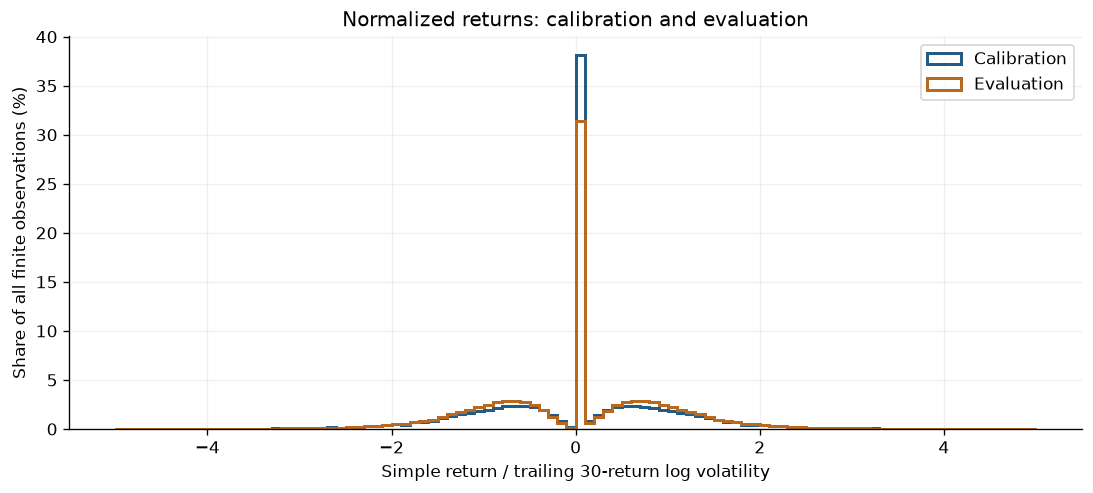

,1-bar target,2-bar target,3-bar target,5-bar target
Group,,,,
Calibration extremes - negative bar,"0.011502% (n=2,153,063)","0.012372% (n=2,114,693)","0.012686% (n=2,077,439)","0.013955% (n=2,002,124)"
Calibration extremes - positive bar,"-0.011289% (n=2,155,310)","-0.012320% (n=2,116,821)","-0.012761% (n=2,079,836)","-0.013944% (n=2,003,921)"


Rule,Variant,Horizon (bars),Trades,Mean return (%),Median return (%),STD (%),Standard error (%),t statistic,p value,Win rate (%)
Calibration extremes,Momentum,1,4308373,-0.011395,0.000000,0.083925,0.000040,-281.83,<1e-300,25.8
Calibration extremes,Reversal,1,4308373,0.011395,0.000000,0.083925,0.000040,281.83,<1e-300,46.5
Calibration extremes,Momentum,2,4231514,-0.012346,0.000000,0.107911,0.000052,-235.35,<1e-300,29.3
Calibration extremes,Reversal,2,4231514,0.012346,0.000000,0.107911,0.000052,235.35,<1e-300,48.3
Calibration extremes,Momentum,3,4157275,-0.012723,0.000000,0.126301,0.000062,-205.40,<1e-300,31.5
Calibration extremes,Reversal,3,4157275,0.012723,0.000000,0.126301,0.000062,205.40,<1e-300,48.9
Calibration extremes,Momentum,5,4006045,-0.013949,0.000000,0.154834,0.000077,-180.32,<1e-300,33.9
Calibration extremes,Reversal,5,4006045,0.013949,0.000000,0.154834,0.000077,180.32,<1e-300,49.8


In [12]:
normalized_arrays={label:np.concatenate(parts) for label,parts in normalized_samples.items()}
normalized_rows=[]
for label,values in normalized_arrays.items():
    quantiles=np.quantile(values,[.001,.01,.1,.5,.9,.99,.999]) if len(values) else [np.nan]*7
    normalized_rows.append({"Period":label,"Count":len(values),"Mean":np.mean(values),"STD":np.std(values,ddof=1),
        "Minimum":np.min(values),**dict(zip(["0.1%","1%","10%","Median","90%","99%","99.9%"],quantiles)),
        "Maximum":np.max(values),"Above 2 (%)":100*np.mean(values>2),"Below -2 (%)":100*np.mean(values < -2)})
normalized_distribution=pd.DataFrame(normalized_rows)
normalized_distribution.to_csv(OUTPUT_DIR/"normalized_return_distribution.csv",index=False)
show_table(normalized_distribution[["Period","Count","Mean","STD","10%","Median","90%"]],"Normalized returns: central distribution")
show_table(normalized_distribution[["Period","Minimum","0.1%","1%","99%","99.9%","Maximum","Above 2 (%)","Below -2 (%)"]],"Normalized returns: tails")
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
for (label,values),color in zip(normalized_arrays.items(),[COLORS["high"],COLORS["low"]]):
    weights=np.full(len(values),100/len(values))
    ax.hist(values,bins=np.linspace(-5,5,101),weights=weights,histtype="step",linewidth=1.8,color=color,label=label)
    print(f"{label}: {int((np.abs(values)>5).sum()):,} observations outside the displayed range; retained in all statistics.")
ax.set(title="Normalized returns: calibration and evaluation",xlabel="Simple return / trailing 30-return log volatility",ylabel="Share of all finite observations (%)")
ax.legend()
fig.savefig(OUTPUT_DIR/"normalized_return_distribution.png",dpi=160)
plt.show()
show_group_targets(["normalized_return"],"Future signed returns after normalized extremes")
show_metrics(combined_results.loc[combined_results.setup.eq("normalized_return")],"Normalized Return: momentum versus reversal")

## Compare high and low regimes
Report high-minus-low **momentum** mean returns; reversal differences have the opposite sign.
Compare both pooled differences and the median paired difference on instruments represented in both regimes.
These are descriptive contrasts: significance against zero within a group is not a test of the difference between regimes, and group composition/move sizes can differ.

In [13]:
regime_pairs=[("Return + Volume","return_high_volume","return_low_volume"),
    ("Range + Volume","range_high_volume","range_low_volume"),
    ("Return + Volatility","return_high_volatility","return_low_volatility")]
regime_rows=[]
for label,high,low in regime_pairs:
    for horizon in HORIZONS:
        pool=combined_results.loc[combined_results.variant.eq("momentum")&combined_results.horizon.eq(horizon)].set_index("setup")
        per=instrument_results.loc[instrument_results.variant.eq("momentum")&instrument_results.side.eq("combined")
            &instrument_results.horizon.eq(horizon)&instrument_results.setup.isin([high,low])]
        paired=per.pivot(index="file",columns="setup",values="mean").dropna()
        regime_rows.append({"comparison":label,"horizon":horizon,"high_mean_pct":100*pool.loc[high,"mean"],
            "low_mean_pct":100*pool.loc[low,"mean"],"pooled_difference_pp":100*(pool.loc[high,"mean"]-pool.loc[low,"mean"]),
            "paired_instruments":len(paired),"median_paired_difference_pp":100*(paired[high]-paired[low]).median()})
regime_comparison=pd.DataFrame(regime_rows)
regime_comparison.to_csv(OUTPUT_DIR/"regime_comparison.csv",index=False)
show_table(regime_comparison,"Momentum: high-minus-low regime comparison",rows=12)

comparison,horizon,high_mean_pct,low_mean_pct,pooled_difference_pp,paired_instruments,median_paired_difference_pp
Return + Volume,1,-0.011045,-0.016762,0.005717,58,0.006733
Return + Volume,2,-0.011795,-0.019732,0.007937,58,0.007893
Return + Volume,3,-0.011546,-0.021395,0.009849,58,0.007839
Return + Volume,5,-0.012685,-0.023631,0.010946,58,0.007924
Range + Volume,1,-0.008935,-0.004383,-0.004552,38,0.005964
Range + Volume,2,-0.009802,-0.005028,-0.004775,38,0.007962
Range + Volume,3,-0.009574,-0.005295,-0.004279,38,0.009708
Range + Volume,5,-0.010567,-0.007363,-0.003204,38,0.007735
Return + Volatility,1,-0.014487,-0.012890,-0.001596,62,-0.002096
Return + Volatility,2,-0.016270,-0.013967,-0.002303,62,-0.001787


## Mean strategy return by horizon
Returns are percentages per conditional event, not annualized. Error bars are ordinary 95% t intervals and inherit the independence limitation.
Lines connect the four observed horizons only.

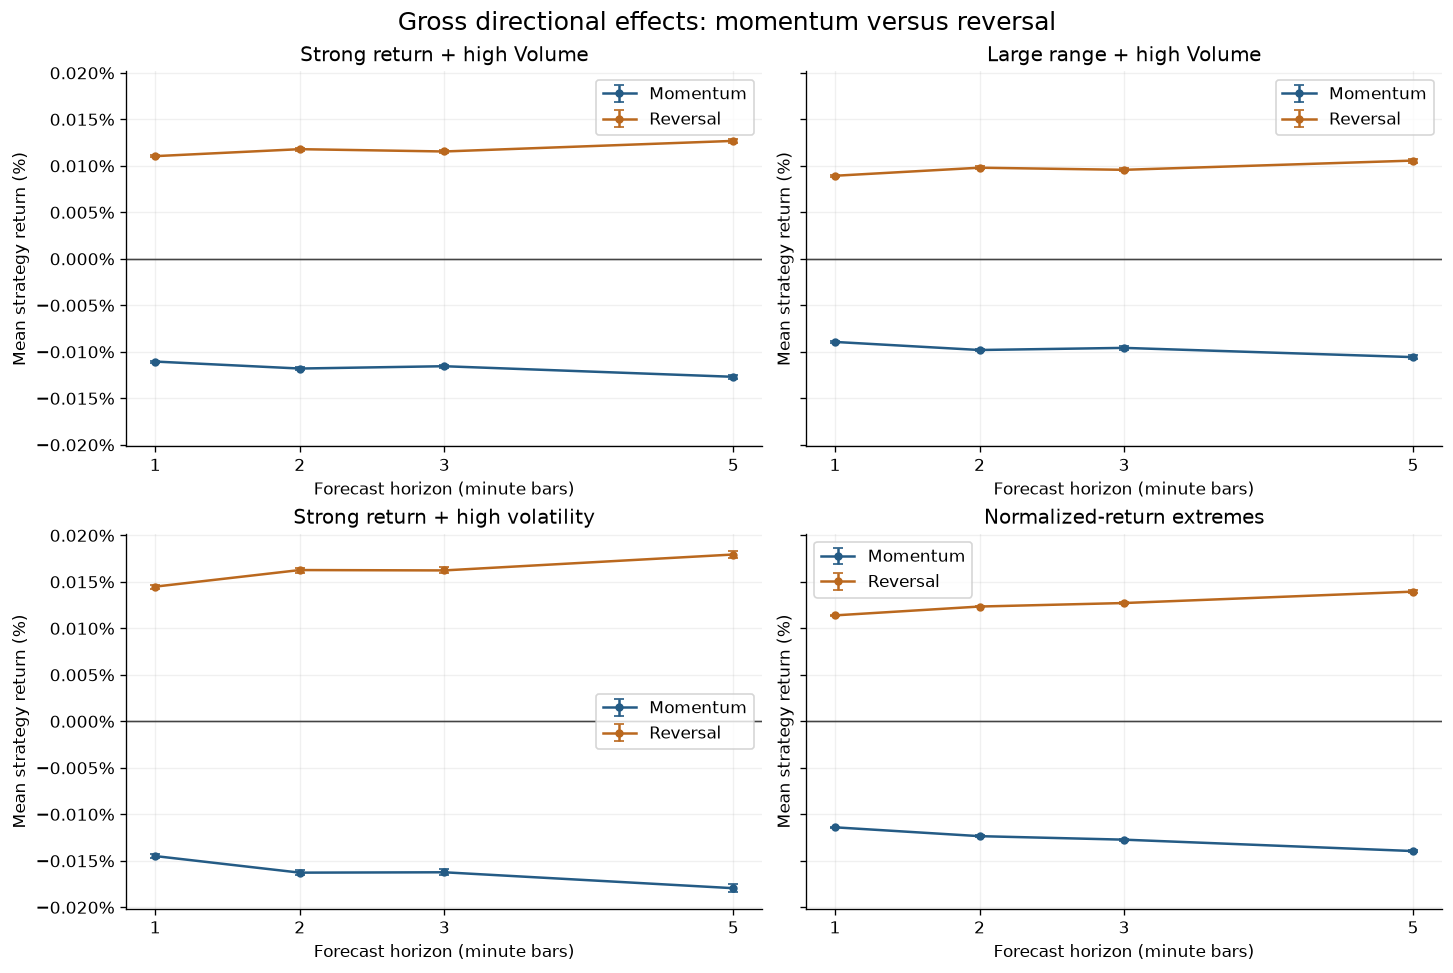

In [14]:
def plot_result(ax,setup,variant,label,color,linestyle="-"):
    data=combined_results.loc[combined_results.setup.eq(setup)&combined_results.variant.eq(variant)].sort_values("horizon")
    interval=stats.t.ppf(.975,data.n-1)*data.se*100
    ax.errorbar(data.horizon,data["mean"]*100,yerr=interval,marker="o",markersize=4,label=label,
        color=color,linestyle=linestyle,linewidth=1.5,capsize=3)
    ax.axhline(0,color="#444444",linewidth=.8)
    ax.set_xticks(HORIZONS)
    ax.set_xlabel("Forecast horizon (minute bars)")
    ax.set_ylabel("Mean strategy return (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100,decimals=3))

fig,axes=plt.subplots(2,2,figsize=(12,8),sharey=True,layout="constrained")
for ax,(setup,title) in zip(axes.flat,[("return_high_volume","Strong return + high Volume"),
    ("range_high_volume","Large range + high Volume"),("return_high_volatility","Strong return + high volatility"),
    ("normalized_return","Normalized-return extremes")]):
    for variant in VARIANTS:plot_result(ax,setup,variant,VARIANTS[variant],COLORS[variant])
    ax.set_title(title);ax.legend()
fig.suptitle("Gross directional effects: momentum versus reversal",fontsize=15)
fig.savefig(OUTPUT_DIR/"main_hypotheses_by_horizon.png",dpi=160)
plt.show()

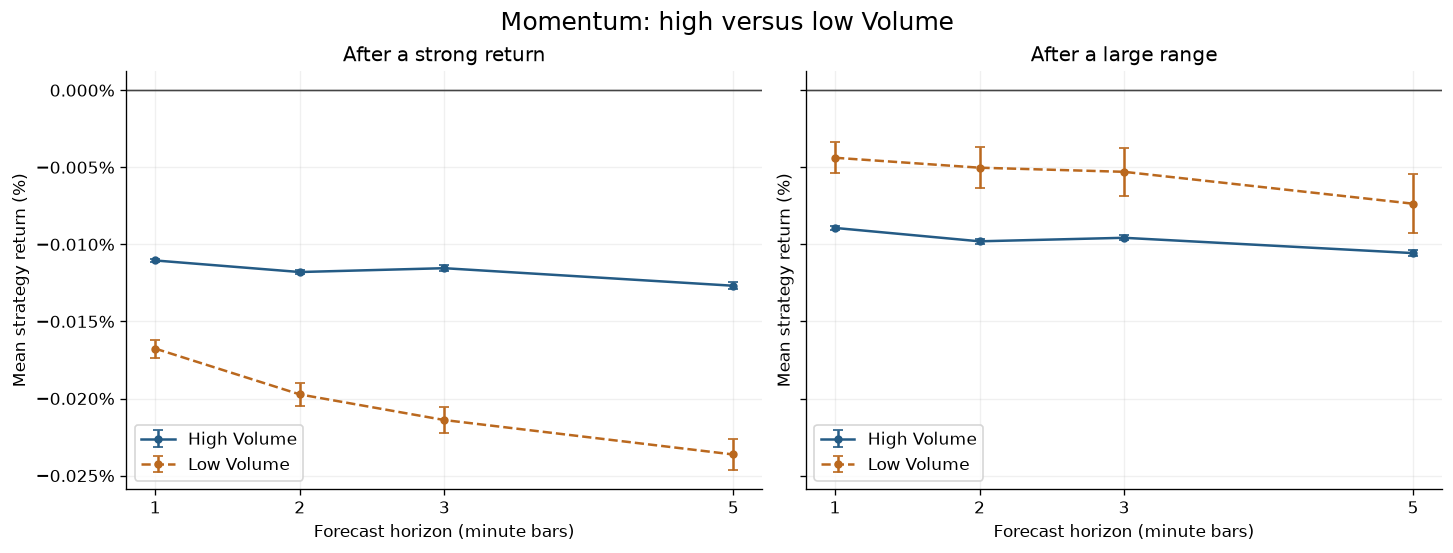

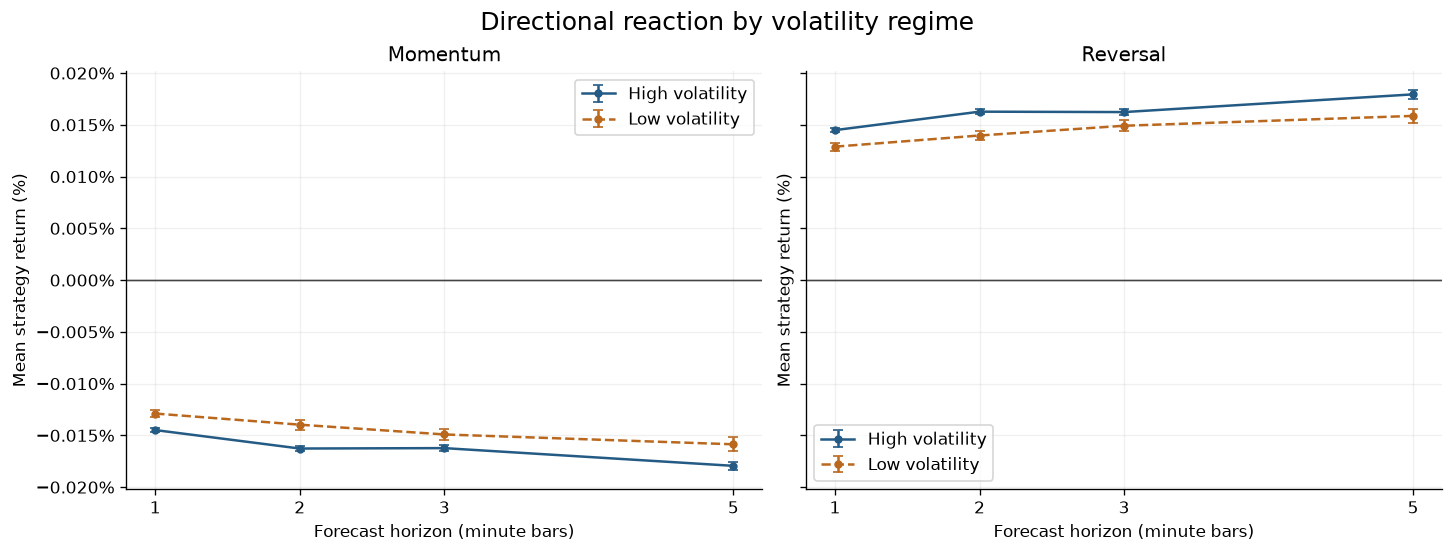

In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True,layout="constrained")
for ax,(high,low,title) in zip(axes,[("return_high_volume","return_low_volume","After a strong return"),
    ("range_high_volume","range_low_volume","After a large range")]):
    plot_result(ax,high,"momentum","High Volume",COLORS["high"])
    plot_result(ax,low,"momentum","Low Volume",COLORS["low"],"--")
    ax.set_title(title);ax.legend()
fig.suptitle("Momentum: high versus low Volume",fontsize=15)
fig.savefig(OUTPUT_DIR/"high_low_volume_comparison.png",dpi=160)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True,layout="constrained")
for ax,variant in zip(axes,VARIANTS):
    plot_result(ax,"return_high_volatility",variant,"High volatility",COLORS["high"])
    plot_result(ax,"return_low_volatility",variant,"Low volatility",COLORS["low"],"--")
    ax.set_title(VARIANTS[variant]);ax.legend()
fig.suptitle("Directional reaction by volatility regime",fontsize=15)
fig.savefig(OUTPUT_DIR/"high_low_volatility_comparison.png",dpi=160)
plt.show()

## Final comparison: ten variants and four horizons
High Volume is the primary setup for families 1 and 2; low Volume comparisons remain in the complete output.
Both volatility regimes are primary variants. The CSV additionally includes STD, SE, signal counts and instrument-level consistency.

In [16]:
main_setups=["return_high_volume","range_high_volume","return_high_volatility","return_low_volatility","normalized_return"]
STRATEGY_NAMES={"return_high_volume":"Return + Volume","range_high_volume":"Bar Range + Volume",
    "return_high_volatility":"High Volatility","return_low_volatility":"Low Volatility","normalized_return":"Normalized Return"}
main_results=pd.concat([combined_results.loc[combined_results.setup.eq(setup)&combined_results.variant.eq(variant)].sort_values("horizon")
    for setup in main_setups for variant in VARIANTS],ignore_index=True)
main_results["strategy_name"]=[f"{STRATEGY_NAMES[s]} {VARIANTS[v]}" for s,v in zip(main_results.setup,main_results.variant)]
final_table=presentation(main_results.drop(columns=["setup","variant","side"])).rename(columns={"strategy_name":"Strategy"})
final_table=final_table[["Strategy",*[column for column in final_table if column!="Strategy"]]]
assert len(final_table)==40
final_table.to_csv(RESULT_PATH,index=False)
display_columns=["Strategy","Horizon (bars)","Trades","Mean return (%)","Median return (%)","Win rate (%)",
    "t statistic","p value","Agreeing instruments","Direction agreement (%)"]
display(final_table[display_columns].style.hide(axis="index").format({"Mean return (%)":"{:.6f}",
    "Median return (%)":"{:.6f}","Win rate (%)":"{:.1f}","t statistic":"{:.2f}",
    "p value":format_probability,"Direction agreement (%)":"{:.1f}"},na_rep="NA")
    .set_caption("Final strategy hypothesis comparison")
    .set_properties(**{"padding":"5px 7px","font-size":"12px"})
    .set_table_styles([{"selector":"th","props":[("white-space","normal"),("max-width","125px")]}]))

Strategy,Horizon (bars),Trades,Mean return (%),Median return (%),Win rate (%),t statistic,p value,Agreeing instruments,Direction agreement (%)
Return + Volume Momentum,1,3858981,-0.011045,0.000000,31.8,-192.15,<1e-300,73,97.3
Return + Volume Momentum,2,3816447,-0.011795,0.000000,34.9,-156.40,<1e-300,74,98.7
Return + Volume Momentum,3,3776213,-0.011546,0.000000,36.8,-129.43,<1e-300,74,98.7
Return + Volume Momentum,5,3695821,-0.012685,0.000000,38.7,-113.68,<1e-300,74,98.7
Return + Volume Reversal,1,3858981,0.011045,0.000000,47.6,192.15,<1e-300,73,97.3
Return + Volume Reversal,2,3816447,0.011795,0.000000,48.7,156.40,<1e-300,74,98.7
Return + Volume Reversal,3,3776213,0.011546,0.000000,49.1,129.43,<1e-300,74,98.7
Return + Volume Reversal,5,3695821,0.012685,0.000000,49.8,113.68,<1e-300,74,98.7
Bar Range + Volume Momentum,1,3945161,-0.008935,0.000000,33.8,-156.58,<1e-300,74,98.7
Bar Range + Volume Momentum,2,3900233,-0.009802,0.000000,36.5,-130.39,<1e-300,74,98.7


## Instrument-level consistency
The median below gives instruments equal weight; pooled returns give events equal weight. Agreement follows the pooled sign, whether positive or negative.
The illustration preserves the previous rule: positive mean, at least 1,000 events and 10 instruments, at least 60% sign agreement, nominal p < 0.05; then rank by instrument-median effect, pooled effect and count.
This is a descriptive choice for a plot, not optimization by minimum p-value.

Strategy,Horizon (bars),Instruments with data,Positive instruments,Negative instruments,Zero-mean instruments,Median instrument mean (%),Direction agreement (%)
Return + Volume Momentum,1,75,2,73,0,-0.011490,97.333333
Return + Volume Momentum,2,75,1,74,0,-0.012672,98.666667
Return + Volume Momentum,3,75,1,74,0,-0.012106,98.666667
Return + Volume Momentum,5,75,1,74,0,-0.013037,98.666667
Return + Volume Reversal,1,75,73,2,0,0.011490,97.333333
Return + Volume Reversal,2,75,74,1,0,0.012672,98.666667
Return + Volume Reversal,3,75,74,1,0,0.012106,98.666667
Return + Volume Reversal,5,75,74,1,0,0.013037,98.666667
Bar Range + Volume Momentum,1,75,1,74,0,-0.009161,98.666667
Bar Range + Volume Momentum,2,75,1,74,0,-0.009634,98.666667


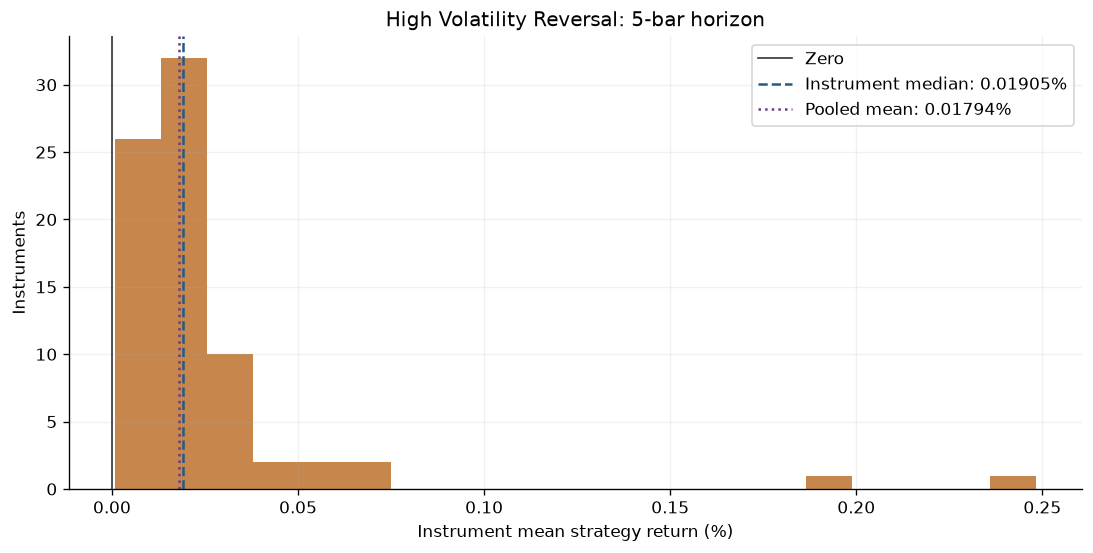

Instruments shown: 76; meets the descriptive illustration rule: True


In [17]:
stability_columns=["Strategy","Horizon (bars)","Instruments with data","Positive instruments","Negative instruments",
    "Zero-mean instruments","Median instrument mean (%)","Direction agreement (%)"]
show_table(final_table[stability_columns],"Instrument-level consistency",rows=40)
def choose_case(table):
    eligible = table.loc[table["mean"].gt(0) & table.n.ge(1000) & table.instruments.ge(10)
                         & table.confirming_pct.ge(60) & table.p_value.lt(ALPHA)]
    if len(eligible):
        return eligible.sort_values(["median_instrument_mean", "mean", "n"], ascending=False).iloc[0], True
    candidates = table.loc[table["mean"].notna()].copy()
    if candidates.empty:
        return None, False
    return candidates.loc[candidates.median_instrument_mean.abs().idxmax()], False

interesting,meets_illustration_rule=choose_case(main_results)
if interesting is None:
    print("No defined instrument-level result is available for a distribution plot.")
else:
    chosen=instrument_results.loc[instrument_results.setup.eq(interesting.setup)&instrument_results.variant.eq(interesting.variant)
        &instrument_results.side.eq("combined")&instrument_results.horizon.eq(interesting.horizon)&instrument_results.n.gt(0)]
    values=chosen["mean"].dropna()*100
    fig,ax=plt.subplots(figsize=(9,4.5),layout="constrained")
    ax.hist(values,bins=20,color=COLORS[interesting.variant],alpha=.8)
    ax.axvline(0,color="#333333",linewidth=1,label="Zero")
    ax.axvline(values.median(),color="#245b85",linestyle="--",label=f"Instrument median: {values.median():.5f}%")
    ax.axvline(interesting["mean"]*100,color="#6a3d82",linestyle=":",label=f"Pooled mean: {interesting['mean']*100:.5f}%")
    ax.set(title=f"{STRATEGY_NAMES[interesting.setup]} {VARIANTS[interesting.variant]}: {int(interesting.horizon)}-bar horizon",
        xlabel="Instrument mean strategy return (%)",ylabel="Instruments")
    ax.legend()
    fig.savefig(OUTPUT_DIR/"instrument_mean_distribution.png",dpi=160)
    plt.show()
    print(f"Instruments shown: {len(values)}; meets the descriptive illustration rule: {meets_illustration_rule}")

## Long and short components
The complete export includes both sides separately for every setup. Positive short-strategy return means the predicted fall occurred.
The first-family primary setup is shown here as a compact example.

In [18]:
side_view=pooled_results.loc[pooled_results.setup.eq("return_high_volume")&pooled_results.side.ne("combined")]
show_table(presentation(side_view[["variant","side","horizon","n","mean","median","std","se","t_stat","p_value","win_rate"]]),
    "Return + high Volume: long and short components",rows=16)

Variant,Side,Horizon (bars),Trades,Mean return (%),Median return (%),STD (%),Standard error (%),t statistic,p value,Win rate (%)
Momentum,Long,1,1930085,-0.010646,0.000000,0.110655,0.000080,-133.666231,<1e-300,31.949007
Momentum,Short,1,1928896,-0.011444,0.000000,0.115130,0.000083,-138.046297,<1e-300,31.631514
Reversal,Long,1,1928896,0.011444,0.000000,0.115130,0.000083,138.046297,<1e-300,47.821241
Reversal,Short,1,1930085,0.010646,0.000000,0.110655,0.000080,133.666231,<1e-300,47.461537
Momentum,Long,2,1908874,-0.011346,0.000000,0.144678,0.000105,-108.351940,<1e-300,35.121490
Momentum,Short,2,1907573,-0.012244,0.000000,0.149943,0.000109,-112.784075,<1e-300,34.676943
Reversal,Long,2,1907573,0.012244,0.000000,0.149943,0.000109,112.784075,<1e-300,49.001585
Reversal,Short,2,1908874,0.011346,0.000000,0.144678,0.000105,108.351940,<1e-300,48.485861
Momentum,Long,3,1888800,-0.011075,0.000000,0.170935,0.000124,-89.046731,<1e-300,37.107529
Momentum,Short,3,1887413,-0.012017,0.000000,0.175732,0.000128,-93.948821,<1e-300,36.563063


## Research conclusions
Describe direction using effect size, nominal t evidence, coverage and cross-instrument agreement together.
The same coverage/agreement thresholds as the illustration provide descriptive labels, not a certification of profitability.

In [19]:
def family_assessment(setups):
    part=combined_results.loc[combined_results.setup.isin(setups)&combined_results.variant.eq("momentum")]
    supported=part.loc[part.n.ge(1000)&part.instruments.ge(10)&part.confirming_pct.ge(60)&part.p_value.lt(ALPHA)]
    signs=set(np.sign(supported["mean"]).astype(int))
    if any(len(set(np.sign(group["mean"])))>1 for _,group in supported.groupby("horizon")):
        return "the result depends on market regime"
    return "evidence of momentum" if signs=={1} else "evidence of reversal" if signs=={-1} else "no clear directional dependence"

conclusion_paragraphs=[]
families=[("Return + Volume",["return_high_volume","return_low_volume"],"Return + Volume"),
    ("Bar Range + Volume",["range_high_volume","range_low_volume"],"Range + Volume"),
    ("Volatility Regime",["return_high_volatility","return_low_volatility"],"Return + Volatility"),
    ("Normalized Return",["normalized_return"],None)]
for title,setups,comparison_name in families:
    focus,_=choose_case(combined_results.loc[combined_results.setup.eq(setups[0])])
    assessment=family_assessment(setups)
    paragraph=f"### {title}\n\nWe tested continuation versus reversal after the specified conditional price movement: **{assessment}**. "
    if focus is not None:
        paragraph+=(f"The strongest primary variant by median instrument effect is {VARIANTS[focus.variant].lower()} at "
            f"{int(focus.horizon)} bars: pooled mean {focus['mean']*100:.6f}% on {int(focus.n):,} events, "
            f"with nominal one-sample t-test p {format_probability(focus.p_value)}. "
            f"Direction agrees in {int(focus.confirming_instruments)}/{int(focus.instruments)} instruments "
            f"({focus.confirming_pct:.1f}%); the median instrument mean is {focus.median_instrument_mean*100:.6f}%. ")
        if comparison_name:
            contrast=regime_comparison.loc[regime_comparison.comparison.eq(comparison_name)&regime_comparison.horizon.eq(focus.horizon)].iloc[0]
            if np.sign(contrast.pooled_difference_pp)!=np.sign(contrast.median_paired_difference_pp):
                paragraph+="The Volume contrast changes sign between pooled and paired-instrument averaging, so the advantage of high Volume is not robust to aggregation."
            elif contrast.high_mean_pct<0 and contrast.low_mean_pct<0:
                stronger="low" if contrast.pooled_difference_pp>0 else "high"
                factor="volatility" if comparison_name=="Return + Volatility" else "Volume"
                paragraph+=f"Reversal is stronger in the {stronger}-{factor} regime under both comparisons; the regime changes magnitude without turning the response into momentum."
            else:
                paragraph+=f"The descriptive high-minus-low momentum contrast is {contrast.pooled_difference_pp:.6f} percentage points; it does not establish causality."
        else:
            paragraph+="Normalization retains the gross directional pattern but does not establish economic significance."
    else:
        paragraph+="No defined target sample is available."
    conclusion_paragraphs.append(paragraph)
    display(Markdown(paragraph))

### Return + Volume

We tested continuation versus reversal after the specified conditional price movement: **evidence of reversal**. The strongest primary variant by median instrument effect is reversal at 5 bars: pooled mean 0.012685% on 3,695,821 events, with nominal one-sample t-test p <1e-300. Direction agrees in 74/75 instruments (98.7%); the median instrument mean is 0.013037%. Reversal is stronger in the low-Volume regime under both comparisons; the regime changes magnitude without turning the response into momentum.

### Bar Range + Volume

We tested continuation versus reversal after the specified conditional price movement: **evidence of reversal**. The strongest primary variant by median instrument effect is reversal at 5 bars: pooled mean 0.010567% on 3,772,823 events, with nominal one-sample t-test p <1e-300. Direction agrees in 74/75 instruments (98.7%); the median instrument mean is 0.010202%. The Volume contrast changes sign between pooled and paired-instrument averaging, so the advantage of high Volume is not robust to aggregation.

### Volatility Regime

We tested continuation versus reversal after the specified conditional price movement: **evidence of reversal**. The strongest primary variant by median instrument effect is reversal at 5 bars: pooled mean 0.017942% on 1,564,327 events, with nominal one-sample t-test p <1e-300. Direction agrees in 76/76 instruments (100.0%); the median instrument mean is 0.019046%. Reversal is stronger in the high-volatility regime under both comparisons; the regime changes magnitude without turning the response into momentum.

### Normalized Return

We tested continuation versus reversal after the specified conditional price movement: **evidence of reversal**. The strongest primary variant by median instrument effect is reversal at 5 bars: pooled mean 0.013949% on 4,006,045 events, with nominal one-sample t-test p <1e-300. Direction agrees in 76/76 instruments (100.0%); the median instrument mean is 0.015278%. Normalization retains the gross directional pattern but does not establish economic significance.

## What the correlation analysis contributed
The earlier screen established persistent relationships among price levels, activity, volatility, range and Open Interest.
Absolute-value dependence describes market magnitude/state; it does not supply a long or short direction.
This notebook adds signed returns, historical calibration and explicit positions to ask whether those relationships contain gross directional information.
Statistical evidence, a gross conditional effect and a production-ready profitable strategy are distinct claims. The current results support only the first two within this explored history, subject to the stated test and selection limitations.

## Save outputs and verify target construction
Recheck source-ID examples directly against future prices and segment IDs in the upstream feature artifact, independently of the group-shift implementation.
All reported percentages are labeled explicitly; internal arrays retain fractional return units.

In [20]:
presentation(pooled_results).to_csv(OUTPUT_DIR/"all_strategy_metrics.csv",index=False)
presentation(instrument_results).to_csv(OUTPUT_DIR/"instrument_strategy_metrics.csv",index=False)
presentation(group_results).to_csv(OUTPUT_DIR/"group_future_returns.csv",index=False)
examples=pd.DataFrame(event_examples)
examples.to_csv(OUTPUT_DIR/"signal_examples.csv",index=False)
reference_checks=0
for filename,events in examples.groupby("file",sort=True):
    source=load_market(filename)
    locations=pd.Index(source.ID).get_indexer(events.ID)
    assert (locations>=0).all()
    prices,segment_ids=source.Close.to_numpy(),source.segment_id.to_numpy()
    for horizon in HORIZONS:
        for position,actual in zip(locations,events[f"future_return_{horizon}"]):
            other=position+horizon
            valid=other<len(source) and segment_ids[other]==segment_ids[position]
            expected=prices[other]/prices[position]-1 if valid and prices[position]>0 and prices[other]>0 else np.nan
            np.testing.assert_allclose(actual,expected,rtol=1e-12,atol=1e-14,equal_nan=True)
            reference_checks+=1
manifest_rows=[]
for path,before in source_hashes.items():
    after=file_hash(path)
    manifest_rows.append({"path":path,"sha256_before":before,"sha256_after":after,"unchanged":before==after})
input_manifest=pd.DataFrame(manifest_rows)
assert input_manifest.unchanged.all()
input_manifest.to_csv(OUTPUT_DIR/"input_manifest.csv",index=False)
parameters={"pipeline_stage":3,"input_features":str(FEATURE_PATH),"screen_context":str(SCREEN_PATH),
    "output":str(RESULT_PATH),"instruments":len(files),"observations":int(coverage.rows.sum()),
    "evaluation_rows":int(thresholds.evaluation_rows.sum()),"calibration_fraction":CALIBRATION_FRACTION,
    "horizons":HORIZONS,"primary_rows":len(final_table),"independent_target_checks":reference_checks,
    "test":"ordinary exploratory two-sided one-sample t-test; no serial or multiple-test correction",
    "return_units":"fraction internally; percent in labeled presentation CSVs",
    "features_recomputed":False,"rows_deleted":0,"winsorization":False,"input_files_unchanged":True}
(OUTPUT_DIR/"research_parameters.json").write_text(json.dumps(parameters,indent=2)+"\n")
(OUTPUT_DIR/"research_conclusions.md").write_text("# Research conclusions\n\n"+"\n\n".join(conclusion_paragraphs)+"\n")
print(f"Saved {RESULT_PATH}: {len(final_table)} primary rows")
print(f"Independent target checks: {reference_checks:,}; unchanged input artifacts: {len(input_manifest)}")
display(Markdown("**Pipeline complete.** Main output: [strategy_hypothesis_results.csv](artifacts/strategy_hypothesis_results.csv). "
    "Detailed metrics, calibration, examples and figures: `artifacts/strategies/`."))

Saved artifacts/strategy_hypothesis_results.csv: 40 primary rows
Independent target checks: 10,760; unchanged input artifacts: 4


**Pipeline complete.** Main output: [strategy_hypothesis_results.csv](artifacts/strategy_hypothesis_results.csv). Detailed metrics, calibration, examples and figures: `artifacts/strategies/`.

## Time-series experiment: forecast direction and volatility

**Questions.** Does the negative short-lag return correlation improve forecasts of signed returns? Does volatility clustering improve forecasts of future variance?

Use all instruments with sufficient nonconstant calibration data, not a selection based on evaluation performance. Keep the original first-30%-of-dates calibration and subsequent evaluation split. Coefficients remain fixed during evaluation; filter states update sequentially from observations already available. This is a fixed-parameter chronological holdout, not a rolling-refit exercise. Earlier full-history correlation screening motivated these models, so this history is not a pristine, independently selected final test.

**Segment handling.** Pool calibration losses across the existing segments of each instrument; estimate one parameter set per instrument/model. Reset dynamic states at each segment boundary and after a missing/nonfinite return. These temporary estimation runs do not modify the upstream segments or remove source rows. Never join returns across a contract switch or a time gap. Do not estimate a separate model on each short segment.

**Scaling and mean.** Load `log_return` from Notebook 2. Estimate its mean and population standard deviation using calibration returns only, then use `x = (log_return - calibration_mean) / calibration_std`. All models share this fixed estimated mean. Scaling only improves optimization; reported return forecasts are converted back to fractional log returns. No winsorization, clipping of observations, or automatic outlier removal is applied. Constant or insufficient calibration series are explicitly reported as ineligible.

This is a new experiment. It does not change previous feature definitions, thresholds or strategy results.

In [21]:
from scipy.optimize import minimize
from scipy.signal import lfilter
import time

MODEL_COLORS = {"Zero": "#777777", "Training mean": "#9b7653", "AR(1)": "#245b85",
                "MA(1)": "#ba681e", "ARMA(1,1)": "#6a3d82", "GARCH(1,1)": "#245b85",
                "Historical variance": "#777777", "Trailing 30m": "#ba681e", "EWMA": "#43805e"}
MODEL_DATA_COLUMNS = ["instrument", "date", "ID", "symbol", "segment_id", "log_return",
                      "simple_return", "close", "volume", "rolling_30m_volatility"]

def load_model_data(filename):
    data = pd.read_parquet(FEATURE_PATH, filters=[("instrument", "=", filename)],
                           columns=MODEL_DATA_COLUMNS).rename(columns=RAW_FIELDS).sort_values(["date", "ID"], kind="stable").reset_index(drop=True)
    inside = data.segment_id.eq(data.segment_id.shift())
    assert data.date.diff().loc[inside].eq(pd.Timedelta(minutes=1)).all()
    assert data.symbol.eq(data.symbol.shift()).loc[inside].all()
    return data

def return_run_matrix(values, segment_ids):
    """One finite contiguous run per row; preserve original positions, pad only after run ends."""
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    continuation = np.zeros(len(values), dtype=bool)
    continuation[1:] = finite[1:] & finite[:-1] & (segment_ids[1:] == segment_ids[:-1])
    starts = np.flatnonzero(finite & ~continuation)
    last = np.r_[~continuation[1:], True]
    ends = np.flatnonzero(finite & last) + 1
    lengths = ends - starts
    if not len(lengths):
        return np.empty((0, 0)), np.empty((0, 0), dtype=int), lengths
    positions = starts[:, None] + np.arange(lengths.max())[None, :]
    valid = np.arange(lengths.max())[None, :] < lengths[:, None]
    positions = np.where(valid, positions, -1)
    matrix = np.where(valid, values[np.maximum(positions, 0)], 0.0)
    return matrix, positions, lengths

def matrix_to_series(matrix, positions, size):
    result = np.full(size, np.nan)
    valid = positions >= 0
    result[positions[valid]] = matrix[valid]
    return result

### AR(1), MA(1) and ARMA(1,1): conditional estimation
For centered, scaled returns, `x_t = phi*x_(t-1) + epsilon_t + theta*epsilon_(t-1)`.
AR(1) fixes theta to zero; MA(1) fixes phi to zero. Fit the remaining coefficients by conditional Gaussian least squares, pooling squared innovations over calibration runs. This is **conditional estimation with a fixed calibration mean**, not the exact unconditional state-space likelihood.

Within each run, condition on its first return and initialize its innovation to zero; exclude that initialization point from the fitting loss. Enforce `abs(phi), abs(theta) <= 0.98` for stationary/invertible candidates. Use deterministic multiple starts and report convergence, boundary estimates and near-cancellation (`abs(phi + theta) < 0.02`) rather than hiding them. An unsuccessful fit remains in the fit report and is not used as a fitted forecast.

At origin t, the one-step forecast is `phi*x_t + theta*epsilon_t`. Later expected returns decay with phi. Sum their expectations and add `h*calibration_mean` to predict the cumulative **log** return over h bars. Future observations never update an earlier forecast.

Reference: [statsmodels time-series estimation](https://www.statsmodels.org/stable/tsa.html).

In [22]:
def arma_innovations(matrix, phi, theta):
    forcing = np.zeros_like(matrix)
    forcing[:, 1:] = matrix[:, 1:] - phi * matrix[:, :-1]
    return lfilter([1.0], [1.0, theta], forcing, axis=1)

def arma_objective(parameters, matrix, loss_mask, order):
    p, q = order
    phi = parameters[0] if p else 0.0
    theta = parameters[-1] if q else 0.0
    residual = arma_innovations(matrix, phi, theta)
    selected = residual[loss_mask]
    gradients = []
    if p:
        forcing = np.zeros_like(matrix)
        forcing[:, 1:] = -matrix[:, :-1]
        derivative = lfilter([1.0], [1.0, theta], forcing, axis=1)
        gradients.append(2 * np.mean(selected * derivative[loss_mask]))
    if q:
        forcing = np.zeros_like(matrix)
        forcing[:, 1:] = -residual[:, :-1]
        derivative = lfilter([1.0], [1.0, theta], forcing, axis=1)
        gradients.append(2 * np.mean(selected * derivative[loss_mask]))
    return float(np.mean(selected**2)), np.asarray(gradients)

def fit_arma(matrix, positions, order):
    mask = positions >= 0
    mask[:, 0] = False
    p, q = order
    starts = [[0.0], [-0.2], [0.2]] if p + q == 1 else [[-0.1, 0.0], [0.0, -0.1], [0.2, -0.3]]
    attempts = [minimize(arma_objective, initial, args=(matrix, mask, order), jac=True,
                        method="L-BFGS-B", bounds=[(-MODEL_COEFFICIENT_BOUND, MODEL_COEFFICIENT_BOUND)]*(p+q),
                        options={"maxiter": MODEL_OPTIMIZER_MAX_ITER, "ftol": 1e-11, "gtol": 1e-7})
                for initial in starts]
    successful = [fit for fit in attempts if fit.success and np.isfinite(fit.fun)]
    best = min(successful or attempts, key=lambda fit: fit.fun)
    phi = float(best.x[0]) if p else 0.0
    theta = float(best.x[-1]) if q else 0.0
    return dict(phi=phi, theta=theta, success=bool(successful), loss=float(best.fun),
                optimizer_message=str(best.message), iterations=int(best.nit), attempts=len(attempts),
                boundary=bool(np.any(np.abs(best.x) >= MODEL_COEFFICIENT_BOUND - 1e-5)),
                near_cancellation=bool(p and q and abs(phi + theta) < 0.02))

def arma_forecast_series(matrix, positions, size, fit, horizon, location, scale):
    innovations = arma_innovations(matrix, fit["phi"], fit["theta"])
    next_centered = fit["phi"] * matrix + fit["theta"] * innovations
    multiplier = sum(fit["phi"]**step for step in range(horizon))
    return horizon * location + scale * multiplier * matrix_to_series(next_centered, positions, size)

### GARCH(1,1): conditional variance, not price direction
Use the same fixed training mean and standardized returns, and estimate

`v_t = omega + alpha*x_(t-1)^2 + beta*v_(t-1)`.

Pool the Gaussian quasi-likelihood `0.5*mean(log(v_t) + x_t^2/v_t)` over calibration runs. Gaussian QML specifies a fitting criterion, not a claim that returns have Gaussian tails. Fix `v_0 = 1` at every run start using calibration scaling. Enforce omega > 0, alpha >= 0, beta >= 0 and alpha + beta < 0.999 with smooth parameter transforms. No volatility state passes through a gap. All three coefficients are estimated; unconditional variance is not forced to equal the training variance.

After observing return t, forecast `v_(t+1) = omega + alpha*x_t^2 + beta*v_t`; for later steps use `v_(t+j) = omega + (alpha+beta)*v_(t+j-1)`. Average these forecasts over **1, 5 and 30 future minutes**.

The observed target is the future mean of `(log_return - training_mean)^2` over the same uninterrupted horizon. Its square root is a realized RMS volatility proxy. Latent conditional variance is unobserved: a single squared return is noisy, and this proxy also includes any predictable conditional-mean component relative to the fixed mean. It is not a forward sample standard deviation or tomorrow's overlapping trailing-volatility feature.

References: [GARCH definition](https://arch.readthedocs.io/en/latest/univariate/generated/arch.univariate.GARCH.html), [analytic variance forecasts](https://arch.readthedocs.io/en/latest/univariate/forecasting.html).

In [23]:
def garch_parameters(unconstrained):
    omega = np.exp(unconstrained[0])
    weights = np.exp(np.r_[0.0, unconstrained[1:]] - max(0.0, *unconstrained[1:]))
    shares = weights / weights.sum()
    alpha, beta = 0.999 * shares[1:]
    jacobian = np.array([[omega, 0.0, 0.0],
                        [0.0, alpha * (1-shares[1]), -alpha * shares[2]],
                        [0.0, -beta * shares[1], beta * (1-shares[2])]])
    return omega, alpha, beta, jacobian

def garch_variance(matrix, omega, alpha, beta):
    forcing = np.empty_like(matrix)
    forcing[:, 0] = 1.0
    forcing[:, 1:] = omega + alpha * matrix[:, :-1]**2
    return lfilter([1.0], [1.0, -beta], forcing, axis=1)

def garch_objective(parameters, matrix, loss_mask):
    omega, alpha, beta, jacobian = garch_parameters(parameters)
    variance = garch_variance(matrix, omega, alpha, beta)
    value = variance[loss_mask]
    square = matrix[loss_mask]**2
    score = 0.5 * (1/value - square/value**2)
    count = len(value)
    forcing = np.zeros_like(matrix)
    forcing[:, 1:] = 1.0
    d_omega = lfilter([1.0], [1.0, -beta], forcing, axis=1)
    forcing[:, 1:] = matrix[:, :-1]**2
    d_alpha = lfilter([1.0], [1.0, -beta], forcing, axis=1)
    forcing[:, 1:] = variance[:, :-1]
    d_beta = lfilter([1.0], [1.0, -beta], forcing, axis=1)
    gradient = np.array([np.sum(score * derivative[loss_mask])/count
                         for derivative in [d_omega, d_alpha, d_beta]]) @ jacobian
    return float(0.5*np.mean(np.log(value) + square/value)), gradient

def fit_garch(matrix, positions):
    mask = positions >= 0
    mask[:, 0] = False
    initial_values = [(0.05, 0.1, 0.85), (0.2, 0.2, 0.6), (0.05, 0.4, 0.55)]
    attempts = []
    for omega, alpha, beta in initial_values:
        remainder = 0.999 - alpha - beta
        initial = [np.log(omega), np.log(alpha/remainder), np.log(beta/remainder)]
        attempts.append(minimize(garch_objective, initial, args=(matrix, mask), jac=True,
            method="L-BFGS-B", bounds=[(-18, 5), (-12, 12), (-12, 12)],
            options={"maxiter": MODEL_OPTIMIZER_MAX_ITER, "ftol": 1e-10, "gtol": 1e-6}))
    successful = [fit for fit in attempts if fit.success and np.isfinite(fit.fun)]
    best = min(successful or attempts, key=lambda fit: fit.fun)
    omega, alpha, beta, _ = garch_parameters(best.x)
    return dict(omega=float(omega), alpha=float(alpha), beta=float(beta), persistence=float(alpha+beta),
                success=bool(successful), loss=float(best.fun), optimizer_message=str(best.message),
                iterations=int(best.nit), attempts=len(attempts),
                boundary=bool(alpha+beta > 0.998 or np.any(np.abs(best.x[1:]) > 11.9)
                              or best.x[0] < -17.9 or best.x[0] > 4.9))

def variance_forecast_series(matrix, positions, size, fit, horizon, scale):
    variance = garch_variance(matrix, fit["omega"], fit["alpha"], fit["beta"])
    next_variance = fit["omega"] + fit["alpha"]*matrix**2 + fit["beta"]*variance
    total = next_variance.copy()
    for _ in range(1, horizon):
        next_variance = fit["omega"] + fit["persistence"]*next_variance
        total += next_variance
    return scale**2 * matrix_to_series(total/horizon, positions, size)

def ewma_forecast_series(matrix, positions, size, scale):
    forcing = np.empty_like(matrix)
    forcing[:, 0] = 1.0
    forcing[:, 1:] = (1-EWMA_DECAY) * matrix[:, :-1]**2
    previous = lfilter([1.0], [1.0, -EWMA_DECAY], forcing, axis=1)
    next_variance = EWMA_DECAY*previous + (1-EWMA_DECAY)*matrix**2
    return scale**2 * matrix_to_series(next_variance, positions, size)

### Evaluation targets, benchmarks and losses
**Mean forecasts:** the cumulative log-return target is `log(Close[t+h]/Close[t])`, requiring a complete finite return path. This equals the sum of log returns mathematically and preserves exact zero targets when endpoint prices match. Compare AR(1), MA(1), ARMA(1,1) against zero and the training mean, on the same origins per instrument/horizon. Report MSE, MAE, MSE skill versus each baseline, forecast/target correlation, and sign accuracy conditional on a nonzero target (a zero forecast counts as incorrect). Also report the zero-target share and `sign(forecast) * future_simple_return` as a gross direction diagnostic. The MA terms use only innovations already observed by the origin.

**Variance forecasts:** compare GARCH against the fixed training variance, upstream trailing-30-return sample variance, and EWMA with prespecified decay 0.94. Carry each baseline's current variance forecast unchanged across future steps. Restrict the common comparison to origins with a finite trailing-30-minute feature and a complete future target. This is an explicitly reported evaluation-availability condition, not a change to preprocessing.

Report variance MSE, volatility RMSE, forecast/realized-variance correlation and **QLIKE = log(predicted variance) + realized variance / predicted variance**, lower being better. Omit the target-only term so zero realized variance is permitted. Floor predicted variances at `1e-8 * training_variance` for numerical scoring only; report how often this happens. No realized target is floored or trimmed. Percentage QLIKE improvement is not meaningful; use paired loss differences. Average file-level skills equally to avoid letting high-volatility instruments dominate.

One-step and overlapping multi-step forecasts are dependent. Loss differences and model rankings here are descriptive; no unadjusted significance claim is made. Fixed historical parameters can be stale over this long evaluation period. Negative MSE skill is a valid result, not a reason to retune on evaluation data.

In [24]:
def forward_run_target(values, positions, horizon, reduction):
    matrix = np.full(positions.shape, np.nan)
    valid = positions >= 0
    matrix[valid] = np.asarray(values)[positions[valid]]
    future = np.zeros_like(matrix)
    complete = valid.copy()
    for step in range(1, horizon+1):
        shifted = np.full_like(matrix, np.nan)
        shifted[:, :-step] = matrix[:, step:]
        complete &= np.isfinite(shifted)
        future += np.nan_to_num(shifted, nan=0.0)
    if reduction == "mean":
        future /= horizon
    future[~complete] = np.nan
    return matrix_to_series(future, positions, len(values))

def safe_correlation(left, right):
    if len(left) < 2 or np.ptp(left) == 0 or np.ptp(right) == 0:
        return np.nan
    return float(np.corrcoef(left, right)[0, 1])

def mean_forecast_metrics(target, prediction, zero_mse, mean_mse):
    error = target - prediction
    mse = float(np.mean(error**2))
    active = target != 0
    signed_trade = np.sign(prediction) * np.expm1(target)
    return dict(observations=len(target), mse=mse, mae=float(np.mean(np.abs(error))),
        mse_skill_zero=1-mse/zero_mse if zero_mse > 0 else np.nan,
        mse_skill_mean=1-mse/mean_mse if mean_mse > 0 else np.nan,
        forecast_target_correlation=safe_correlation(target, prediction),
        nonzero_targets=int(active.sum()), zero_target_share=float((~active).mean()),
        sign_accuracy=float(np.mean(np.sign(target[active]) == np.sign(prediction[active]))) if active.any() else np.nan,
        gross_signed_return_mean=float(signed_trade.mean()), gross_signed_return_std=float(signed_trade.std(ddof=1)),
        nonzero_forecast_share=float(np.mean(prediction != 0)))

def variance_forecast_metrics(target, prediction, floor):
    floored = prediction < floor
    prediction = np.maximum(prediction, floor)
    return dict(observations=len(target), qlike=float(np.mean(np.log(prediction) + target/prediction)),
        variance_mse=float(np.mean((target-prediction)**2)),
        volatility_rmse=float(np.sqrt(np.mean((np.sqrt(target)-np.sqrt(prediction))**2))),
        forecast_target_correlation=safe_correlation(target, prediction),
        realized_to_forecast_ratio=float(target.mean()/prediction.mean()),
        forecast_floored_count=int(floored.sum()))

### Validate recursion, target alignment and absence of lookahead
Check the vectorized filter against explicit recursions on actual calibration observations. Compare analytical gradients with central finite differences. A prefix forecast must be unchanged when later observations are modified. These checks validate implementation and timing, not model adequacy.

In [25]:
validation_data = load_model_data(files[0])
validation_values = validation_data.log_return.to_numpy()
validation_matrix, validation_positions, validation_lengths = return_run_matrix(validation_values, validation_data.segment_id.to_numpy())
probe = validation_matrix[:3, :40].copy()
probe /= np.std(probe)
probe_positions = validation_positions[:3, :40]
probe_mask = probe_positions >= 0
probe_mask[:, 0] = False
phi_test, theta_test = -0.1, 0.2
reference = np.zeros_like(probe)
for column in range(1, probe.shape[1]):
    reference[:, column] = probe[:, column] - phi_test*probe[:, column-1] - theta_test*reference[:, column-1]
np.testing.assert_allclose(arma_innovations(probe, phi_test, theta_test), reference, atol=1e-12)
garch_test = np.array([np.log(0.1), np.log(0.15/0.099), np.log(0.75/0.099)])
omega_test, alpha_test, beta_test, _ = garch_parameters(garch_test)
reference_variance = np.ones_like(probe)
for column in range(1, probe.shape[1]):
    reference_variance[:, column] = omega_test + alpha_test*probe[:, column-1]**2 + beta_test*reference_variance[:, column-1]
np.testing.assert_allclose(garch_variance(probe, omega_test, alpha_test, beta_test), reference_variance, atol=1e-12)
for objective, parameters, arguments in [
    (arma_objective, np.array([phi_test, theta_test]), (probe, probe_mask, (1, 1))),
    (garch_objective, garch_test, (probe, probe_mask))]:
    analytical = objective(parameters, *arguments)[1]
    numerical = np.zeros_like(parameters)
    for parameter in range(len(parameters)):
        step = np.zeros_like(parameters); step[parameter] = 1e-5
        numerical[parameter] = (objective(parameters+step, *arguments)[0] - objective(parameters-step, *arguments)[0])/2e-5
    np.testing.assert_allclose(analytical, numerical, rtol=2e-5, atol=1e-7)
changed = probe.copy(); changed[:, 20:] += 10
np.testing.assert_allclose(arma_innovations(changed, phi_test, theta_test)[:, :20], reference[:, :20])
np.testing.assert_allclose(garch_variance(changed, omega_test, alpha_test, beta_test)[:, :20], reference_variance[:, :20])
assert np.all(probe_positions[:, 1:] - probe_positions[:, :-1] == 1)
print("Passed: independent ARMA/GARCH recursions, analytical gradients, and prefix causality checks on real observations.")
del validation_data, validation_values, validation_matrix, validation_positions

Passed: independent ARMA/GARCH recursions, analytical gradients, and prefix causality checks on real observations.


### Fit and evaluate every instrument
Every requested model is attempted for each eligible file. No evaluation result selects starting values or parameters. All original observations remain in the feature artifact; report missing-target and warm-up coverage separately. Full origin-level predictions are saved per instrument for inspection and later reuse; summary tables do not replace the underlying forecasts.

In [26]:
model_fit_rows, model_coverage_rows, mean_metric_rows, variance_metric_rows = [], [], [], []
model_daily_rows, model_period_rows = [], []
model_started = time.monotonic()
model_forecast_dir = MODEL_OUTPUT_DIR / "forecasts"
model_forecast_dir.mkdir(exist_ok=True)
for file_number, filename in enumerate(files, 1):
    data = load_model_data(filename)
    split_row = thresholds.set_index("file").loc[filename]
    cutoff = pd.Timestamp(split_row.evaluation_start)
    train = data.date.lt(cutoff).to_numpy()
    evaluation = ~train
    returns = data.log_return.to_numpy()
    finite_training = train & np.isfinite(returns)
    training_count = int(finite_training.sum())
    training_dates = int(data.loc[finite_training, "date"].dt.normalize().nunique())
    location = float(np.mean(returns[finite_training])) if training_count else np.nan
    scale = float(np.std(returns[finite_training])) if training_count else np.nan
    coverage_record = dict(file=filename, calibration_end=split_row.calibration_end,
        evaluation_start=cutoff, evaluation_end=data.date.max(), training_returns=training_count,
        training_dates=training_dates, evaluation_rows=int(evaluation.sum()), training_mean=location, training_std=scale)
    reason = ("insufficient calibration" if training_count < MODEL_MIN_TRAIN_RETURNS or training_dates < MODEL_MIN_TRAIN_DATES
              else "constant calibration returns" if not np.isfinite(scale) or scale <= 0 else "eligible")
    coverage_record["status"] = reason
    if reason != "eligible":
        model_coverage_rows.append(coverage_record)
        for model_name in [*MEAN_MODEL_ORDERS, "GARCH(1,1)"]:
            model_fit_rows.append(dict(file=filename, model=model_name, success=False, optimizer_message=reason))
        print(f"Models: {file_number}/{len(files)}; {filename}: {reason}", flush=True)
        continue
    standardized = (returns-location)/scale
    train_matrix, train_positions, train_lengths = return_run_matrix(
        standardized[:np.flatnonzero(evaluation)[0]], data.segment_id.to_numpy()[:np.flatnonzero(evaluation)[0]])
    matrix, positions, lengths = return_run_matrix(standardized, data.segment_id.to_numpy())
    assert np.all(data.date.to_numpy()[np.flatnonzero(finite_training)] < np.datetime64(cutoff))
    fits = {name: fit_arma(train_matrix, train_positions, order) for name, order in MEAN_MODEL_ORDERS.items()}
    garch_fit = fit_garch(train_matrix, train_positions)
    for name, fit in [*fits.items(), ("GARCH(1,1)", garch_fit)]:
        model_fit_rows.append(dict(file=filename, model=name, **fit))
    coverage_record.update(estimation_runs=len(train_lengths), forecast_runs=len(lengths),
                           successful_mean_models=sum(fit["success"] for fit in fits.values()), garch_success=garch_fit["success"])
    forecasts = data[["date", "ID", "symbol", "segment_id", "log_return", "Volume"]].copy()
    forecasts["evaluation"] = evaluation
    forecasts["cutoff"] = cutoff
    mean_common = {}
    for horizon in MEAN_FORECAST_HORIZONS:
        target = forward_run_target(returns, positions, horizon, "sum")
        future_close = data.groupby("segment_id", sort=False).Close.shift(-horizon).to_numpy()
        target = np.where(np.isfinite(target), np.log(future_close/data.Close.to_numpy()), np.nan)
        predictions = {"Zero": np.zeros(len(data)), "Training mean": np.full(len(data), horizon*location)}
        for name, fit in fits.items():
            predictions[name] = (arma_forecast_series(matrix, positions, len(data), fit, horizon, location, scale)
                                 if fit["success"] else np.full(len(data), np.nan))
        valid = evaluation & np.isfinite(target) & np.isfinite(returns)
        # Successful candidates share exactly the same origins and target availability.
        for name, fit in fits.items():
            if fit["success"]: valid &= np.isfinite(predictions[name])
        mean_common[horizon] = valid
        coverage_record[f"mean_origins_h{horizon}"] = int(valid.sum())
        forecasts[f"future_log_return_{horizon}"] = target
        forecasts[f"mean_evaluation_h{horizon}"] = valid
        zero_mse = float(np.mean(target[valid]**2))
        mean_mse = float(np.mean((target[valid]-horizon*location)**2))
        for name, prediction in predictions.items():
            forecasts[f"mean_{name}_h{horizon}"] = prediction
            if not np.isfinite(prediction[valid]).all(): continue
            mean_metric_rows.append(dict(file=filename, model=name, horizon=horizon,
                **mean_forecast_metrics(target[valid], prediction[valid], zero_mse, mean_mse)))
            # First/second evaluation halves are descriptive stability checks, never tuning inputs.
            valid_positions = np.flatnonzero(valid)
            for label, subset in zip(["First evaluation half", "Second evaluation half"], np.array_split(valid_positions, 2)):
                if len(subset):
                    model_period_rows.append(dict(file=filename, model=name, horizon=horizon, period=label,
                        observations=len(subset), mse_skill_zero=1-np.mean((target[subset]-prediction[subset])**2)/np.mean(target[subset]**2)))
    variance_targets = (returns-location)**2
    ewma_prediction = ewma_forecast_series(matrix, positions, len(data), scale)
    for horizon in VARIANCE_FORECAST_HORIZONS:
        target = forward_run_target(variance_targets, positions, horizon, "mean")
        predictions = {"Historical variance": np.full(len(data), scale**2),
                       "Trailing 30m": data.rolling_30m_volatility.to_numpy()**2, "EWMA": ewma_prediction,
                       "GARCH(1,1)": variance_forecast_series(matrix, positions, len(data), garch_fit, horizon, scale)
                           if garch_fit["success"] else np.full(len(data), np.nan)}
        valid = evaluation & np.isfinite(target) & np.isfinite(returns) & np.isfinite(predictions["Trailing 30m"])
        if garch_fit["success"]: valid &= np.isfinite(predictions["GARCH(1,1)"])
        coverage_record[f"variance_origins_h{horizon}"] = int(valid.sum())
        forecasts[f"future_variance_{horizon}"] = target
        forecasts[f"variance_evaluation_h{horizon}"] = valid
        floor = VARIANCE_FLOOR_RATIO*scale**2
        baseline_scores = {name: variance_forecast_metrics(target[valid], prediction[valid], floor)
                           for name, prediction in predictions.items() if np.isfinite(prediction[valid]).all()}
        for name, prediction in predictions.items():
            forecasts[f"variance_{name}_h{horizon}"] = prediction
            if name not in baseline_scores: continue
            metric = baseline_scores[name]
            variance_metric_rows.append(dict(file=filename, model=name, horizon=horizon, **metric,
                mse_skill_historical=1-metric["variance_mse"]/baseline_scores["Historical variance"]["variance_mse"],
                qlike_difference_historical=metric["qlike"]-baseline_scores["Historical variance"]["qlike"],
                qlike_difference_trailing30=metric["qlike"]-baseline_scores["Trailing 30m"]["qlike"],
                qlike_difference_ewma=metric["qlike"]-baseline_scores["EWMA"]["qlike"]))
            daily = pd.DataFrame({"date": data.loc[valid, "date"].dt.normalize(),
                                  "realized_variance": target[valid], "predicted_variance": prediction[valid]})
            daily = daily.groupby("date", sort=True).agg(realized_variance=("realized_variance", "mean"),
                predicted_variance=("predicted_variance", "mean"), observations=("realized_variance", "size")).reset_index()
            daily["file"], daily["model"], daily["horizon"] = filename, name, horizon
            model_daily_rows.append(daily)
    # Independently verify endpoint prices, every variance horizon, and segment/time containment.
    for target_kind, horizons in [("mean", MEAN_FORECAST_HORIZONS), ("variance", VARIANCE_FORECAST_HORIZONS)]:
        for horizon in horizons:
            key = f"future_log_return_{horizon}" if target_kind == "mean" else f"future_variance_{horizon}"
            checks = np.flatnonzero(evaluation & np.isfinite(forecasts[key].to_numpy()))[:5]
            for index in checks:
                block = data.iloc[index:index+horizon+1]
                assert block.segment_id.nunique() == 1
                assert block.date.diff().iloc[1:].eq(pd.Timedelta(minutes=1)).all()
                expected = (np.log(block.Close.iloc[-1]/block.Close.iloc[0]) if target_kind == "mean"
                            else ((block.log_return.iloc[1:]-location)**2).mean())
                np.testing.assert_allclose(forecasts[key].iloc[index], expected, rtol=1e-12, atol=1e-14)
    forecasts.loc[evaluation].to_parquet(model_forecast_dir/(Path(filename).stem+".parquet"), index=False)
    model_coverage_rows.append(coverage_record)
    if file_number % 5 == 0 or file_number == len(files):
        print(f"Models: {file_number}/{len(files)}; elapsed {time.monotonic()-model_started:.1f}s", flush=True)
    del data, train_matrix, matrix, forecasts
model_fits = pd.DataFrame(model_fit_rows)
model_coverage = pd.DataFrame(model_coverage_rows)
mean_model_metrics = pd.DataFrame(mean_metric_rows)
variance_model_metrics = pd.DataFrame(variance_metric_rows)
model_period_metrics = pd.DataFrame(model_period_rows)
model_daily = pd.concat(model_daily_rows, ignore_index=True)
for name, table in {"model_fits": model_fits, "model_coverage": model_coverage,
                    "mean_metrics_by_instrument": mean_model_metrics, "variance_metrics_by_instrument": variance_model_metrics,
                    "mean_stability_by_period": model_period_metrics}.items():
    table.to_csv(MODEL_OUTPUT_DIR/(name+".csv"), index=False)
model_daily.to_parquet(MODEL_OUTPUT_DIR/"daily_variance_forecasts.parquet", index=False)
print(f"Eligible instruments: {model_coverage.status.eq('eligible').sum()}/{len(files)}")
show_table(model_coverage.loc[model_coverage.status.ne("eligible"), ["file", "training_returns", "training_std", "status"]],
           "Explicit model eligibility exclusions")
fit_summary = model_fits.groupby("model", sort=False).agg(requested=("file", "size"), converged=("success", "sum"),
    boundary_fits=("boundary", "sum")).reset_index()
show_table(fit_summary, "Model fitting coverage and boundary flags")

Models: 5/77; elapsed 18.2s


Models: 10/77; elapsed 28.0s


Models: 15/77; elapsed 38.1s


Models: 20/77; elapsed 43.2s


Models: 22/77; GN9999.XZCE.csv: constant calibration returns


...

Models: 75/77; elapsed 131.8s


Models: 77/77; elapsed 137.6s


Eligible instruments: 76/77


file,training_returns,training_std,status
GN9999.XZCE.csv,9324,0.000000,constant calibration returns


model,requested,converged,boundary_fits
AR(1),77,76,0
MA(1),77,76,0
"ARMA(1,1)",77,76,0
"GARCH(1,1)",77,76,11


### Return forecast results
Positive MSE skill means lower squared forecast error than the named baseline; negative skill means worse. Report equal-instrument averages and medians plus the number of files improving. Directional event returns are separate from forecast error: a positive sign-based gross return does not imply well-calibrated return magnitudes.

Model,Horizon,Files,Mean skill (%),Median skill (%),Beats zero,Sign accuracy (%)
Zero,1,76,0.000000,0.000000,0,0.000000
Training mean,1,76,-0.000689,-0.000338,29,50.082912
AR(1),1,76,0.934718,0.704474,70,56.752424
MA(1),1,76,0.907393,0.648135,69,57.353948
"ARMA(1,1)",1,76,0.875035,0.626585,68,56.432638
Zero,2,76,0.000000,0.000000,0,0.000000
Training mean,2,76,-0.001417,-0.000766,29,50.097692
AR(1),2,76,0.691232,0.584618,75,55.879902
MA(1),2,76,0.658653,0.487812,73,56.306886
"ARMA(1,1)",2,76,0.648732,0.474463,74,55.694705


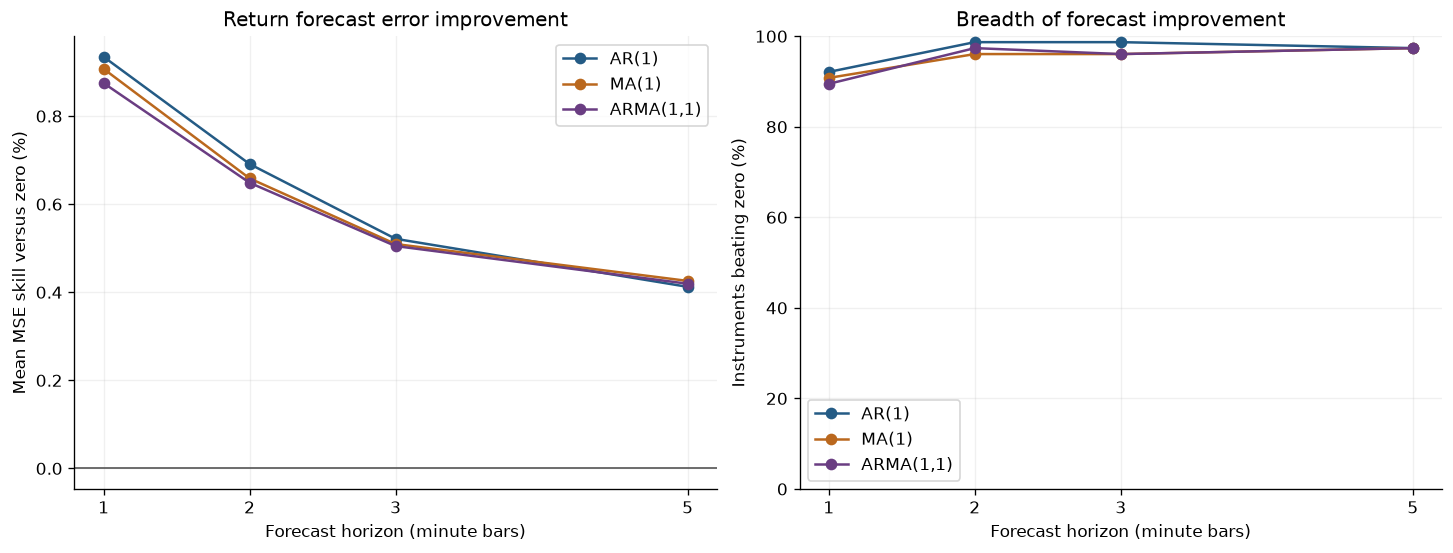

model,horizon,period,files,Mean MSE skill,Median MSE skill
Zero,1,First evaluation half,76,0.000000,0.000000
Zero,1,Second evaluation half,76,0.000000,0.000000
Training mean,1,First evaluation half,76,-0.000005,-0.000000
Training mean,1,Second evaluation half,76,-0.000007,-0.000004
AR(1),1,First evaluation half,76,0.011616,0.008059
AR(1),1,Second evaluation half,76,0.007223,0.006463
MA(1),1,First evaluation half,76,0.011336,0.007582
MA(1),1,Second evaluation half,76,0.007014,0.005810
"ARMA(1,1)",1,First evaluation half,76,0.011220,0.007628
"ARMA(1,1)",1,Second evaluation half,76,0.006507,0.005229


In [27]:
mean_summary = mean_model_metrics.groupby(["model", "horizon"], sort=False).agg(
    instruments=("file", "nunique"), observations=("observations", "sum"),
    mean_mse_skill_zero=("mse_skill_zero", "mean"), median_mse_skill_zero=("mse_skill_zero", "median"),
    files_better_than_zero=("mse_skill_zero", lambda values: int((values > 0).sum())),
    mean_mse_skill_mean=("mse_skill_mean", "mean"), median_mse_skill_mean=("mse_skill_mean", "median"),
    files_better_than_mean=("mse_skill_mean", lambda values: int((values > 0).sum())),
    median_sign_accuracy=("sign_accuracy", "median"), median_zero_target_share=("zero_target_share", "median"),
    median_forecast_correlation=("forecast_target_correlation", "median"),
    median_gross_signed_return=("gross_signed_return_mean", "median")).reset_index()
mean_summary.to_csv(MODEL_OUTPUT_DIR/"mean_forecast_summary.csv", index=False)
mean_view = mean_summary[["model", "horizon", "instruments", "mean_mse_skill_zero", "median_mse_skill_zero",
                         "files_better_than_zero", "median_sign_accuracy"]].copy()
for column in ["mean_mse_skill_zero", "median_mse_skill_zero", "median_sign_accuracy"]:
    mean_view[column] *= 100
mean_view.columns = ["Model", "Horizon", "Files", "Mean skill (%)", "Median skill (%)", "Beats zero", "Sign accuracy (%)"]
show_table(mean_view, "Return forecasts: skill against zero; equal instrument weights", rows=20)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for name in MEAN_MODEL_ORDERS:
    part = mean_summary.loc[mean_summary.model.eq(name)].sort_values("horizon")
    axes[0].plot(part.horizon, 100*part.mean_mse_skill_zero, marker="o", label=name, color=MODEL_COLORS[name])
    axes[1].plot(part.horizon, 100*part.files_better_than_zero/part.instruments, marker="o", label=name, color=MODEL_COLORS[name])
axes[0].axhline(0, color="#555555", linewidth=1)
axes[0].set(title="Return forecast error improvement", ylabel="Mean MSE skill versus zero (%)")
axes[1].set(title="Breadth of forecast improvement", ylabel="Instruments beating zero (%)", ylim=(0, 100))
for ax in axes:
    ax.set_xlabel("Forecast horizon (minute bars)"); ax.set_xticks(MEAN_FORECAST_HORIZONS); ax.legend()
fig.savefig(MODEL_OUTPUT_DIR/"mean_forecast_comparison.png", dpi=160)
plt.show()
stability = model_period_metrics.groupby(["model", "horizon", "period"], sort=False).agg(
    files=("file", "nunique"), mean_skill=("mse_skill_zero", "mean"), median_skill=("mse_skill_zero", "median")).reset_index()
stability.to_csv(MODEL_OUTPUT_DIR/"mean_period_summary.csv", index=False)
show_table(stability.loc[stability.horizon.eq(1)].rename(columns={"mean_skill": "Mean MSE skill", "median_skill": "Median MSE skill"}),
           "One-minute return forecast stability: both evaluation halves", rows=10)

### Variance forecast results
A negative QLIKE difference means the model improves on its benchmark. Compare GARCH with all three benchmarks on identical origins and horizons, including a current-volatility benchmark rather than only a constant. A high correlation alone is not sufficient: forecasts may be systematically too high or too low.

The trailing-variance benchmark can be zero after inactive bars; its QLIKE is consequently sensitive to the scoring floor. It remains in all tables and the correlation chart, but is omitted from the loss chart to avoid compressing GARCH/EWMA differences. The sensitivity table below keeps the same observations and varies only this numerical floor.

Report the worst file-level loss changes as well as medians: a few severe underpredictions can reverse the equal-file mean. Correlations at different horizons are not directly comparable because averaging makes the realized-variance proxy less noisy.

Model,Horizon,Files,Median QLIKE change,Median correlation,Actual / forecast,Floored
Historical variance,1,76,0.000000,NA,0.799179,0
Trailing 30m,1,76,10273.168315,0.190682,0.923981,1711522
EWMA,1,76,-0.281890,0.232196,0.913702,0
"GARCH(1,1)",1,76,-0.354597,0.247815,0.952513,0
Historical variance,5,76,0.000000,NA,0.765157,0
Trailing 30m,5,76,32777.366567,0.315790,0.906009,1562972
EWMA,5,76,-0.253017,0.365600,0.894272,0
"GARCH(1,1)",5,76,-0.317034,0.361273,0.930815,0
Historical variance,30,76,0.000000,NA,0.751879,0
Trailing 30m,30,76,59265.432097,0.433926,0.828714,631659


Horizon,Files,Beats constant,Beats trailing,Beats EWMA,QLIKE vs trailing,QLIKE vs EWMA
1,76,72,76,51,-10273.602491,-0.009412
5,76,71,76,45,-32777.569180,-0.003615
30,76,73,73,40,-59265.698620,-0.004199


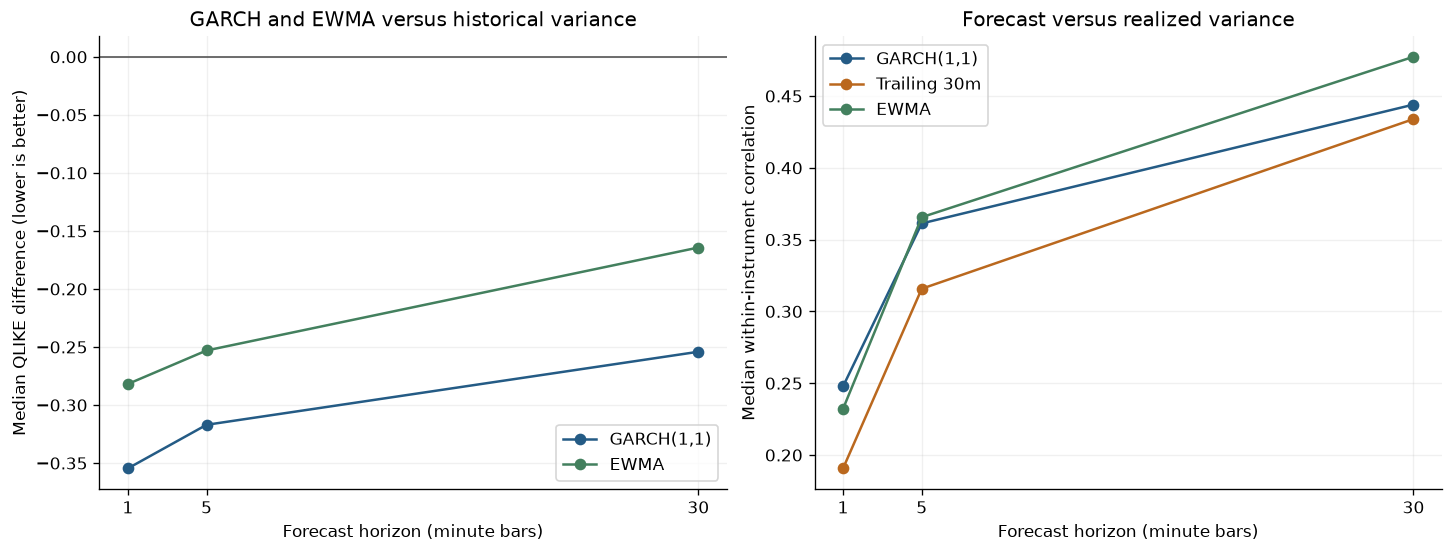

Instrument,Origins,QLIKE vs constant,QLIKE vs EWMA,Actual / forecast
FG9999.XZCE.csv,183045,43.852119,43.972679,0.974121
FU9999.XSGE.csv,164610,2.110318,-12.977840,1.224576
PM9999.XZCE.csv,70155,0.219146,-23.529253,1.624871
ER9999.XZCE.csv,31320,-0.057430,0.177009,1.190288
RS9999.XZCE.csv,65745,-0.064840,-34.253859,1.920972


Showing 5 of 76 rows; the complete table is exported.


In [28]:
variance_summary = variance_model_metrics.groupby(["model", "horizon"], sort=False).agg(
    instruments=("file", "nunique"), observations=("observations", "sum"),
    mean_qlike_difference_historical=("qlike_difference_historical", "mean"),
    median_qlike_difference_historical=("qlike_difference_historical", "median"),
    mean_qlike_difference_trailing30=("qlike_difference_trailing30", "mean"),
    median_qlike_difference_trailing30=("qlike_difference_trailing30", "median"),
    mean_qlike_difference_ewma=("qlike_difference_ewma", "mean"),
    median_qlike_difference_ewma=("qlike_difference_ewma", "median"),
    files_better_than_historical=("qlike_difference_historical", lambda values: int((values < 0).sum())),
    files_better_than_trailing30=("qlike_difference_trailing30", lambda values: int((values < 0).sum())),
    files_better_than_ewma=("qlike_difference_ewma", lambda values: int((values < 0).sum())),
    median_variance_correlation=("forecast_target_correlation", "median"),
    mean_variance_mse_skill=("mse_skill_historical", "mean"), median_variance_mse_skill=("mse_skill_historical", "median"),
    median_realized_to_forecast=("realized_to_forecast_ratio", "median"),
    forecast_floored_count=("forecast_floored_count", "sum")).reset_index()
variance_summary.to_csv(MODEL_OUTPUT_DIR/"variance_forecast_summary.csv", index=False)
variance_view = variance_summary[["model", "horizon", "instruments", "median_qlike_difference_historical",
    "median_variance_correlation", "median_realized_to_forecast", "forecast_floored_count"]].copy()
variance_view.columns = ["Model", "Horizon", "Files", "Median QLIKE change", "Median correlation", "Actual / forecast", "Floored"]
show_table(variance_view, "Variance forecasts: QLIKE change versus historical variance", rows=12)
garch_comparison = variance_summary.loc[variance_summary.model.eq("GARCH(1,1)"), ["horizon", "instruments",
    "files_better_than_historical", "files_better_than_trailing30", "files_better_than_ewma",
    "median_qlike_difference_trailing30", "median_qlike_difference_ewma"]].copy()
garch_comparison.columns = ["Horizon", "Files", "Beats constant", "Beats trailing", "Beats EWMA", "QLIKE vs trailing", "QLIKE vs EWMA"]
show_table(garch_comparison, "GARCH: paired instrument comparisons on common evaluation origins")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for name in ["GARCH(1,1)", "Trailing 30m", "EWMA"]:
    part = variance_summary.loc[variance_summary.model.eq(name)].sort_values("horizon")
    if name != "Trailing 30m":
        axes[0].plot(part.horizon, part.median_qlike_difference_historical, marker="o", label=name, color=MODEL_COLORS[name])
    axes[1].plot(part.horizon, part.median_variance_correlation, marker="o", label=name, color=MODEL_COLORS[name])
axes[0].axhline(0, color="#555555", linewidth=1)
axes[0].set(title="GARCH and EWMA versus historical variance", ylabel="Median QLIKE difference (lower is better)")
axes[1].set(title="Forecast versus realized variance", ylabel="Median within-instrument correlation")
for ax in axes:
    ax.set_xlabel("Forecast horizon (minute bars)"); ax.set_xticks(VARIANCE_FORECAST_HORIZONS); ax.legend()
fig.savefig(MODEL_OUTPUT_DIR/"variance_forecast_comparison.png", dpi=160)
plt.show()
variance_tail_view = variance_model_metrics.loc[variance_model_metrics.model.eq("GARCH(1,1)")
    & variance_model_metrics.horizon.eq(30)].sort_values("qlike_difference_historical", ascending=False)
show_table(variance_tail_view[["file", "observations", "qlike_difference_historical", "qlike_difference_ewma",
    "realized_to_forecast_ratio"]].rename(columns={"file": "Instrument", "observations": "Origins",
    "qlike_difference_historical": "QLIKE vs constant", "qlike_difference_ewma": "QLIKE vs EWMA",
    "realized_to_forecast_ratio": "Actual / forecast"}),
    "Largest GARCH loss increases: 30-minute horizon; all observations retained", rows=5)


### QLIKE floor sensitivity and parameter diagnostics
Evaluate the same saved predictions at floor ratios 1e-8, 1e-6, 1e-4 and 1e-2 of the calibration variance. No refitting, observation removal or target modification takes place. A conclusion against trailing variance that changes with this floor is not robust. EWMA provides an additional dynamic comparison.

Boundary GARCH estimates and near-cancelling ARMA coefficients are diagnostics, not automatic reasons to delete a model. Parameter persistence close to one can also signal regime changes or model misspecification under the fixed calibration design.

In [29]:
floor_sensitivity_rows = []
for _, coverage_row in model_coverage.loc[model_coverage.status.eq("eligible")].iterrows():
    filename = coverage_row.file
    columns = []
    for horizon in VARIANCE_FORECAST_HORIZONS:
        columns += [f"variance_evaluation_h{horizon}", f"future_variance_{horizon}",
                    *[f"variance_{name}_h{horizon}" for name in ["GARCH(1,1)", "Trailing 30m", "EWMA"]]]
    predicted = pd.read_parquet(model_forecast_dir/(Path(filename).stem+".parquet"), columns=columns)
    for horizon in VARIANCE_FORECAST_HORIZONS:
        eligible = predicted[f"variance_evaluation_h{horizon}"].to_numpy()
        target = predicted.loc[eligible, f"future_variance_{horizon}"].to_numpy()
        forecasts_here = {name: predicted.loc[eligible, f"variance_{name}_h{horizon}"].to_numpy()
                          for name in ["GARCH(1,1)", "Trailing 30m", "EWMA"]}
        if not len(target) or not all(np.isfinite(values).all() for values in forecasts_here.values()):
            continue
        for ratio in [1e-8, 1e-6, 1e-4, 1e-2]:
            floor = ratio * coverage_row.training_std**2
            losses = {name: np.mean(np.log(np.maximum(values, floor)) + target/np.maximum(values, floor))
                      for name, values in forecasts_here.items()}
            floor_sensitivity_rows.append(dict(file=filename, horizon=horizon, floor_ratio=ratio,
                qlike_garch_minus_trailing=losses["GARCH(1,1)"]-losses["Trailing 30m"],
                qlike_garch_minus_ewma=losses["GARCH(1,1)"]-losses["EWMA"],
                trailing_zero_count=int((forecasts_here["Trailing 30m"] == 0).sum()), observations=len(target)))
floor_sensitivity = pd.DataFrame(floor_sensitivity_rows)
floor_sensitivity.to_csv(MODEL_OUTPUT_DIR/"qlike_floor_sensitivity_by_instrument.csv", index=False)
floor_summary = floor_sensitivity.groupby(["horizon", "floor_ratio"], sort=True).agg(
    files=("file", "nunique"), median_vs_trailing=("qlike_garch_minus_trailing", "median"),
    beats_trailing=("qlike_garch_minus_trailing", lambda values: int((values < 0).sum())),
    median_vs_ewma=("qlike_garch_minus_ewma", "median"),
    beats_ewma=("qlike_garch_minus_ewma", lambda values: int((values < 0).sum()))).reset_index()
floor_summary.to_csv(MODEL_OUTPUT_DIR/"qlike_floor_sensitivity_summary.csv", index=False)
floor_view = floor_summary.copy()
floor_view["floor_ratio"] = floor_view.floor_ratio.map(lambda value: f"{value:.0e}")
floor_view.columns = ["Horizon", "Floor ratio", "Files", "Median vs trailing", "Beats trailing", "Median vs EWMA", "Beats EWMA"]
show_table(floor_view, "QLIKE sensitivity: GARCH minus each benchmark", rows=12)
parameter_view = model_fits.loc[model_fits.success].groupby("model", sort=False).agg(
    files=("file", "size"), median_phi=("phi", "median"), median_theta=("theta", "median"),
    median_alpha=("alpha", "median"), median_beta=("beta", "median"),
    median_persistence=("persistence", "median"), boundary_fits=("boundary", "sum"),
    near_cancellation=("near_cancellation", "sum")).reset_index()
parameter_view.to_csv(MODEL_OUTPUT_DIR/"parameter_summary.csv", index=False)
show_table(parameter_view, "Estimated parameters: calibration only", rows=4)


Horizon,Floor ratio,Files,Median vs trailing,Beats trailing,Median vs EWMA,Beats EWMA
1,1e-08,76,-10273.602491,76,-0.009412,51
1,1e-06,76,-102.760114,75,-0.009412,51
1,1e-04,76,-1.059787,73,-0.009412,52
1,1e-02,76,-0.056366,67,-0.007891,49
5,1e-08,76,-32777.569180,76,-0.003615,45
5,1e-06,76,-327.785301,75,-0.003615,45
5,1e-04,76,-2.933596,74,-0.003615,45
5,1e-02,76,-0.062376,64,-0.003051,41
30,1e-08,76,-59265.698620,73,-0.004199,40
30,1e-06,76,-592.429585,71,-0.004199,40


model,files,median_phi,median_theta,median_alpha,median_beta,median_persistence,boundary_fits,near_cancellation
AR(1),76,-0.097174,0.000000,NA,NA,NA,0,0
MA(1),76,0.000000,-0.098454,NA,NA,NA,0,0
"ARMA(1,1)",76,-0.070834,-0.019103,NA,NA,NA,0,3
"GARCH(1,1)",76,NA,NA,0.100724,0.880078,0.979931,11,0


### Inspect cross-instrument variation and a chronological example
The example uses the alphabetically first eligible file with a successful GARCH fit and its first evaluation date with at least 30 comparable forecast origins. Selection depends on availability, not evaluation performance. Plot forecasts at their actual intraday origins against the next 30 minutes of realized variance; gaps and unavailable targets stay blank. Daily aggregates are retained as a separate export, not used to demonstrate minute-level forecast quality.

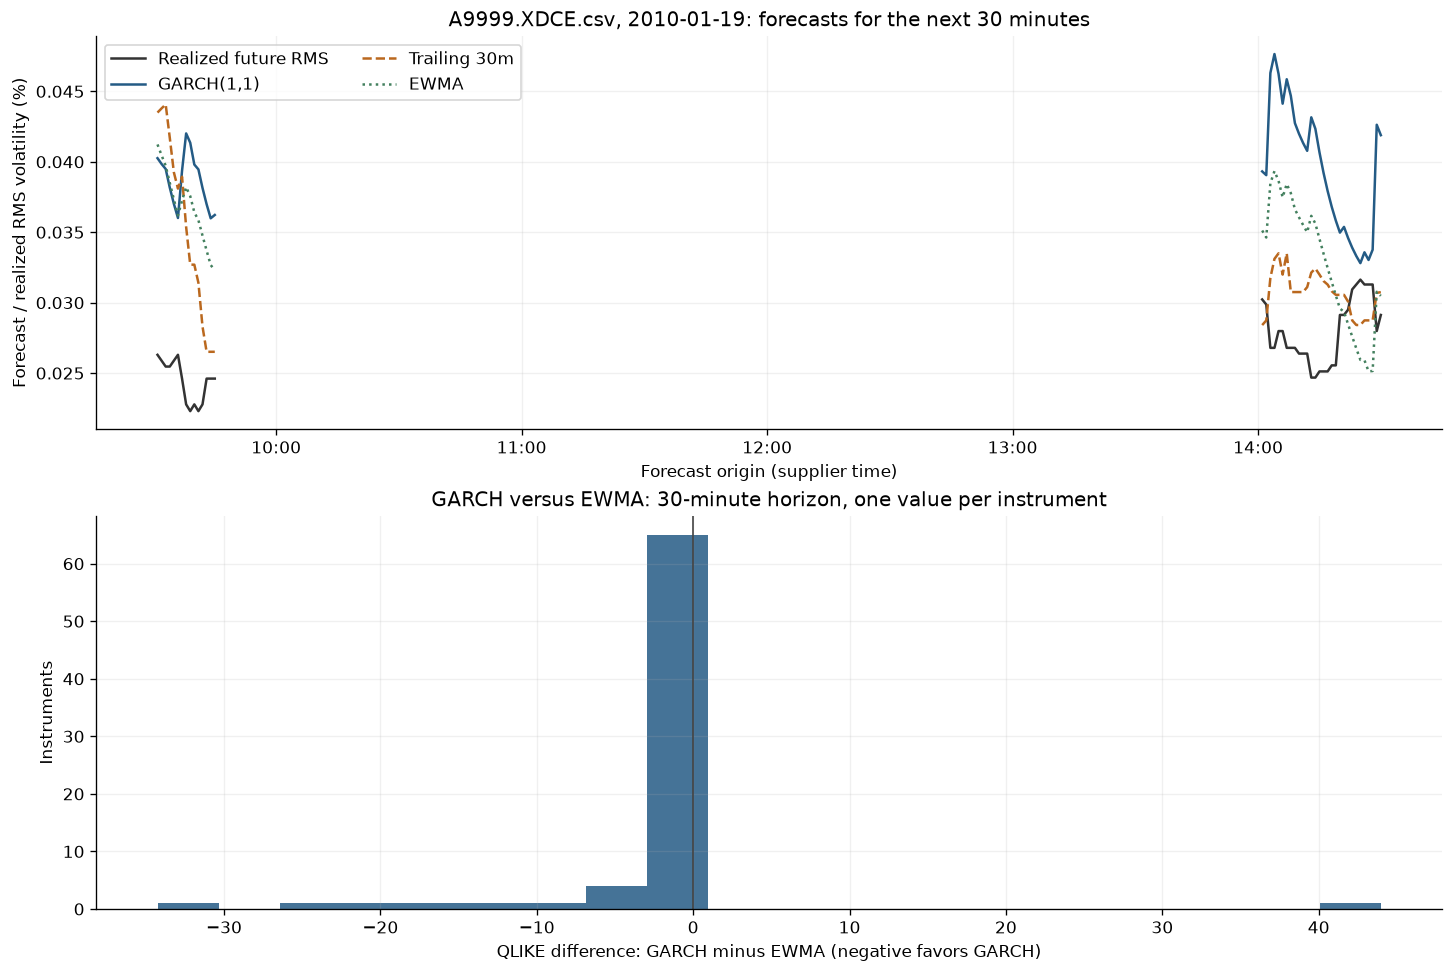

In [30]:
garch_by_file = variance_model_metrics.loc[variance_model_metrics.model.eq("GARCH(1,1)") & variance_model_metrics.horizon.eq(30)]
example_files = sorted(garch_by_file.file.unique())
if example_files:
    example_file = example_files[0]
    from matplotlib.dates import DateFormatter
    example = pd.read_parquet(model_forecast_dir/(Path(example_file).stem+".parquet"))
    available = example.loc[example.variance_evaluation_h30].groupby(example.date.dt.normalize()).size()
    example_date = available.loc[available >= 30].index[0]
    example = example.loc[example.date.dt.normalize().eq(example_date)].copy()
    visible = example.variance_evaluation_h30
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
    axes[0].plot(example.date, np.sqrt(example.future_variance_30.where(visible))*100,
                 color="#333333", linewidth=1.5, label="Realized future RMS")
    for name, linestyle in [("GARCH(1,1)", "-"), ("Trailing 30m", "--"), ("EWMA", ":")]:
        axes[0].plot(example.date, np.sqrt(example[f"variance_{name}_h30"].where(visible))*100,
                     linewidth=1.5, linestyle=linestyle, color=MODEL_COLORS[name], label=name)
    axes[0].set(title=f"{example_file}, {example_date.date()}: forecasts for the next 30 minutes",
                xlabel="Forecast origin (supplier time)", ylabel="Forecast / realized RMS volatility (%)")
    axes[0].xaxis.set_major_formatter(DateFormatter("%H:%M"))
    axes[0].legend(ncol=2)
    axes[1].hist(garch_by_file.qlike_difference_ewma, bins=20, color=MODEL_COLORS["GARCH(1,1)"], alpha=.85)
    axes[1].axvline(0, color="#444444", linewidth=1)
    axes[1].set(title="GARCH versus EWMA: 30-minute horizon, one value per instrument",
                xlabel="QLIKE difference: GARCH minus EWMA (negative favors GARCH)", ylabel="Instruments")
    fig.savefig(MODEL_OUTPUT_DIR/"variance_example_and_consistency.png", dpi=160)
    plt.show()

### Time-series research conclusions
Conclusions below are generated from the executed evaluation tables. They describe forecast error and cross-instrument consistency, not a claim of executable net trading profitability. Forecast-parameter uncertainty, structural breaks and heteroskedasticity remain material; a Gaussian likelihood is not a Gaussian-data assertion.

In [31]:
model_conclusions = []
for name in MEAN_MODEL_ORDERS:
    one = mean_summary.loc[mean_summary.model.eq(name) & mean_summary.horizon.eq(1)]
    if one.empty:
        model_conclusions.append(f"**{name}:** no successful evaluation; inspect the fit report.")
        continue
    one = one.iloc[0]
    model_conclusions.append(f"**{name}:** one-minute mean MSE skill versus zero is {100*one.mean_mse_skill_zero:.3f}% "
        f"(instrument median {100*one.median_mse_skill_zero:.3f}%); {int(one.files_better_than_zero)}/{int(one.instruments)} "
        f"instruments improve. Against the training-mean forecast, {int(one.files_better_than_mean)}/{int(one.instruments)} "
        f"improve. Median sign accuracy among nonzero targets is {100*one.median_sign_accuracy:.2f}%. "
        "Inspect horizon and evaluation-half tables before interpreting this as stable directional predictability.")
for _, row in variance_summary.loc[variance_summary.model.eq("GARCH(1,1)")].iterrows():
    model_conclusions.append(f"**GARCH, {int(row.horizon)} minutes:** QLIKE improves on historical variance in "
        f"{int(row.files_better_than_historical)}/{int(row.instruments)} instruments, on trailing-30-minute variance in "
        f"{int(row.files_better_than_trailing30)}/{int(row.instruments)}, and on EWMA in "
        f"{int(row.files_better_than_ewma)}/{int(row.instruments)}. Median QLIKE differences are "
        f"{row.median_qlike_difference_trailing30:.4f} versus trailing variance and {row.median_qlike_difference_ewma:.4f} "
        f"versus EWMA (negative is better). Median origin-level forecast/realized-variance correlation is "
        f"{row.median_variance_correlation:.3f}. Equal-file mean QLIKE change versus constant variance is "
        f"{row.mean_qlike_difference_historical:.4f}, while the median is {row.median_qlike_difference_historical:.4f}; "
        "large disagreement exposes tail sensitivity. These are forecasts of movement magnitude, not its sign.")
for horizon in VARIANCE_FORECAST_HORIZONS:
    sensitivity = floor_summary.loc[floor_summary.horizon.eq(horizon)]
    model_conclusions.append(f"**QLIKE floor sensitivity, {horizon} minutes:** GARCH beats trailing variance in "
        f"{int(sensitivity.beats_trailing.min())}-{int(sensitivity.beats_trailing.max())} instruments across the four floors, "
        f"and beats EWMA in {int(sensitivity.beats_ewma.min())}-{int(sensitivity.beats_ewma.max())}. "
        "Use this range alongside the default-floor result; very large gains against a zero trailing variance are floor-sensitive.")
model_conclusions.append(f"**Parameter diagnostics:** {int(model_fits.loc[model_fits.model.eq('GARCH(1,1)'), 'boundary'].fillna(False).sum())} "
    "GARCH fits are near the imposed parameter bounds; inspect the parameter report and individual forecast losses before deployment. "
    "Better median performance does not imply uniform improvement across instruments.")
model_conclusions.append("**Limits:** parameters are fixed after the initial calibration period; results are descriptive chronological-holdout comparisons, "
    "not independent post-selection significance tests. All comparisons retain zero returns and extreme observations; only forecast availability "
    "and explicit calibration eligibility affect coverage. A positive directional event return can coexist with poor MSE skill.")
for paragraph in model_conclusions:
    display(Markdown(paragraph))
(MODEL_OUTPUT_DIR/"model_conclusions.md").write_text("# Time-series forecast findings\n\n"+"\n\n".join(model_conclusions)+"\n")
model_parameters = {"input_features": str(FEATURE_PATH), "input_sha256": source_hashes[str(FEATURE_PATH)],
    "calibration_fraction": CALIBRATION_FRACTION, "mean_models": MEAN_MODEL_ORDERS,
    "mean_horizons": MEAN_FORECAST_HORIZONS, "variance_horizons": VARIANCE_FORECAST_HORIZONS,
    "mean_definition": "fixed training mean; conditional Gaussian least squares on segment-reset innovations",
    "garch_definition": "fixed training mean; Gaussian QML; initial standardized variance=1 at each finite run",
    "minimum_training_returns": MODEL_MIN_TRAIN_RETURNS, "minimum_training_dates": MODEL_MIN_TRAIN_DATES,
    "ewma_decay": EWMA_DECAY, "variance_floor_ratio": VARIANCE_FLOOR_RATIO,
    "coefficient_bound": MODEL_COEFFICIENT_BOUND, "parameters_refitted_during_evaluation": False,
    "preprocessing_changed": False, "observations_winsorized": False, "statistical_significance_claimed": False,
    "eligible_instruments": int(model_coverage.status.eq("eligible").sum()),
    "raw_instruments": len(files), "random_seed": RANDOM_SEED}
(MODEL_OUTPUT_DIR/"model_parameters.json").write_text(json.dumps(model_parameters, indent=2)+"\n")
assert file_hash(FEATURE_PATH) == source_hashes[str(FEATURE_PATH)]
print(f"Saved model fits, coverage, forecast metrics, origin-level predictions and figures to {MODEL_OUTPUT_DIR}")
print("The original strategy_hypothesis_results.csv retains its original four-family experiment.")

**AR(1):** one-minute mean MSE skill versus zero is 0.935% (instrument median 0.704%); 70/76 instruments improve. Against the training-mean forecast, 70/76 improve. Median sign accuracy among nonzero targets is 56.75%. Inspect horizon and evaluation-half tables before interpreting this as stable directional predictability.

**MA(1):** one-minute mean MSE skill versus zero is 0.907% (instrument median 0.648%); 69/76 instruments improve. Against the training-mean forecast, 69/76 improve. Median sign accuracy among nonzero targets is 57.35%. Inspect horizon and evaluation-half tables before interpreting this as stable directional predictability.

**ARMA(1,1):** one-minute mean MSE skill versus zero is 0.875% (instrument median 0.627%); 68/76 instruments improve. Against the training-mean forecast, 68/76 improve. Median sign accuracy among nonzero targets is 56.43%. Inspect horizon and evaluation-half tables before interpreting this as stable directional predictability.

**GARCH, 1 minutes:** QLIKE improves on historical variance in 72/76 instruments, on trailing-30-minute variance in 76/76, and on EWMA in 51/76. Median QLIKE differences are -10273.6025 versus trailing variance and -0.0094 versus EWMA (negative is better). Median origin-level forecast/realized-variance correlation is 0.248. Equal-file mean QLIKE change versus constant variance is -0.2017, while the median is -0.3546; large disagreement exposes tail sensitivity. These are forecasts of movement magnitude, not its sign.

**GARCH, 5 minutes:** QLIKE improves on historical variance in 71/76 instruments, on trailing-30-minute variance in 76/76, and on EWMA in 45/76. Median QLIKE differences are -32777.5692 versus trailing variance and -0.0036 versus EWMA (negative is better). Median origin-level forecast/realized-variance correlation is 0.361. Equal-file mean QLIKE change versus constant variance is 0.0268, while the median is -0.3170; large disagreement exposes tail sensitivity. These are forecasts of movement magnitude, not its sign.

...

**QLIKE floor sensitivity, 5 minutes:** GARCH beats trailing variance in 64-76 instruments across the four floors, and beats EWMA in 41-45. Use this range alongside the default-floor result; very large gains against a zero trailing variance are floor-sensitive.

**QLIKE floor sensitivity, 30 minutes:** GARCH beats trailing variance in 55-73 instruments across the four floors, and beats EWMA in 38-40. Use this range alongside the default-floor result; very large gains against a zero trailing variance are floor-sensitive.

**Parameter diagnostics:** 11 GARCH fits are near the imposed parameter bounds; inspect the parameter report and individual forecast losses before deployment. Better median performance does not imply uniform improvement across instruments.

**Limits:** parameters are fixed after the initial calibration period; results are descriptive chronological-holdout comparisons, not independent post-selection significance tests. All comparisons retain zero returns and extreme observations; only forecast availability and explicit calibration eligibility affect coverage. A positive directional event return can coexist with poor MSE skill.

Saved model fits, coverage, forecast metrics, origin-level predictions and figures to artifacts/strategies/time_series_models
The original strategy_hypothesis_results.csv retains its original four-family experiment.


## Two-layer walk-forward architecture

Use $r_t=\mu_t+\sigma_t z_t$. ARMA and logistic models estimate directional information; GARCH-family models estimate conditional volatility. An asymmetry coefficient is **not** a forecast of return sign.

### Protocol and timing
The common research window begins in 2015; earlier observations remain in the preserved studies above. Initial warm-up is at least 60 observed calendar dates; the trailing training window is 252 observed dates, refitted every 63 dates. Validation is 2018-2019 and the new locked evaluation starts in 2020. ARMA order is selected once by training BIC and frozen before 2020. Coefficients may subsequently update using settled past data. Logistic feature lists and regularization are fixed; trading thresholds are selected on validation only.

**Holdout limitation:** all available data through October 2021 were examined in earlier project research. This new split isolates model selection inside the current experiment, but is not a genuinely never-seen historical holdout. Confirmation requires newer data.

At close $t$, forecasts use information through $t$. A scheduled order can enter at close $t+1$ and exits at close $t+6$: five minutes of exposure. Direction targets are $\log(P_{t+6}/P_{t+1})$; trading uses the corresponding simple return. Forecast cumulative variance sums steps **2 through 6**, excluding the execution delay. Calendar-clock origins every six minutes make positions nonoverlapping and leave one flat minute. No annualization is applied to a bar-level forecast.

The user selected **5 minutes and 1 bp per side**. A 0.1% five-minute volatility target, leverage cap 3, floor 0.001%, prior-30-bar expansion denominator and fixed 1.2 expansion threshold are transparent research settings, not fitted exchange rules. Nearby settings and 0/0.5/1/2 bp are diagnostics, not holdout reselection. No funding series, contract multipliers or margin rules are supplied: funding is excluded and exposures are normalized futures notional, not a contract execution simulation.

In [32]:
from numba import njit
from scipy.special import expit
from scipy.stats import rankdata, spearmanr
from scipy.optimize import minimize
import itertools
import time
import warnings

WF_DIR = OUTPUT_DIR / "two_layer_walk_forward"
WF_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_WINDOW = 252
EXPANDING_OR_ROLLING = "rolling"
REFIT_FREQUENCY = 63
FORECAST_HORIZON = 5
EXECUTION_DELAY = 1
MIN_TRAIN_DAYS = 60
MIN_DIRECTION_ROWS = 1000
RESEARCH_START = pd.Timestamp("2015-01-01")
VALIDATION_START = pd.Timestamp("2018-01-01")
HOLDOUT_START = pd.Timestamp("2020-01-01")
TARGET_VOL = 0.001
MAX_LEVERAGE = 3.0
MIN_VOL_FLOOR = 0.00001
COST_BPS = 1.0
COST_GRID_BPS = [0.0, 0.5, 1.0, 2.0]
PROBABILITY_THRESHOLDS = [0.50, 0.55, 0.60, 0.65]
EXPANSION_THRESHOLD = 1.2
EXPANSION_WINDOW = 30
EXPANSION_MIN_PERIODS = 15
BREAKOUT_WINDOW = 20
EGARCH_SIMULATIONS = 2048
BOOTSTRAP_REPLICATIONS = 300
BOOTSTRAP_BLOCK_DAYS = 5
ARMA_CANDIDATES = [(1, 0), (2, 0), (1, 1)]
DIRECTION_NAMES = ["D0_Baseline", "D1_ARMA_Raw_Returns", "D2_ARMA_Standardized_GARCH",
    "D2_ARMA_Standardized_EGARCH", "D2_ARMA_Standardized_GJR", "D3_Logistic_Direction", "D3_Logistic_Asymmetric"]
VOLATILITY_NAMES = ["V1_GARCH", "V2_EGARCH", "V3_GJR_GARCH"]
WF_CONFIG = dict(train_window=TRAIN_WINDOW, mode=EXPANDING_OR_ROLLING, refit_frequency=REFIT_FREQUENCY,
    horizon=FORECAST_HORIZON, execution_delay=EXECUTION_DELAY, min_train_days=MIN_TRAIN_DAYS,
    min_direction_rows=MIN_DIRECTION_ROWS, research_start=str(RESEARCH_START), validation_start=str(VALIDATION_START),
    holdout_start=str(HOLDOUT_START), target_vol=TARGET_VOL, max_leverage=MAX_LEVERAGE, min_vol=MIN_VOL_FLOOR,
    cost_bps=COST_BPS, probability_thresholds=PROBABILITY_THRESHOLDS, expansion=EXPANSION_THRESHOLD,
    simulations=EGARCH_SIMULATIONS, seed=RANDOM_SEED, arma_candidates=ARMA_CANDIDATES)

### Volatility estimation and asymmetric responses
Gaussian conditional quasi-likelihood is fitted on centered returns scaled by **training-only** mean/STD, with variance initialized to that historical scale at each segment. Standard GARCH reuses the existing estimator. EGARCH estimates $\log h_t=\omega+\beta\log h_{t-1}+\alpha(|z_{t-1}|-\sqrt{2/\pi})+\gamma z_{t-1}$. GJR estimates $h_t=\omega+\alpha\epsilon^2_{t-1}+\gamma I(\epsilon_{t-1}<0)\epsilon^2_{t-1}+\beta h_{t-1}$. GJR permits either asymmetry sign while constraining both shock loadings nonnegative and expected persistence below one. Parameters, likelihood, AIC/BIC and numerical guard hits are exported. The volatility layer retains the existing constant training mean; it is not a joint ARMA-GARCH likelihood. Summed marginal variances approximate holding-period variance and do not add an ARMA-induced covariance term.

GARCH/GJR multistep expected variance uses its analytic recursion. EGARCH uses 2,048 antithetic Gaussian paths with common random numbers, factorized through its affine log-variance recursion. Exponentiating an expected log variance would be incorrect. Filtered-state guard hits and next-log-variance bounds are audited; exponent safety bounds do not delete market observations. Failed fits remain missing and reduce reported coverage.

Specifications and forecast conventions follow the [EGARCH definition](https://arch.readthedocs.io/en/latest/univariate/generated/arch.univariate.EGARCH.html), [GJR specification](https://arch.readthedocs.io/en/stable/univariate/univariate_volatility_modeling.html), and [multistep forecasting distinction](https://arch.readthedocs.io/en/latest/univariate/forecasting.html). The implementation below is self-contained.

In [33]:
@njit
def wf_variance_kernel(x, reset, parameters, kind, gradient=False):
    # kind 0: symmetric GARCH, 1: EGARCH, 2: GJR with positive/negative shock loadings.
    n = len(x)
    variance = np.full(n, np.nan)
    derivatives = np.zeros(4)
    grad = np.zeros(4)
    hprev = 1.0
    uprev = 0.0
    active = False
    loss = 0.0
    count = 0
    clipped = 0
    for i in range(n):
        if not np.isfinite(x[i]):
            active = False
            continue
        fresh = reset[i] or not active
        if fresh:
            h = 1.0
            derivatives[:] = 0.0
        elif kind == 1:
            omega, alpha, beta, gamma = parameters
            z = uprev / np.sqrt(hprev)
            log_previous = np.log(hprev)
            log_h = omega + beta*log_previous + alpha*(abs(z)-np.sqrt(2/np.pi)) + gamma*z
            propagation = beta - 0.5*z*(alpha*np.sign(z)+gamma)
            derivatives *= propagation
            derivatives[0] += 1.0
            derivatives[1] += abs(z)-np.sqrt(2/np.pi)
            derivatives[2] += log_previous
            derivatives[3] += z
            if log_h < -30 or log_h > 30:
                log_h = max(-30.0, min(30.0, log_h)); derivatives[:] = 0.0; clipped += 1
            h = np.exp(log_h)
        else:
            omega, positive, negative, beta = parameters
            shock_coefficient = positive if uprev >= 0 else negative
            h = omega + shock_coefficient*uprev*uprev + beta*hprev
            derivatives *= beta
            derivatives[0] += 1.0
            derivatives[1 if uprev >= 0 else 2] += uprev*uprev
            derivatives[3] += hprev
        variance[i] = h
        if not fresh:
            loss += 0.5*(np.log(h) + x[i]*x[i]/h)
            score = 0.5*(1.0-x[i]*x[i]/h) if kind == 1 else 0.5*(1/h-x[i]*x[i]/(h*h))
            grad += score*derivatives
            count += 1
        uprev, hprev, active = x[i], h, True
    return variance, loss/max(count, 1), grad/max(count, 1), count, clipped

def wf_gjr_transform(raw):
    omega = np.exp(raw[0])
    weights = np.exp(np.r_[0.0, raw[1:]]-max(0.0, *raw[1:]))
    shares = weights/weights.sum()
    loads = .999*shares[1:]
    p = np.array([omega, 2*loads[0], 2*loads[1], loads[2]])
    jac = np.zeros((4, 4)); jac[0, 0] = omega
    for i in range(3):
        for j in range(3):
            jac[i+1, j+1] = p[i+1]*((i == j)-shares[j+1])
    return p, jac

def wf_gjr_objective(raw, x, reset):
    physical, jac = wf_gjr_transform(raw)
    _, loss, derivative, _, _ = wf_variance_kernel(x, reset, physical, 2)
    return loss, derivative @ jac

def wf_egarch_objective(parameters, x, reset):
    _, loss, derivative, _, _ = wf_variance_kernel(x, reset, parameters, 1)
    return loss, derivative

def wf_fit_volatility(values, segments, model, previous=None):
    finite = np.isfinite(values)
    location, scale = np.mean(values[finite]), np.std(values[finite])
    if finite.sum() < MIN_DIRECTION_ROWS or not np.isfinite(scale) or scale <= 0:
        return None
    x = (values-location)/scale
    reset = np.r_[True, segments[1:] != segments[:-1]]
    if model == "V1_GARCH":
        matrix, positions, _ = return_run_matrix(x, segments)
        old = fit_garch(matrix, positions)
        if not old["success"]: return None
        parameters = np.array([old["omega"], old["alpha"], old["alpha"], old["beta"]])
        kind, k = 0, 4
        raw = None
        success = old["success"]
    elif model == "V2_EGARCH":
        starts = [np.array([-.02, .15, .90, 0.0])]
        if previous is not None: starts.insert(0, previous["parameters"])
        results = [minimize(wf_egarch_objective, start, args=(x, reset), jac=True, method="L-BFGS-B",
            bounds=[(-5, 2), (0, 2), (0, .999), (-2, 2)], options={"maxiter": 180, "ftol": 1e-9}) for start in starts]
        good = [r for r in results if r.success and np.isfinite(r.fun)]
        if not good: return None
        result = min(good, key=lambda r: r.fun)
        parameters, raw, kind, k, success = result.x, result.x, 1, 5, True
    else:
        initial = np.array([np.log(.05), np.log(.05/.049), np.log(.05/.049), np.log(.85/.049)])
        starts = [initial]
        if previous is not None and previous.get("raw") is not None: starts.insert(0, previous["raw"])
        results = [minimize(wf_gjr_objective, start, args=(x, reset), jac=True, method="L-BFGS-B",
            bounds=[(-18, 5), (-12, 12), (-12, 12), (-12, 12)], options={"maxiter": 180, "ftol": 1e-9}) for start in starts]
        good = [r for r in results if r.success and np.isfinite(r.fun)]
        if not good: return None
        result = min(good, key=lambda r: r.fun)
        parameters, _ = wf_gjr_transform(result.x)
        raw, kind, k, success = result.x, 2, 5, True
    _, loss, _, count, clipped = wf_variance_kernel(x, reset, parameters, kind)
    loglik = -count*(loss + .5*np.log(2*np.pi) + np.log(scale))
    if kind == 1:
        omega, alpha, beta, gamma = parameters; persistence = beta
    else:
        omega, alpha, negative, beta = parameters; gamma = negative-alpha
        persistence = beta + .5*(alpha+negative)
    return dict(parameters=parameters, raw=raw, kind=kind, location=float(location), scale=float(scale),
        omega=float(omega), alpha=float(alpha), beta=float(beta), gamma=float(gamma), persistence=float(persistence),
        loglik=float(loglik), aic=float(2*k-2*loglik), bic=float(k*np.log(count)-2*loglik),
        n=int(count), success=success, numerical_bound_hits=int(clipped))

def wf_egarch_factors(fit, horizon, rng):
    # Common random numbers factorize the Gaussian EGARCH log-variance recursion.
    omega, alpha, beta, gamma = fit["parameters"]
    normal = rng.standard_normal((EGARCH_SIMULATIONS//2, horizon))
    normal = np.concatenate([normal, -normal], axis=0)
    offsets = np.zeros(len(normal))
    factors, powers = [1.0], [1.0]
    for j in range(1, horizon):
        z = normal[:, j-1]
        offsets = omega + beta*offsets + alpha*(np.abs(z)-np.sqrt(2/np.pi)) + gamma*z
        factors.append(float(np.exp(np.clip(offsets, -60, 60)).mean()))
        powers.append(beta**j)
    return np.asarray(factors), np.asarray(powers)

def wf_volatility_forecasts(values, segments, fit, horizon, rng):
    x = (values-fit["location"])/fit["scale"]
    reset = np.r_[True, segments[1:] != segments[:-1]]
    variance, _, _, _, clipped = wf_variance_kernel(x, reset, fit["parameters"], fit["kind"])
    z = x/np.sqrt(variance)
    if fit["kind"] == 1:
        omega, alpha, beta, gamma = fit["parameters"]
        next_log = omega+beta*np.log(variance)+alpha*(np.abs(z)-np.sqrt(2/np.pi))+gamma*z
        next_log = np.clip(next_log, -30, 30)
        factors, powers = wf_egarch_factors(fit, horizon, rng)
        forecasts = np.exp(next_log[:, None]*powers[None, :])*factors[None, :]
        contribution = gamma*z
    else:
        omega, positive, negative, beta = fit["parameters"]
        next_variance = omega + np.where(x < 0, negative, positive)*x*x + beta*variance
        forecasts = np.empty((len(values), horizon)); forecasts[:, 0] = next_variance
        for j in range(1, horizon):
            forecasts[:, j] = omega+fit["persistence"]*forecasts[:, j-1]
        contribution = (negative-positive)*np.where(x < 0, x*x, 0.0)/np.maximum(next_variance, 1e-12)
    return variance*fit["scale"]**2, forecasts*fit["scale"]**2, z, contribution, clipped

### Direction D1 and D2: small, frozen ARMA specifications
Compare AR(1), AR(2) and ARMA(1,1) using conditional Gaussian BIC on identical training observations and a common two-return segment burn-in. AR(2) uses stationary partial-autocorrelation parameters. D1 retains the predicted cumulative log-return magnitude and trades its sign. D2 fits $x_t=r_t/\hat\sigma_t$, where the denominator was forecast before observing $r_t$. It retains the predicted sum in **standardized-return units**, not raw price-return units. Training D2 uses archived historical forecasts, never a volatility path retrospectively fitted with later parameters. All autoregressive and innovation states reset at segment boundaries.

In [34]:
@njit
def wf_arma_kernel(values, reset, phi1, phi2, theta):
    residual = np.full(len(values), np.nan)
    age, previous, previous2, error = 0, 0.0, 0.0, 0.0
    total, count = 0.0, 0
    for i in range(len(values)):
        if not np.isfinite(values[i]): age = 0; continue
        if reset[i]: age = 0
        current_error = values[i]-phi1*previous-phi2*previous2-theta*error if age >= 2 else 0.0
        residual[i] = current_error
        if age >= 2: total += current_error*current_error; count += 1
        previous2, previous, error = previous, values[i], current_error
        age += 1
    return residual, total/max(count, 1), count

def wf_ar_parameters(parameters, order):
    if order == (2, 0): return parameters[0]*(1-parameters[1]), parameters[1], 0.0
    if order == (1, 1): return parameters[0], 0.0, parameters[1]
    return parameters[0], 0.0, 0.0

def wf_ar_loss(parameters, x, reset, order):
    phi1, phi2, theta = wf_ar_parameters(parameters, order)
    return wf_arma_kernel(x, reset, phi1, phi2, theta)[1]

def wf_fit_ar(values, segments, order=None):
    finite = np.isfinite(values)
    if finite.sum() < MIN_DIRECTION_ROWS: return None
    location, scale = np.mean(values[finite]), np.std(values[finite])
    if scale <= 0: return None
    x = (values-location)/scale
    reset = np.r_[True, segments[1:] != segments[:-1]]
    candidates = ARMA_CANDIDATES if order is None else [tuple(order)]
    fits = []
    for specification in candidates:
        dimension = sum(specification)
        result = minimize(wf_ar_loss, np.zeros(dimension), args=(x, reset, specification), method="L-BFGS-B",
            bounds=[(-.98, .98)]*dimension, options={"maxiter": 120, "ftol": 1e-10})
        if not result.success or not np.isfinite(result.fun) or result.fun <= 0: continue
        phi1, phi2, theta = wf_ar_parameters(result.x, specification)
        _, mse, n = wf_arma_kernel(x, reset, phi1, phi2, theta)
        loglik = -.5*n*(np.log(2*np.pi)+1+np.log(mse*scale*scale))
        k = dimension+2
        fits.append(dict(order=specification, phi1=phi1, phi2=phi2, theta=theta,
            location=float(location), scale=float(scale), loglik=loglik, aic=2*k-2*loglik,
            bic=k*np.log(n)-2*loglik, n=n, success=True))
    return min(fits, key=lambda f: (f["bic"], f["order"])) if fits else None

def wf_ar_forecast(values, segments, fit, horizon):
    x = (values-fit["location"])/fit["scale"]
    reset = np.r_[True, segments[1:] != segments[:-1]]
    residual, _, _ = wf_arma_kernel(x, reset, fit["phi1"], fit["phi2"], fit["theta"])
    previous = np.r_[np.nan, x[:-1]]
    previous[reset] = np.nan
    next_value = fit["phi1"]*x+fit["phi2"]*np.nan_to_num(previous, nan=0.0)+fit["theta"]*residual
    outputs = np.empty((len(values), horizon)); outputs[:, 0] = next_value
    last, second = next_value, x.copy()
    for j in range(1, horizon):
        current = fit["phi1"]*last+fit["phi2"]*second
        outputs[:, j] = current; second, last = last, current
    return fit["location"] + fit["scale"]*outputs

### Direction D3: probability of a positive five-minute target
The binary target is 1 for a positive future return and 0 otherwise, including zero returns. A simple fixed-L2 logistic regression uses current/past return, momentum and historically available volatility predictors. Predictor scaling is fitted inside each training window. The extended model adds EGARCH/GJR innovations and differences to test indirect asymmetric information. The core and augmented models use the same dates. Probability score is $2p-1$; the no-trade zone is selected using validation only. No class rebalancing or full-sample normalization is used.

In [35]:
LOGIT_BASE_FEATURES = ["r0", "r1", "r2", "momentum5", "std_garch", "previous_sign",
    "logvol_garch", "change_garch", "expansion_garch", "innovation_garch"]
LOGIT_ASYM_FEATURES = LOGIT_BASE_FEATURES + ["logvol_egarch", "logvol_gjr", "change_egarch", "change_gjr",
    "egarch_contribution", "gjr_contribution", "difference_egarch", "difference_gjr"]

def wf_fit_logistic(features, target):
    valid = np.isfinite(features).all(axis=1) & np.isfinite(target)
    x, y = features[valid], target[valid]
    if len(y) < MIN_DIRECTION_ROWS or len(np.unique(y)) < 2: return None
    center, scale = x.mean(axis=0), x.std(axis=0)
    scale = np.where(scale > 1e-12, scale, 1.0)
    x = (x-center)/scale
    # Fixed L2 strength; no holdout tuning or class rebalancing.
    def objective(coef):
        linear = coef[0]+x@coef[1:]
        loss = np.mean(np.logaddexp(0, linear)-y*linear)+.0005*np.sum(coef[1:]**2)
        error = expit(linear)-y
        derivative = np.r_[error.mean(), x.T@error/len(y)+.001*coef[1:]]
        return loss, derivative
    fit = minimize(objective, np.zeros(x.shape[1]+1), jac=True, method="L-BFGS-B", options={"maxiter": 150, "ftol": 1e-10})
    if not fit.success: return None
    return dict(coefficients=fit.x, center=center, scale=scale, n=len(y), success=True)

def wf_predict_logistic(features, fit):
    return expit(fit["coefficients"][0] + ((features-fit["center"])/fit["scale"])@fit["coefficients"][1:])

### Historical forecasting, session permissions and caching
Each instrument is processed twice: first save truly historical volatility forecasts; then fit direction models on those saved predictors and completed past outcomes. Breakout levels use the previous 20 bars, excluding the current bar. Volatility expansion divides the current forecast by the prior 30-forecast median. Training labels are settled before each refit date.

A clock minute is initially permitted only if at least ten prior examples exist and at least 99% of historical examples support the complete same-segment holding interval. This is a historical session profile, not a supplied exchange calendar. If the immediate next-minute bar is absent, the entry order is cancelled and capital remains cash. An entered position without a valid planned exit raises an explicit audit error rather than receiving a fabricated liquidation price. Missing entries are recorded separately; forecast scoring uses observable targets only.

Close-price fills, including zero-volume bars, are an optimistic research assumption. Zero volume is not filtered; bar data alone cannot establish fillability, queue position, spread or market impact.

In [36]:
def wf_load_market(filename):
    data = pd.read_parquet(FEATURE_PATH, filters=[("instrument", "=", filename), ("date", ">=", RESEARCH_START)])
    return data.rename(columns=RAW_FIELDS).sort_values(["date", "ID"], kind="stable").reset_index(drop=True)

def wf_targets(data, horizon):
    groups = data.groupby("segment_id", sort=False)
    entry = groups.Close.shift(-EXECUTION_DELAY)
    exit_price = groups.Close.shift(-(EXECUTION_DELAY+horizon))
    entry_time = groups.date.shift(-EXECUTION_DELAY)
    exit_time = groups.date.shift(-(EXECUTION_DELAY+horizon))
    valid = (entry > 0) & (exit_price > 0) & exit_time.sub(data.date).eq(pd.Timedelta(minutes=EXECUTION_DELAY+horizon))
    simple = (exit_price/entry-1).where(valid)
    variance = pd.Series(0.0, index=data.index)
    next_variance = pd.Series(0.0, index=data.index)
    for step in range(1, horizon+1):
        variance += groups.log_return.shift(-(EXECUTION_DELAY+step))**2
        next_variance += groups.log_return.shift(-step)**2
    return pd.DataFrame({"entry_price": entry, "exit_price": exit_price, "entry_time": entry_time, "exit_time": exit_time,
        "target_return": simple, "target_log_return": np.log1p(simple), "realized_variance": variance,
        "next_realized_variance": next_variance, "next_abs_return": groups.log_return.shift(-1).abs()})

def wf_features(data, volatility):
    result = pd.DataFrame(index=data.index)
    groups = data.groupby("segment_id", sort=False)
    for lag in [0, 1, 2]: result[f"r{lag}"] = groups.log_return.shift(lag)
    result["momentum5"] = groups.log_return.transform(lambda s: s.rolling(5, min_periods=5).sum())
    result["previous_sign"] = np.sign(data.log_return)
    for model, short in zip(VOLATILITY_NAMES, ["garch", "egarch", "gjr"]):
        sigma = np.sqrt(volatility[f"variance_H_{model}"])
        result[f"logvol_{short}"] = np.log(sigma.where(sigma > 0))
        result[f"change_{short}"] = result[f"logvol_{short}"].groupby(data.segment_id).diff()
        median = sigma.groupby(data.segment_id).transform(lambda s: s.shift(1).rolling(EXPANSION_WINDOW,
            min_periods=EXPANSION_MIN_PERIODS).median())
        result[f"expansion_{short}"] = sigma/median
        result[f"std_{short}"] = data.log_return/np.sqrt(volatility[f"current_variance_{model}"])
    result["innovation_garch"] = volatility["innovation_V1_GARCH"]
    result["egarch_contribution"] = volatility["contribution_V2_EGARCH"]
    result["gjr_contribution"] = volatility["contribution_V3_GJR_GARCH"]
    result["difference_egarch"] = result.logvol_egarch-result.logvol_garch
    result["difference_gjr"] = result.logvol_gjr-result.logvol_garch
    upper = groups.High.transform(lambda s: s.shift(1).rolling(BREAKOUT_WINDOW, min_periods=BREAKOUT_WINDOW).max())
    lower = groups.Low.transform(lambda s: s.shift(1).rolling(BREAKOUT_WINDOW, min_periods=BREAKOUT_WINDOW).min())
    result["breakout"] = np.where(data.Close > upper, 1.0, np.where(data.Close < lower, -1.0, 0.0))
    result.loc[upper.isna() | lower.isna(), "breakout"] = np.nan
    return result.replace([np.inf, -np.inf], np.nan)

def wf_json_safe(value):
    if isinstance(value, dict): return {k: wf_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [wf_json_safe(v) for v in value]
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, (np.integer, np.floating, np.bool_)): return value.item()
    if isinstance(value, pd.Timestamp): return str(value)
    return value

def wf_walk_forward(filename, instrument_number):
    data = wf_load_market(filename)
    if data.empty: return pd.DataFrame(), [], dict(file=filename, status="no observations in the new research window")
    dates = np.sort(data.date.dt.normalize().unique())
    if len(dates) < MIN_TRAIN_DAYS+REFIT_FREQUENCY:
        return pd.DataFrame(), [], dict(file=filename, status="insufficient historical dates")
    returns, segments = data.log_return.to_numpy(), data.segment_id.to_numpy()
    day_codes = pd.Index(dates).get_indexer(data.date.dt.normalize())
    minute = (data.date.dt.hour*60+data.date.dt.minute).to_numpy()
    # This grid is known from clock time alone and leaves one flat bar between round trips.
    schedule = minute % (FORECAST_HORIZON+EXECUTION_DELAY) == 0
    schedule &= minute + FORECAST_HORIZON + EXECUTION_DELAY < 1440
    folds = []
    for day in range(MIN_TRAIN_DAYS, len(dates), REFIT_FREQUENCY):
        end_day = min(day+REFIT_FREQUENCY, len(dates))
        start_day = max(0, day-TRAIN_WINDOW) if EXPANDING_OR_ROLLING == "rolling" else 0
        start = int(np.searchsorted(day_codes, start_day))
        stop = int(np.searchsorted(day_codes, day))
        end = int(np.searchsorted(day_codes, end_day))
        folds.append((start, stop, end, pd.Timestamp(dates[day])))
    n = len(data)
    vol = pd.DataFrame(index=data.index)
    for model in VOLATILITY_NAMES:
        for prefix in ["current_variance", "variance_H", "innovation", "contribution", "fit_scale"]:
            vol[f"{prefix}_{model}"] = np.nan
    vol["fit_before"] = pd.NaT
    fits, previous = [], {}
    volatility_fits = {}
    max_horizon = EXECUTION_DELAY+FORECAST_HORIZON
    for fold_number, (start, stop, end, refit_time) in enumerate(folds):
        prefix = stop
        while prefix > 0 and segments[prefix-1] == segments[stop]: prefix -= 1
        for model in VOLATILITY_NAMES:
            fit = wf_fit_volatility(returns[start:stop], segments[start:stop], model, previous.get(model))
            if fit is None:
                fits.append(dict(file=filename, layer="volatility", model=model, refit_time=refit_time, success=False))
                continue
            previous[model] = fit
            volatility_fits[(fold_number, model)] = fit
            rng = np.random.default_rng(RANDOM_SEED+10000*instrument_number+100*fold_number+VOLATILITY_NAMES.index(model))
            current, future, z, contribution, clipped = wf_volatility_forecasts(returns[prefix:end], segments[prefix:end], fit,
                max_horizon, rng)
            offset = stop-prefix
            vol.loc[stop:end-1, f"current_variance_{model}"] = current[offset:]
            vol.loc[stop:end-1, f"variance_H_{model}"] = future[offset:, EXECUTION_DELAY:].sum(axis=1)
            vol.loc[stop:end-1, f"innovation_{model}"] = z[offset:]
            vol.loc[stop:end-1, f"contribution_{model}"] = contribution[offset:]
            vol.loc[stop:end-1, f"fit_scale_{model}"] = fit["scale"]
            fits.append(dict(file=filename, layer="volatility", model=model, refit_time=refit_time,
                train_start=data.date.iloc[start], train_end=data.date.iloc[stop-1],
                numerical_forecast_bound_hits=clipped, **wf_json_safe(fit)))
        vol.loc[stop:end-1, "fit_before"] = data.date.iloc[stop-1]
    features = wf_features(data, vol)
    targets = wf_targets(data, FORECAST_HORIZON)
    output = pd.concat([data[["date", "ID", "symbol", "segment_id", "Close", "Volume", "log_return"]],
                        vol, features, targets], axis=1)
    output["schedule"] = schedule
    output["clock_permission"] = False
    output["direction_fit_before"] = pd.NaT
    output["regime"] = "unknown"
    for name in DIRECTION_NAMES: output[name] = np.nan
    output["D0_Baseline"] = np.sign(features.momentum5)
    for name in ["D1_ARMA_Raw_Returns", *DIRECTION_NAMES[2:5]]: output[name+"_mean"] = np.nan
    legacy_setups = ["return_high_volume", "range_high_volume", "return_high_volatility", "return_low_volatility", "normalized_return"]
    for setup in legacy_setups: output["Legacy_"+setup] = np.nan
    frozen_orders = {}
    frozen_dates = {}
    logistic_frozen = set()
    permission_available = targets.exit_time.notna() & targets.exit_time.dt.normalize().eq(data.date.dt.normalize())
    ewma_scaled = np.full(n, np.nan)
    for fold_number, (start, stop, end, refit_time) in enumerate(folds):
        train_rows = np.arange(start, stop)
        # Only completed historical intervals can establish a session permission profile.
        historic = (data.date.iloc[start:stop] + pd.Timedelta(minutes=EXECUTION_DELAY+FORECAST_HORIZON) < refit_time).to_numpy()
        profile = pd.DataFrame({"minute": minute[start:stop], "complete": permission_available.iloc[start:stop].to_numpy()})
        profile = profile.loc[historic].groupby("minute").complete.agg(["mean", "size"])
        permitted = profile.index[(profile["mean"] >= .99) & (profile["size"] >= 10)]
        output.loc[stop:end-1, "clock_permission"] = np.isin(minute[stop:end], permitted)
        past_sigma = np.sqrt(vol.variance_H_V1_GARCH.iloc[start:stop]).dropna()
        if len(past_sigma):
            low, high = past_sigma.quantile([1/3, 2/3])
            now = np.sqrt(vol.variance_H_V1_GARCH.iloc[stop:end])
            output.loc[stop:end-1, "regime"] = np.where(now <= low, "low", np.where(now >= high, "high", "medium"))
        # Reuse the exact legacy conditional-rule definitions with rolling historical quantiles.
        q = {key: data.iloc[start:stop][field].quantile(probability) for key, (field, probability) in QUANTILE_RULES.items()}
        conditions = {}
        for make_signals in [return_volume_signals, range_volume_signals, volatility_signals, normalized_signals]:
            conditions.update(make_signals(data.iloc[stop:end], q))
        for setup in legacy_setups:
            direction = np.where(conditions[(setup, 1)], 1.0, np.where(conditions[(setup, -1)], -1.0, 0.0))
            output.loc[stop:end-1, "Legacy_"+setup] = direction
        inputs = {"D1_ARMA_Raw_Returns": returns}
        for short, name in zip(["garch", "egarch", "gjr"], DIRECTION_NAMES[2:5]): inputs[name] = features[f"std_{short}"].to_numpy()
        for model, values in inputs.items():
            # A specification must be frozen before holdout; refits only update its coefficients.
            if model not in frozen_orders and refit_time >= HOLDOUT_START: continue
            fit = wf_fit_ar(values[start:stop], segments[start:stop], frozen_orders.get(model))
            if fit is None: continue
            if model not in frozen_orders:
                frozen_orders[model], frozen_dates[model] = tuple(fit["order"]), refit_time
            prefix = stop
            while prefix > 0 and segments[prefix-1] == segments[stop]: prefix -= 1
            predictions = wf_ar_forecast(values[prefix:end], segments[prefix:end], fit, max_horizon)[stop-prefix:]
            mean = predictions[:, EXECUTION_DELAY:].sum(axis=1)
            output.loc[stop:end-1, model] = np.sign(mean)
            output.loc[stop:end-1, model+"_mean"] = mean
            fits.append(dict(file=filename, layer="direction", model=model, refit_time=refit_time,
                specification_frozen_at=frozen_dates[model], train_start=data.date.iloc[start], train_end=data.date.iloc[stop-1], **wf_json_safe(fit)))
        for name, columns in [("D3_Logistic_Direction", LOGIT_BASE_FEATURES), ("D3_Logistic_Asymmetric", LOGIT_ASYM_FEATURES)]:
            if name not in logistic_frozen and refit_time >= HOLDOUT_START: continue
            # Settled outcomes only. The observation grid avoids overlapping training labels.
            available = schedule[start:stop] & (targets.exit_time.iloc[start:stop] < refit_time).to_numpy()
            train_target = np.where(targets.target_return.iloc[start:stop].notna(), (targets.target_return.iloc[start:stop] > 0).astype(float), np.nan)
            fit = wf_fit_logistic(features.iloc[start:stop][columns].to_numpy()[available], train_target[available])
            if fit is None: continue
            logistic_frozen.add(name)
            output.loc[stop:end-1, name] = wf_predict_logistic(features.iloc[stop:end][columns].to_numpy(), fit)
            fits.append(dict(file=filename, layer="direction", model=name, refit_time=refit_time,
                train_start=data.date.iloc[start], train_end=data.date.iloc[stop-1], feature_columns=columns, **wf_json_safe(fit)))
        output.loc[stop:end-1, "direction_fit_before"] = data.date.iloc[stop-1]
        # Benchmark states share the historical training scale and original segment resets.
        if (fold_number, "V1_GARCH") in volatility_fits:
            fit = volatility_fits[(fold_number, "V1_GARCH")]
            prefix = stop
            while prefix > 0 and segments[prefix-1] == segments[stop]: prefix -= 1
            x = (returns[prefix:end]-fit["location"])/fit["scale"]
            mat, pos, _ = return_run_matrix(x, segments[prefix:end])
            ewma_scaled[stop:end] = FORECAST_HORIZON*ewma_forecast_series(mat, pos, len(x), fit["scale"])[stop-prefix:]
    output["variance_H_EWMA"] = ewma_scaled
    output["variance_H_Rolling"] = FORECAST_HORIZON*data.rolling_30m_volatility**2
    output["period"] = np.where(data.date < VALIDATION_START, "training", np.where(data.date < HOLDOUT_START, "validation", "holdout"))
    output["file"] = filename
    # Preserve missing forecasts; absence is coverage, never a fabricated zero prediction.
    output = output.loc[schedule].reset_index(drop=True)
    numerical = output.select_dtypes(include=["number"]).columns
    output[numerical] = output[numerical].replace([np.inf, -np.inf], np.nan)
    status = "eligible" if len(frozen_orders) == 4 and len(logistic_frozen) == 2 else "no complete pre-holdout direction calibration"
    return output, fits, dict(file=filename, status=status, rows=len(data), scheduled_origins=len(output),
        validation_origins=int(output.period.eq("validation").sum()), holdout_origins=int(output.period.eq("holdout").sum()),
        frozen_orders=wf_json_safe(frozen_orders), data_start=data.date.min(), data_end=data.date.max())

### Numerical and timing checks
Use actual source observations to check analytic likelihood gradients, equivalence with the preserved GARCH recursion, forecast prefix invariance and exact delayed targets. Verify that the efficient EGARCH simulation equals explicit paths with identical random innovations. Fixed diagnostic parameters below test algorithms only and never substitute for fitted research results.

In [37]:
check_data=wf_load_market(files[0]).iloc[:6000].copy()
check_returns=check_data.log_return.to_numpy(); check_segments=check_data.segment_id.to_numpy()
check_mean=np.nanmean(check_returns); check_scale=np.nanstd(check_returns)
check_x=(check_returns-check_mean)/check_scale
check_reset=np.r_[True,check_segments[1:]!=check_segments[:-1]]
check_parameters=np.array([.05,.10,.10,.85])
check_variance=wf_variance_kernel(check_x,check_reset,check_parameters,0)[0]
check_matrix,check_positions,_=return_run_matrix(check_x,check_segments)
reference=matrix_to_series(garch_variance(check_matrix,.05,.10,.85),check_positions,len(check_x))
np.testing.assert_allclose(check_variance,reference,equal_nan=True,rtol=1e-12)
for objective,point in [(wf_egarch_objective,np.array([-.02,.15,.90,-.08])),
    (wf_gjr_objective,np.array([np.log(.05),0.,.3,2.]))]:
    _,analytic=objective(point,check_x,check_reset)
    numerical=[]
    for coordinate in range(4):
        step=np.zeros(4);step[coordinate]=1e-5
        numerical.append((objective(point+step,check_x,check_reset)[0]-objective(point-step,check_x,check_reset)[0])/2e-5)
    np.testing.assert_allclose(analytic,numerical,rtol=2e-4,atol=2e-5)
# Parameters below test recursions only; all reported model results use estimated parameters.
for kind,parameters in [(0,check_parameters),(1,np.array([-.02,.15,.9,-.08])),(2,np.array([.05,.08,.16,.82]))]:
    fit=dict(kind=kind,parameters=parameters,location=check_mean,scale=check_scale,
             persistence=parameters[3]+.5*(parameters[1]+parameters[2]) if kind!=1 else parameters[2])
    full=wf_volatility_forecasts(check_returns,check_segments,fit,6,np.random.default_rng(RANDOM_SEED))
    prefix=wf_volatility_forecasts(check_returns[:3000],check_segments[:3000],fit,6,np.random.default_rng(RANDOM_SEED))
    for i in range(4):np.testing.assert_allclose(full[i][:3000],prefix[i],equal_nan=True,rtol=1e-12)
# Factorized EGARCH simulation equals explicit path recursion with identical Gaussian shocks.
fit=dict(parameters=np.array([-.02,.15,.9,-.08]))
factors,powers=wf_egarch_factors(fit,6,np.random.default_rng(RANDOM_SEED))
rng=np.random.default_rng(RANDOM_SEED);z=rng.standard_normal((EGARCH_SIMULATIONS//2,6));z=np.r_[z,-z]
log_h=np.full(len(z),.2);explicit=[np.exp(log_h).mean()]
for j in range(5):
    log_h=-.02+.9*log_h+.15*(np.abs(z[:,j])-np.sqrt(2/np.pi))-.08*z[:,j]
    explicit.append(np.exp(log_h).mean())
np.testing.assert_allclose(np.exp(.2*powers)*factors,explicit,rtol=1e-12)
check_target=wf_targets(check_data,FORECAST_HORIZON)
for index in check_target.target_return.dropna().index[::137]:
    start=index+EXECUTION_DELAY;end=start+FORECAST_HORIZON
    assert check_data.segment_id.iloc[index]==check_data.segment_id.iloc[end]
    assert check_data.symbol.iloc[index]==check_data.symbol.iloc[end]
    np.testing.assert_allclose(check_target.target_return.loc[index],check_data.Close.iloc[end]/check_data.Close.iloc[start]-1)
    np.testing.assert_allclose(check_target.realized_variance.loc[index],np.sum(check_data.log_return.iloc[start+1:end+1]**2))
print('Passed: legacy GARCH equivalence, analytical gradients, prefix invariance, EGARCH simulation and delayed same-contract targets.')

Passed: legacy GARCH equivalence, analytical gradients, prefix invariance, EGARCH simulation and delayed same-contract targets.


### Generate and cache walk-forward forecasts
The cache key includes model source cells, configuration and the upstream feature hash. Cached files contain original source IDs, delivery symbol, segment, forecast origin, fit cutoff, entry/exit timestamps and predictions. Every strategy comparison reuses the same forecasts.

In [38]:
from threadpoolctl import threadpool_limits
notebook_source = json.loads(Path("03_strategies_hypotheses.ipynb").read_text())
source_digest = hashlib.sha256("\n".join("".join(cell["source"]) for cell in notebook_source["cells"] if cell.get("metadata", {}).get("wf_model_cache", False)).encode()).hexdigest()
WF_CACHE_KEY = hashlib.sha256(json.dumps(dict(config=WF_CONFIG, source=source_digest,
    features=source_hashes[str(FEATURE_PATH)]), sort_keys=True).encode()).hexdigest()[:20]
WF_CACHE = WF_DIR / "cache" / WF_CACHE_KEY
WF_CACHE.mkdir(parents=True, exist_ok=True)
wf_coverage_records, wf_fit_records = [], []
wf_started = time.monotonic()
with threadpool_limits(limits=1):
    for instrument_number, filename in enumerate(files):
        stem = Path(filename).stem
        cache_path, meta_path = WF_CACHE/(stem+".parquet"), WF_CACHE/(stem+".json")
        if cache_path.exists() and meta_path.exists():
            metadata = json.loads(meta_path.read_text())
        else:
            prediction, records, status = wf_walk_forward(filename, instrument_number)
            prediction.to_parquet(cache_path, index=False)
            metadata = dict(cache_key=WF_CACHE_KEY, fits=wf_json_safe(records), coverage=wf_json_safe(status))
            meta_path.write_text(json.dumps(metadata, indent=2)+"\n")
        wf_coverage_records.append(metadata["coverage"]); wf_fit_records.extend(metadata["fits"])
        print(f"Walk-forward cache: {instrument_number+1}/{len(files)}, {filename}; elapsed {time.monotonic()-wf_started:.1f}s", flush=True)
wf_coverage = pd.DataFrame(wf_coverage_records)
wf_fits = pd.DataFrame(wf_fit_records)
wf_coverage.to_csv(WF_DIR/"coverage.csv", index=False)
wf_fits.to_json(WF_DIR/"model_refits.json", orient="records", indent=2, date_format="iso")
wf_fit_view = wf_fits.drop(columns=[c for c in ["parameters", "raw", "coefficients", "center", "scale", "feature_columns"] if c in wf_fits])
wf_fit_view.to_csv(WF_DIR/"model_refits.csv", index=False)
print("Cached historical volatility forecasts are reused for standardized-return training; no retrospective normalization is performed.")
show_table(wf_coverage[["file", "status"]], "Walk-forward coverage, including unavailable instruments", rows=77)

Walk-forward cache: 1/77, A9999.XDCE.csv; elapsed 0.0s


Walk-forward cache: 2/77, AG9999.XSGE.csv; elapsed 0.0s


Walk-forward cache: 3/77, AL9999.XSGE.csv; elapsed 0.0s


Walk-forward cache: 4/77, AP9999.XZCE.csv; elapsed 0.0s


Walk-forward cache: 5/77, AU9999.XSGE.csv; elapsed 0.0s


...

Walk-forward cache: 75/77, Y9999.XDCE.csv; elapsed 0.1s


Walk-forward cache: 76/77, ZC9999.XZCE.csv; elapsed 0.1s


Walk-forward cache: 77/77, ZN9999.XSGE.csv; elapsed 0.1s


Cached historical volatility forecasts are reused for standardized-return training; no retrospective normalization is performed.


file,status
A9999.XDCE.csv,eligible
AG9999.XSGE.csv,eligible
AL9999.XSGE.csv,eligible
AP9999.XZCE.csv,eligible
AU9999.XSGE.csv,eligible
B9999.XDCE.csv,eligible
BB9999.XDCE.csv,eligible
BC9999.XINE.csv,no complete pre-holdout direction calibration
BU9999.XSGE.csv,eligible
C9999.XDCE.csv,eligible


### Common forecast cohort and execution audit
Forecast availability, historical session permissions and cancelled entries are counted explicitly. A missing next-minute bar cancels an unfilled entry; it does not create a trade or a future price. An entered interval without a valid exit stops the analysis. Primary trading comparisons require all seven direction forecasts, all three volatility forecasts and a past-only breakout level, so their observation sets match. Standalone volatility evaluation additionally covers instruments that lack pre-2020 direction calibration.

In [39]:
def wf_show_table(frame, title, rows=15):
    view=frame.head(rows).rename(columns=lambda column:str(column).replace('_',' '))
    numeric=view.select_dtypes(include='number').columns
    formats={column:'{:.6g}' for column in numeric}
    display(view.style.hide(axis='index').format(formats,na_rep='NA').set_caption(title)
        .set_properties(**{'padding':'6px 10px','font-size':'12px','white-space':'nowrap'})
        .set_table_styles([
            {'selector':'th','props':[('padding','8px 10px'),('white-space','normal'),
                ('max-width','155px'),('min-width','55px'),('font-size','12px'),('text-align','right')]},
            {'selector':'caption','props':[('text-align','left'),('font-size','14px'),
                ('font-weight','600'),('padding','10px 0')]}]))
    if len(frame)>rows: print(f'Showing {rows} of {len(frame)} rows; complete results are exported.')

wf_parts = []
for filename in files:
    path = WF_CACHE/(Path(filename).stem+".parquet")
    part = pd.read_parquet(path)
    if not part.empty: wf_parts.append(part)
wf_predictions = pd.concat(wf_parts, ignore_index=True)
del wf_parts
wf_predictions["date"] = pd.to_datetime(wf_predictions.date)
wf_predictions["entry_time"] = pd.to_datetime(wf_predictions.entry_time)
wf_predictions["exit_time"] = pd.to_datetime(wf_predictions.exit_time)
wf_predictions["day"] = wf_predictions.date.dt.normalize()
forecast_columns = DIRECTION_NAMES + ["variance_H_"+name for name in VOLATILITY_NAMES]
wf_predictions["forecasts_available"] = np.isfinite(wf_predictions[forecast_columns + ["breakout"]]).all(axis=1)
wf_predictions["decision_eligible"] = (wf_predictions.forecasts_available & wf_predictions.clock_permission
    & wf_predictions.regime.ne("unknown") & wf_predictions.period.ne("training"))
# Availability is known at execution, not an input to the signal. Every unexpected unresolved order is audited.
wf_predictions["entry_filled"] = wf_predictions.entry_time.notna()
wf_predictions["entry_cancelled"] = wf_predictions.decision_eligible & ~wf_predictions.entry_filled
wf_predictions.loc[wf_predictions.entry_cancelled].to_csv(WF_DIR/"cancelled_entry_orders.csv", index=False)
unresolved = wf_predictions.loc[wf_predictions.decision_eligible & wf_predictions.entry_filled & wf_predictions.target_return.isna()]
unresolved.to_csv(WF_DIR/"unresolved_execution_intervals.csv", index=False)
if len(unresolved):
    raise ValueError(f"{len(unresolved)} scheduled intervals lack an executable same-contract exit. Inspect unresolved_execution_intervals.csv; no silent deletion or fictitious liquidation is allowed.")
wf_events = wf_predictions.loc[wf_predictions.decision_eligible & wf_predictions.entry_filled].copy()
assert (pd.to_datetime(wf_events.fit_before) < wf_events.date).all()
assert (pd.to_datetime(wf_events.direction_fit_before) < wf_events.date).all()
assert wf_events.entry_time.sub(wf_events.date).eq(pd.Timedelta(minutes=EXECUTION_DELAY)).all()
assert wf_events.exit_time.sub(wf_events.entry_time).eq(pd.Timedelta(minutes=FORECAST_HORIZON)).all()
assert wf_events.entry_time.dt.normalize().eq(wf_events.exit_time.dt.normalize()).all()
for _, group in wf_events.groupby("file", sort=False):
    assert (group.entry_time.to_numpy()[1:] >= group.exit_time.to_numpy()[:-1]).all()

wf_cohort = wf_predictions.groupby(["file", "period"], sort=True).agg(scheduled=("date", "size"),
    forecasts_available=("forecasts_available", "sum"), eligible=("decision_eligible", "sum"), cancelled=("entry_cancelled", "sum"), zero_volume_share=("Volume", lambda s:s.eq(0).mean())).reset_index()
wf_cohort.to_csv(WF_DIR/"forecast_and_execution_coverage.csv", index=False)
wf_show_table(wf_cohort.groupby("period", sort=False)[["scheduled", "forecasts_available", "eligible", "cancelled"]].sum().reset_index(),
    "Common comparison cohort: causal forecasts and historical session permissions")

period,scheduled,forecasts available,eligible,cancelled
holdout,1.49916e+06,1.02228e+06,935839,120
training,2.00533e+06,1.33939e+06,0,0
validation,1.48236e+06,1.14668e+06,1.05151e+06,288


### Freeze trading decisions, then compare controlled combinations
Logistic thresholds maximize validation mean net return per opportunity with equal instrument weights, subject to at least 1,000 trades. One threshold is shared across volatility models to isolate their contribution. The full grid crosses each direction model with fixed size and each volatility model. The ten requested S0-S9 variants are the compact primary comparison. Crossed D2 variants are retained because changing both normalization and sizing simultaneously would confound attribution.

The original four rule families remain above. Their additional execution-aligned versions here use the same signals with rolling historical quantiles and the new delay/cost convention; they are a distinct experiment. Plain breakout and three identical breakout rules differing only in volatility-expansion filter isolate timing information.

In [40]:
def wf_direction_score(frame, model, threshold=.5):
    value = frame[model].to_numpy()
    if model.startswith('D3'):
        return np.where((value > threshold) | (value < 1-threshold), 2*value-1, 0.0)
    return value

def wf_position(frame, model, volatility='Fixed', threshold=.5, target_vol=TARGET_VOL,
                leverage=MAX_LEVERAGE, expansion=None, expansion_threshold=EXPANSION_THRESHOLD):
    score = wf_direction_score(frame, model, threshold)
    if volatility == 'Fixed': position = score.copy()
    else:
        sigma = np.sqrt(frame['variance_H_'+volatility].to_numpy())
        position = score*target_vol/np.maximum(sigma, MIN_VOL_FLOOR)
    if expansion is not None:
        position = np.where(frame['expansion_'+expansion].to_numpy() >= expansion_threshold, position, 0.0)
    return np.clip(position, -leverage, leverage)

def wf_trade_accounting(frame, position, cost_bps=COST_BPS):
    # Flat round trips: the same contract quantity is closed, so exit notional changes with price.
    turnover = np.abs(position)*(2+frame.target_return.to_numpy())
    gross = position*frame.target_return.to_numpy()
    costs = turnover*cost_bps/10000
    return gross, costs, gross-costs, turnover

wf_validation = wf_events.loc[wf_events.period.eq('validation')]
threshold_records, wf_thresholds = [], {}
for model in ['D3_Logistic_Direction', 'D3_Logistic_Asymmetric']:
    for threshold in PROBABILITY_THRESHOLDS:
        position = wf_position(wf_validation, model, 'V1_GARCH', threshold)
        gross, costs, net, turnover = wf_trade_accounting(wf_validation, position)
        by_file = pd.DataFrame({'file':wf_validation.file, 'net':net}).groupby('file').net.mean()
        threshold_records.append(dict(model=model, threshold=threshold, trades=int((position != 0).sum()),
            mean_net_per_opportunity=by_file.reindex(files, fill_value=0).mean()))
    candidates = [row for row in threshold_records if row['model'] == model and row['trades'] >= 1000]
    if not candidates: raise ValueError('Insufficient validation trades to select a logistic threshold.')
    winner = max(candidates, key=lambda row: (row['mean_net_per_opportunity'], row['threshold']))
    wf_thresholds[model] = winner['threshold']
wf_threshold_table = pd.DataFrame(threshold_records)
wf_threshold_table.to_csv(WF_DIR/'validation_probability_thresholds.csv', index=False)
(WF_DIR/'frozen_protocol.json').write_text(json.dumps(wf_json_safe(dict(config=WF_CONFIG,
    selected_thresholds=wf_thresholds, selected_using='2018-2019 validation only',
    warning='This historical dataset was examined in earlier research; the new holdout is selection-isolated, not pristine.')), indent=2)+'\n')
wf_show_table(wf_threshold_table, 'Probability thresholds: selected using validation only', rows=8)

primary_definitions = [
    ('S0_Baseline_Direction_Fixed_Size','D0_Baseline','Fixed'),
    ('S1_ARMA_GARCH','D1_ARMA_Raw_Returns','V1_GARCH'),
    ('S2_ARMA_EGARCH','D1_ARMA_Raw_Returns','V2_EGARCH'),
    ('S3_ARMA_GJR','D1_ARMA_Raw_Returns','V3_GJR_GARCH'),
    ('S4_Standardized_ARMA_GARCH','D2_ARMA_Standardized_GARCH','V1_GARCH'),
    ('S5_Standardized_ARMA_EGARCH','D2_ARMA_Standardized_EGARCH','V2_EGARCH'),
    ('S6_Standardized_ARMA_GJR','D2_ARMA_Standardized_GJR','V3_GJR_GARCH'),
    ('S7_Logistic_GARCH','D3_Logistic_Direction','V1_GARCH'),
    ('S8_Logistic_EGARCH','D3_Logistic_Direction','V2_EGARCH'),
    ('S9_Logistic_GJR','D3_Logistic_Direction','V3_GJR_GARCH')]
primary_lookup = {(d,v):name for name,d,v in primary_definitions}
wf_experiments = []
for direction in DIRECTION_NAMES:
    for volatility in ['Fixed', *VOLATILITY_NAMES]:
        name = primary_lookup.get((direction,volatility), direction+'__'+volatility)
        wf_experiments.append(dict(strategy=name, direction=direction, volatility=volatility,
            threshold=wf_thresholds.get(direction,.5), expansion=None, primary=name in [s[0] for s in primary_definitions]))
wf_experiments.append(dict(strategy='Breakout_Plain',direction='breakout',volatility='Fixed',threshold=.5,expansion=None,primary=False))
for model,short in zip(VOLATILITY_NAMES,['garch','egarch','gjr']):
    wf_experiments.append(dict(strategy='Breakout_Expansion_'+model,direction='breakout',volatility='Fixed',threshold=.5,expansion=short,primary=False))
wf_experiments.append(dict(strategy='Momentum_GARCH_Regime_Filter',direction='D0_Baseline',volatility='Fixed',threshold=.5,expansion='garch',primary=False))
# Original conditional rule families remain unchanged above; these are separately labelled execution-aligned versions.
for setup in ['return_high_volume','range_high_volume','return_high_volatility','return_low_volatility','normalized_return']:
    for variant in ['momentum','reversal']:
        wf_experiments.append(dict(strategy='Aligned_'+setup+'_'+variant,direction='Legacy_'+setup,volatility='Fixed',
            threshold=.5,expansion=None,primary=False,multiplier=1 if variant == 'momentum' else -1))
wf_experiment_table = pd.DataFrame(wf_experiments)
wf_experiment_table.to_csv(WF_DIR/'experiment_grid.csv', index=False)
wf_show_table(wf_experiment_table.loc[wf_experiment_table.primary,['strategy','direction','volatility','threshold']],
    'Ten primary comparisons; the full controlled grid is exported', rows=10)

model,threshold,trades,mean net per opportunity
D3_Logistic_Direction,0.5,1.05122e+06,-4.31385e-05
D3_Logistic_Direction,0.55,815850,-4.15532e-05
D3_Logistic_Direction,0.6,539290,-3.4837e-05
D3_Logistic_Direction,0.65,287079,-2.63299e-05
D3_Logistic_Asymmetric,0.5,1.05122e+06,-4.49575e-05
D3_Logistic_Asymmetric,0.55,819591,-4.33984e-05
D3_Logistic_Asymmetric,0.6,551312,-3.71845e-05
D3_Logistic_Asymmetric,0.65,301814,-2.84569e-05


strategy,direction,volatility,threshold
S0_Baseline_Direction_Fixed_Size,D0_Baseline,Fixed,0.5
S1_ARMA_GARCH,D1_ARMA_Raw_Returns,V1_GARCH,0.5
S2_ARMA_EGARCH,D1_ARMA_Raw_Returns,V2_EGARCH,0.5
S3_ARMA_GJR,D1_ARMA_Raw_Returns,V3_GJR_GARCH,0.5
S4_Standardized_ARMA_GARCH,D2_ARMA_Standardized_GARCH,V1_GARCH,0.5
S5_Standardized_ARMA_EGARCH,D2_ARMA_Standardized_EGARCH,V2_EGARCH,0.5
S6_Standardized_ARMA_GJR,D2_ARMA_Standardized_GJR,V3_GJR_GARCH,0.5
S7_Logistic_GARCH,D3_Logistic_Direction,V1_GARCH,0.65
S8_Logistic_EGARCH,D3_Logistic_Direction,V2_EGARCH,0.65
S9_Logistic_GJR,D3_Logistic_Direction,V3_GJR_GARCH,0.65


### Evaluate the layers separately
All model comparisons use a common available-forecast cohort. Coverage and cancelled entries are exported, including files with insufficient pre-holdout history or failed fits. Cash allocations are retained for unavailable instruments in trading results. Direction tables distinguish positive-versus-nonpositive classification from strict positive/negative sign accuracy; zero returns can otherwise inflate accuracy. Strict nonzero sign accuracy excludes neutral forecasts and reports direction coverage; binary accuracy maps a neutral baseline score to the nonpositive class. This denominator distinction prevents abstentions from being presented as incorrect signed predictions. Probabilistic models additionally report AUC, Brier score and calibration.

Five-minute realized variance is the sum of squared future log returns over the holding interval, a noisy proxy for latent conditional variance. Volatility losses include MSE, MAE and QLIKE, with a historical-scale floor shared by all models; Pearson/Spearman correlations use future realized volatility. AIC/BIC remain training diagnostics, not the selection criterion for the final volatility comparison.

In [41]:
def wf_auc(y, probability):
    positive, negative = int(y.sum()), int((1-y).sum())
    if not positive or not negative: return np.nan
    ranks = rankdata(probability)
    return float((ranks[y == 1].sum()-positive*(positive+1)/2)/(positive*negative))

def wf_direction_metrics(frame, model):
    actual = frame.target_return.to_numpy()
    y = (actual > 0).astype(float)
    probabilistic = model.startswith("D3")
    value = frame[model].to_numpy()
    score = 2*value-1 if probabilistic else value
    predicted_up = score > 0
    true_positive = np.mean(predicted_up[y == 1]) if (y == 1).any() else np.nan
    true_negative = np.mean(~predicted_up[y == 0]) if (y == 0).any() else np.nan
    return dict(n=len(frame), accuracy=float(np.mean(predicted_up == y)), balanced_accuracy=.5*(true_positive+true_negative),
        precision_positive=float(np.mean(actual[predicted_up] > 0)) if predicted_up.any() else np.nan,
        precision_negative=float(np.mean(actual[score < 0] < 0)) if (score < 0).any() else np.nan,
        nonzero_sign_accuracy=float(np.mean(np.sign(score[(actual != 0) & (score != 0)]) == np.sign(actual[(actual != 0) & (score != 0)]))) if ((actual != 0) & (score != 0)).any() else np.nan,
        zero_target_share=float(np.mean(actual == 0)), direction_coverage=float(np.mean(score != 0)), auc=wf_auc(y, value) if probabilistic else np.nan,
        brier=float(np.mean((value-y)**2)) if probabilistic else np.nan,
        score_return_correlation=safe_correlation(score, actual))

wf_direction_rows, wf_accuracy_days = [], []
for (filename, period), sample in wf_events.groupby(["file", "period"], sort=True):
    for model in DIRECTION_NAMES:
        wf_direction_rows.append(dict(file=filename, period=period, model=model, **wf_direction_metrics(sample, model)))
        correct = (sample[model] > (.5 if model.startswith("D3") else 0)) == (sample.target_return > 0)
        daily = pd.DataFrame({"day": sample.day, "correct": correct.astype(int), "n": 1}).groupby("day", sort=True).sum().reset_index()
        daily["file"], daily["period"], daily["model"] = filename, period, model
        wf_accuracy_days.append(daily)
wf_direction_results = pd.DataFrame(wf_direction_rows)
wf_direction_results.to_csv(WF_DIR/"direction_metrics_by_instrument.csv", index=False)
wf_direction_summary = wf_direction_results.groupby(["period", "model"], sort=False).agg(files=("file", "nunique"),
    observations=("n", "sum"), accuracy=("accuracy", "mean"), balanced_accuracy=("balanced_accuracy", "mean"),
    precision_positive=("precision_positive", "mean"), precision_negative=("precision_negative", "mean"),
    nonzero_sign_accuracy=("nonzero_sign_accuracy", "mean"), zero_target_share=("zero_target_share", "mean"), direction_coverage=("direction_coverage", "mean"), auc=("auc", "mean"), brier=("brier", "mean"),
    correlation=("score_return_correlation", "mean")).reset_index()
wf_direction_summary.to_csv(WF_DIR/"direction_summary.csv", index=False)
wf_show_table(wf_direction_summary.loc[wf_direction_summary.period.eq("holdout"),
    ["model", "files", "accuracy", "balanced_accuracy", "nonzero_sign_accuracy", "direction_coverage", "auc", "brier"]],
    "Direction forecasts on the locked evaluation period: equal instrument weights", rows=7)

wf_vol_rows = []
wf_vol_events = wf_predictions.loc[wf_predictions.period.ne("training") & wf_predictions.realized_variance.notna()
    & wf_predictions[["variance_H_"+m for m in [*VOLATILITY_NAMES,"EWMA","Rolling"]]].notna().all(axis=1)]
for (filename, period), sample in wf_vol_events.groupby(["file", "period"], sort=True):
    var_columns = ["variance_H_"+name for name in [*VOLATILITY_NAMES, "EWMA", "Rolling"]]
    valid = np.isfinite(sample[var_columns]).all(axis=1) & np.isfinite(sample.realized_variance)
    sample = sample.loc[valid]
    if not len(sample): continue
    actual = sample.realized_variance.to_numpy()
    # A historical-scale floor is shared across models and known at each forecast origin.
    floor = 1e-6*FORECAST_HORIZON*sample.fit_scale_V1_GARCH.to_numpy()**2
    for name in [*VOLATILITY_NAMES, "EWMA", "Rolling"]:
        raw_prediction = sample["variance_H_"+name].to_numpy()
        prediction = np.maximum(raw_prediction, floor)
        wf_vol_rows.append(dict(file=filename, period=period, model=name, n=len(sample),
            mse=float(np.mean((prediction-actual)**2)), mae=float(np.mean(np.abs(prediction-actual))),
            qlike=float(np.mean(np.log(prediction)+actual/prediction)),
            volatility_correlation=safe_correlation(np.sqrt(prediction), np.sqrt(actual)),
            spearman=float(spearmanr(prediction, actual).statistic) if np.ptp(prediction) and np.ptp(actual) else np.nan,
            floor_count=int((raw_prediction < floor).sum())))
wf_vol_results = pd.DataFrame(wf_vol_rows)
wf_vol_results.to_csv(WF_DIR/"volatility_metrics_by_instrument.csv", index=False)
wf_vol_summary = wf_vol_results.groupby(["period", "model"], sort=False).agg(files=("file", "nunique"),
    observations=("n", "sum"), mse=("mse", "mean"), mae=("mae", "mean"), qlike=("qlike", "mean"),
    volatility_correlation=("volatility_correlation", "median"), spearman=("spearman", "median"), floored=("floor_count", "sum")).reset_index()
wf_vol_summary.to_csv(WF_DIR/"volatility_summary.csv", index=False)
wf_show_table(wf_vol_summary.loc[wf_vol_summary.period.eq("holdout")], "Volatility forecasting: genuine chronological predictions", rows=5)

model,files,accuracy,balanced accuracy,nonzero sign accuracy,direction coverage,auc,brier
D0_Baseline,58,0.553911,0.494785,0.472663,0.771991,NA,NA
D1_ARMA_Raw_Returns,58,0.498553,0.505338,0.503941,1,NA,NA
D2_ARMA_Standardized_GARCH,58,0.494489,0.504656,0.50358,1,NA,NA
D2_ARMA_Standardized_EGARCH,58,0.491159,0.506736,0.505041,1,NA,NA
D2_ARMA_Standardized_GJR,58,0.49476,0.503609,0.503176,1,NA,NA
D3_Logistic_Direction,58,0.612618,0.507352,0.503316,1,0.534267,0.218391
D3_Logistic_Asymmetric,58,0.611224,0.508571,0.50407,1,0.535183,0.219048


period,model,files,observations,mse,mae,qlike,volatility correlation,spearman,floored
holdout,V1_GARCH,70,884575,1.85364e-08,5.57342e-06,-12.0087,0.510591,0.486865,0
holdout,V2_EGARCH,70,884575,7.69095e+06,6.04351,-11.9725,0.472503,0.48512,0
holdout,V3_GJR_GARCH,70,884575,1.84282e-08,5.5926e-06,-12.0093,0.51063,0.486942,0
holdout,EWMA,70,884575,1.87497e-08,5.40203e-06,-10.108,0.529312,0.505681,0
holdout,Rolling,70,884575,1.98109e-08,5.53123e-06,58817.9,0.50757,0.487637,43777


### Confidence and asymmetry diagnostics
Probability buckets show both signed and unsigned economic outcomes. `sharpe_contribution` is each bucket's frequency-weighted signed mean divided by the common event-return STD; it is additive and unannualized, not a standalone portfolio Sharpe.

Positive and negative standardized shocks are compared within the same magnitude bands. Both pooled and instrument-level outputs are saved, along with a scale-normalized future-volatility measure. These are conditional associations, not causal leverage effects; regime and instrument composition can still differ.

In [42]:
confidence_edges = [0, .30, .35, .40, .45, .50, .55, .60, .65, .70, 1.000001]
wf_confidence_rows, wf_calibration_rows = [], []
for period, sample in wf_events.groupby("period", sort=True):
    for model in ["D3_Logistic_Direction", "D3_Logistic_Asymmetric"]:
        probability = sample[model]
        labels = pd.cut(probability, confidence_edges, right=False)
        signal_return = np.sign(2*probability-1)*sample.target_return
        common_std = signal_return.std(ddof=1)
        for label, indices in sample.groupby(labels, observed=True).groups.items():
            group = sample.loc[indices]
            sign = np.sign(2*group[model]-1)
            signed = sign*group.target_return
            wf_confidence_rows.append(dict(period=period, model=model, probability_bucket=str(label), n=len(group),
                mean_probability=group[model].mean(), mean_future_return=group.target_return.mean(), median_future_return=group.target_return.median(),
                mean_signed_return=signed.mean(), hit_rate=(signed > 0).mean(), realized_volatility=np.sqrt(group.realized_variance).mean(),
                sharpe_contribution=signed.sum()/len(sample)/common_std if common_std > 0 else np.nan))
        bins = pd.cut(probability, np.linspace(0, 1, 11), include_lowest=True)
        for label, indices in sample.groupby(bins, observed=True).groups.items():
            group = sample.loc[indices]
            wf_calibration_rows.append(dict(period=period, model=model, bin=str(label), n=len(group),
                predicted=group[model].mean(), observed=(group.target_return > 0).mean()))
wf_confidence = pd.DataFrame(wf_confidence_rows); wf_calibration = pd.DataFrame(wf_calibration_rows)
wf_confidence.to_csv(WF_DIR/"direction_confidence_buckets.csv", index=False)
wf_calibration.to_csv(WF_DIR/"probability_calibration.csv", index=False)
wf_show_table(wf_confidence.loc[wf_confidence.period.eq("holdout") & wf_confidence.model.eq("D3_Logistic_Direction")],
    "Logistic direction: confidence and subsequent economic outcomes", rows=10)

shock = wf_vol_events.copy()
shock["shock_sign"] = np.where(shock.innovation_V1_GARCH >= 0, "positive", "negative")
shock["magnitude_bucket"] = pd.cut(shock.innovation_V1_GARCH.abs(), [1, 2, 3, np.inf], right=False)
shock["next_H_volatility"] = np.sqrt(shock.next_realized_variance/FORECAST_HORIZON)
shock["relative_next_H_volatility"] = shock.next_H_volatility/np.sqrt(shock.current_variance_V1_GARCH)
wf_asymmetry = shock.groupby(["period", "magnitude_bucket", "shock_sign"], observed=True).agg(n=("date", "size"),
    next_period_volatility=("next_abs_return", "mean"), next_H_volatility=("next_H_volatility", "mean"),
    relative_next_H_volatility=("relative_next_H_volatility", "median")).reset_index()
wf_asymmetry_file = shock.groupby(["file", "period", "magnitude_bucket", "shock_sign"], observed=True).agg(
    n=("date", "size"), next_H_volatility=("next_H_volatility", "mean"), relative=("relative_next_H_volatility", "mean")).reset_index()
wf_asymmetry.to_csv(WF_DIR/"shock_asymmetry.csv", index=False)
wf_asymmetry_file.to_csv(WF_DIR/"shock_asymmetry_by_instrument.csv", index=False)
wf_show_table(wf_asymmetry.loc[wf_asymmetry.period.eq("holdout")], "Matched standardized-shock magnitude buckets", rows=6)

period,model,probability bucket,n,mean probability,mean future return,median future return,mean signed return,hit rate,realized volatility,sharpe contribution
holdout,D3_Logistic_Direction,"[0.0, 0.3)",96203,0.100393,5.57066e-06,0,-5.57066e-06,0.114726,0.000650899,-0.000317416
holdout,D3_Logistic_Direction,"[0.3, 0.35)",51340,0.329313,-2.00549e-05,0,2.00549e-05,0.377678,0.00106534,0.000609832
holdout,D3_Logistic_Direction,"[0.35, 0.4)",146328,0.379726,-4.79544e-06,0,4.79544e-06,0.41556,0.00122134,0.000415614
holdout,D3_Logistic_Direction,"[0.4, 0.45)",296268,0.426064,4.17642e-06,0,-4.17642e-06,0.4389,0.00126616,-0.000732862
holdout,D3_Logistic_Direction,"[0.45, 0.5)",255398,0.473224,1.31723e-05,0,-1.31723e-05,0.457071,0.00141782,-0.00199257
holdout,D3_Logistic_Direction,"[0.5, 0.55)",74406,0.516616,2.6044e-05,3.07409e-05,2.6044e-05,0.500323,0.00175037,0.00114775
holdout,D3_Logistic_Direction,"[0.55, 0.6)",11202,0.568885,5.56409e-05,9.91965e-05,5.56409e-05,0.50857,0.00252708,0.000369167
holdout,D3_Logistic_Direction,"[0.6, 0.65)",2852,0.62026,6.65728e-05,0.000199342,6.65728e-05,0.523843,0.00314434,0.000112455
holdout,D3_Logistic_Direction,"[0.65, 0.7)",957,0.670726,6.69112e-05,4.96968e-05,6.69112e-05,0.502612,0.00373235,3.79266e-05
holdout,D3_Logistic_Direction,"[0.7, 1.0)",765,0.771399,0.000401813,4.98927e-05,0.000401813,0.505882,0.00445926,0.000182062


period,magnitude bucket,shock sign,n,next period volatility,next H volatility,relative next H volatility
holdout,"[1.0, 2.0)",negative,92658,0.000520553,0.000630134,0.895432
holdout,"[1.0, 2.0)",positive,95477,0.000512311,0.000619617,0.878659
holdout,"[2.0, 3.0)",negative,15818,0.0006338,0.000715282,1.00716
holdout,"[2.0, 3.0)",positive,16019,0.000601706,0.0006924,0.981595
holdout,"[3.0, inf)",negative,4566,0.000920524,0.000956122,1.24004
holdout,"[3.0, inf)",positive,3999,0.000883456,0.000901079,1.16207


### Futures positions, costs and performance
Position is `direction_score * TARGET_VOL / forecast_volatility`, clipped at the leverage limit; fixed-size controls use the same score without volatility scaling. Positions enter and exit the **same delivery symbol**. For one unit of beginning-of-day allocated capital, turnover is `abs(position) * (1 + exit_price / entry_price)`; cost is turnover times the per-side fee. This includes both sides and changing exit notional. Gross PnL is position times the raw same-contract simple return.

Each of the 77 source-file instruments receives equal beginning-of-day capital; unavailable instruments remain cash. Within a day capital is fixed across nonoverlapping trades, daily PnL is summed, and total capital compounds daily. This is an ex-post dataset universe, not a survivorship-free exchange universe. Calendar-day returns include idle days, so annualization uses **365.25 calendar days**, not an assumed number of minute bars. No risk-free rate is subtracted. Maximum exposure is the largest instrument exposure; average exposure and time in market use allocated capital-minutes over all calendar minutes. Dollar PnL/cost contributions use initial portfolio equity of one.

In [43]:
wf_calendar = pd.date_range(VALIDATION_START, wf_predictions.day.max(), freq='D')
wf_periods = {'validation':wf_calendar[wf_calendar < HOLDOUT_START], 'holdout':wf_calendar[wf_calendar >= HOLDOUT_START]}

def wf_backtest(frame, specification, cost_bps=COST_BPS, target_vol=TARGET_VOL, leverage=MAX_LEVERAGE,
                expansion_threshold=EXPANSION_THRESHOLD):
    position = wf_position(frame,specification['direction'],specification['volatility'],specification['threshold'],
        target_vol,leverage,specification['expansion'],expansion_threshold)*specification.get('multiplier',1)
    # Missing predictors are not silently converted into fills.
    if not np.isfinite(position).all(): raise ValueError('A trading predictor is unavailable on the comparison cohort.')
    gross,costs,net,turnover = wf_trade_accounting(frame,position,cost_bps)
    trades = pd.DataFrame({'file':frame.file.to_numpy(),'day':frame.day.to_numpy(),'period':frame.period.to_numpy(),
        'regime':frame.regime.to_numpy(),'gross':gross,'costs':costs,'net':net,'turnover':turnover,
        'long':np.where(position>0,net,0),'short':np.where(position<0,net,0),'abs_exposure_minutes':np.abs(position)*FORECAST_HORIZON,
        'held_minutes':(position!=0)*FORECAST_HORIZON,'trades':(position!=0).astype(int),'wins':(net>0).astype(int),
        'maximum_exposure':np.abs(position),'position':position})
    additive = ['gross','costs','net','turnover','long','short','abs_exposure_minutes','held_minutes','trades','wins']
    instrument_daily = trades.groupby(['file','day'],sort=True)[additive].sum().reset_index()
    daily = instrument_daily.groupby('day')[additive].sum().reindex(wf_calendar,fill_value=0)
    # Every source file receives 1/77 of beginning-of-day capital; unavailable files remain cash.
    capital_columns = ['gross','costs','net','turnover','long','short','abs_exposure_minutes','held_minutes']
    daily[capital_columns] /= len(files)
    daily['maximum_exposure'] = trades.groupby('day').maximum_exposure.max().reindex(wf_calendar,fill_value=0)
    daily['average_absolute_exposure'] = daily.abs_exposure_minutes/1440
    daily['time_in_market'] = daily.held_minutes/1440
    if (daily.net <= -1).any(): raise ValueError('Nonpositive portfolio equity: configured exposure is infeasible.')
    daily['equity'] = (1+daily.net).cumprod()
    daily['drawdown'] = daily.equity/daily.equity.cummax().clip(lower=1)-1
    return trades,instrument_daily,daily

def wf_performance(daily, trades):
    r = daily.net.to_numpy(); n=len(r)
    equity = np.cumprod(1+r); previous = np.r_[1.,equity[:-1]]
    std = np.std(r,ddof=1); downside=np.sqrt(np.mean(np.minimum(r,0)**2))
    annual_return = np.expm1(np.log1p(r).sum()*365.25/n)
    drawdown = equity/np.maximum.accumulate(np.r_[1.,equity])[1:]-1
    max_drawdown = -float(drawdown.min())
    active = trades.trades.eq(1)
    np.testing.assert_allclose(previous@(daily.gross-daily.costs).to_numpy(),equity[-1]-1,atol=1e-10)
    return dict(total_return=equity[-1]-1,annualized_return=annual_return,annualized_volatility=std*np.sqrt(365.25),
        sharpe=np.mean(r)/std*np.sqrt(365.25) if std>0 else np.nan,
        sortino=np.mean(r)/downside*np.sqrt(365.25) if downside>0 else np.nan,
        maximum_drawdown=max_drawdown,calmar=annual_return/max_drawdown if max_drawdown>0 else np.nan,
        hit_rate=trades.loc[active,'net'].gt(0).mean(),number_of_trades=int(active.sum()),
        turnover=daily.turnover.sum(),gross_pnl=float(previous@daily.gross.to_numpy()),
        transaction_costs=float(previous@daily.costs.to_numpy()),net_pnl=equity[-1]-1,
        average_absolute_exposure=daily.average_absolute_exposure.mean(),maximum_exposure=trades.maximum_exposure.max(),
        time_in_market=daily.time_in_market.mean(),long_contribution=float(previous@daily.long.to_numpy()),
        short_contribution=float(previous@daily.short.to_numpy()),mean_daily_return=np.mean(r),calendar_days=n)

wf_daily_series, wf_performance_rows, wf_regime_rows, wf_instrument_rows = {}, [], [], []
for specification in wf_experiments:
    name=specification['strategy']
    trades,instrument_daily,daily=wf_backtest(wf_events,specification)
    wf_daily_series[name]=daily
    for period,calendar in wf_periods.items():
        part=trades.loc[trades.period.eq(period)]
        wf_performance_rows.append(dict(strategy=name,period=period,**wf_performance(daily.loc[calendar],part)))
        for regime,group in part.groupby('regime',sort=True):
            wf_regime_rows.append(dict(strategy=name,period=period,regime=regime,opportunities=len(group),trades=int(group.trades.sum()),
                mean_gross=group.gross.mean(),mean_net=group.net.mean(),net_contribution=group.net.sum()/len(files),
                mean_exposure=group.position.abs().mean(),hit_rate=group.loc[group.trades.eq(1),'net'].gt(0).mean()))
        for filename,group in instrument_daily.loc[instrument_daily.day.isin(calendar)].groupby('file',sort=True):
            wf_instrument_rows.append(dict(strategy=name,period=period,file=filename,mean_daily_return=group.net.sum()/len(calendar),
                gross_return_sum=group.gross.sum(),net_return_sum=group.net.sum(),trades=int(group.trades.sum())))
    del trades,instrument_daily
wf_performance_table=pd.DataFrame(wf_performance_rows)
wf_regimes=pd.DataFrame(wf_regime_rows); wf_instrument_performance=pd.DataFrame(wf_instrument_rows)
wf_performance_table.to_csv(WF_DIR/'strategy_performance.csv',index=False)
wf_regimes.to_csv(WF_DIR/'strategy_volatility_regimes.csv',index=False)
wf_instrument_performance.to_csv(WF_DIR/'strategy_instrument_consistency.csv',index=False)
wf_daily_export=pd.concat(wf_daily_series,names=['strategy','day']).reset_index()
wf_daily_export.to_parquet(WF_DIR/'daily_strategy_returns.parquet',index=False)
wf_primary_names=[row[0] for row in primary_definitions]
wf_show_table(wf_performance_table.loc[wf_performance_table.period.eq('holdout') & wf_performance_table.strategy.isin(wf_primary_names),
    ['strategy','total_return','annualized_volatility','sharpe','maximum_drawdown','number_of_trades','transaction_costs']],
    'Locked-period net results: 1 bp per side, equal capital including unavailable files',rows=10)

strategy,total return,annualized volatility,sharpe,maximum drawdown,number of trades,transaction costs
S0_Baseline_Direction_Fixed_Size,-0.885159,0.0504674,-23.7759,0.885159,762004,0.789966
S1_ARMA_GARCH,-0.871011,0.0442768,-25.6527,0.871011,935719,0.891243
S2_ARMA_EGARCH,-0.865046,0.0431541,-25.7406,0.865046,935719,0.883232
S3_ARMA_GJR,-0.871157,0.044298,-25.6545,0.871157,935719,0.891391
S4_Standardized_ARMA_GARCH,-0.869162,0.0440536,-25.6039,0.869162,935719,0.892544
S5_Standardized_ARMA_EGARCH,-0.86361,0.0429691,-25.7151,0.86361,935719,0.885151
S6_Standardized_ARMA_GJR,-0.870177,0.0441426,-25.6499,0.870177,935719,0.889844
S7_Logistic_GARCH,-0.20193,0.00596415,-21.0184,0.20193,149265,0.201441
S8_Logistic_EGARCH,-0.191229,0.00570687,-20.6692,0.191229,149265,0.190101
S9_Logistic_GJR,-0.202131,0.0059704,-21.0199,0.202131,149265,0.201507


### Costs and nearby settings
Select one representative primary strategy by validation Sharpe for the main plots; never choose it by holdout performance. Nearby exposure/threshold settings and breakout expansion thresholds are disclosed as sensitivity checks without changing the frozen primary strategy. All mandatory variants also receive the 0/0.5/1/2 bp cost scenario.

In [44]:
validation_ranking=wf_performance_table.loc[wf_performance_table.period.eq('validation') & wf_performance_table.strategy.isin(wf_primary_names)]
wf_selected_strategy=validation_ranking.sort_values(['sharpe','strategy'],ascending=[False,True]).strategy.iloc[0]
wf_display_names=list(dict.fromkeys(['S0_Baseline_Direction_Fixed_Size',wf_selected_strategy,'S1_ARMA_GARCH','S7_Logistic_GARCH']))
wf_sensitivity_rows=[]
for specification in wf_experiments:
    name=specification['strategy']
    if name not in wf_primary_names and not name.startswith('Breakout'): continue
    for cost in COST_GRID_BPS:
        for period,calendar in wf_periods.items():
            base=wf_daily_series[name].loc[calendar].copy()
            base['costs']=base.costs*cost/COST_BPS
            base['net']=base.gross-base.costs
            r=base.net.to_numpy(); sd=r.std(ddof=1)
            wf_sensitivity_rows.append(dict(strategy=name,period=period,cost_bps=cost,parameter='cost',value=cost,
                total_return=np.expm1(np.log1p(r).sum()),sharpe=r.mean()/sd*np.sqrt(365.25) if sd>0 else np.nan))
selected_specification=next(s for s in wf_experiments if s['strategy']==wf_selected_strategy)
nearby=[('target_vol',TARGET_VOL*.8),('target_vol',TARGET_VOL*1.2),('leverage',2.0),('leverage',4.0)]
if selected_specification['direction'].startswith('D3'):
    nearby += [('probability_threshold',max(.5,selected_specification['threshold']-.025)),
               ('probability_threshold',min(.75,selected_specification['threshold']+.025))]
for parameter,value in nearby:
    specification=selected_specification.copy(); kwargs={}
    if parameter=='probability_threshold': specification['threshold']=value
    else: kwargs[parameter]=value
    trades,_,daily=wf_backtest(wf_events,specification,**kwargs)
    for period,calendar in wf_periods.items():
        result=wf_performance(daily.loc[calendar],trades.loc[trades.period.eq(period)])
        wf_sensitivity_rows.append(dict(strategy=wf_selected_strategy,period=period,cost_bps=COST_BPS,parameter=parameter,value=value,
            total_return=result['total_return'],sharpe=result['sharpe']))
for specification in [s for s in wf_experiments if s['strategy'].startswith('Breakout_Expansion')]:
    for value in [1.1,1.3]:
        trades,_,daily=wf_backtest(wf_events,specification,expansion_threshold=value)
        for period,calendar in wf_periods.items():
            result=wf_performance(daily.loc[calendar],trades.loc[trades.period.eq(period)])
            wf_sensitivity_rows.append(dict(strategy=specification['strategy'],period=period,cost_bps=COST_BPS,
                parameter='expansion_threshold',value=value,total_return=result['total_return'],sharpe=result['sharpe']))
wf_sensitivity=pd.DataFrame(wf_sensitivity_rows)
wf_sensitivity.to_csv(WF_DIR/'cost_and_parameter_sensitivity.csv',index=False)
print('Representative strategy selected by validation Sharpe only:',wf_selected_strategy)
wf_show_table(wf_sensitivity.loc[wf_sensitivity.strategy.eq(wf_selected_strategy)&wf_sensitivity.period.eq('holdout')],
    'Sensitivity around the frozen representative configuration',rows=12)

Representative strategy selected by validation Sharpe only: S8_Logistic_EGARCH


strategy,period,cost bps,parameter,value,total return,sharpe
S8_Logistic_EGARCH,holdout,0,cost,0,-0.00113092,-0.25455
S8_Logistic_EGARCH,holdout,0.5,cost,0.5,-0.101179,-16.5458
S8_Logistic_EGARCH,holdout,1,cost,1,-0.191229,-20.6692
S8_Logistic_EGARCH,holdout,2,cost,2,-0.345224,-22.3499
S8_Logistic_EGARCH,holdout,1,target_vol,0.0008,-0.16705,-20.7579
S8_Logistic_EGARCH,holdout,1,target_vol,0.0012,-0.211035,-20.3716
S8_Logistic_EGARCH,holdout,1,leverage,2,-0.166494,-20.0001
S8_Logistic_EGARCH,holdout,1,leverage,4,-0.207504,-20.7351
S8_Logistic_EGARCH,holdout,1,probability_threshold,0.625,-0.226294,-21.5675
S8_Logistic_EGARCH,holdout,1,probability_threshold,0.675,-0.147533,-17.8182


### Dependence-aware uncertainty and paired attribution
Use five-calendar-day moving-block bootstrap (300 deterministic replications) and Newey–West HAC inference with five daily lags. Daily cross-instrument dependence is preserved by resampling the same dates together. Report mean-return intervals, paired Sharpe-difference intervals and pooled direction-accuracy intervals. These pooled accuracy intervals have a different weighting from the equal-instrument summary.

Apply Benjamini–Yekutieli adjustment within the primary paired-test family and separately within the complete attribution family, by period. Bootstrap intervals remain descriptive, not simultaneous intervals. Nearby statistical choices, heavy tails and the previously examined historical sample limit confidence; neither bootstrap nor HAC removes research-selection bias. [Newey–West reference](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html).

In [45]:
import statsmodels.api as sm

def wf_block_indices(n, replications=BOOTSTRAP_REPLICATIONS, block=BOOTSTRAP_BLOCK_DAYS, seed=RANDOM_SEED):
    rng=np.random.default_rng(seed)
    starts=rng.integers(0,n-block+1,size=(replications,int(np.ceil(n/block))))
    return (starts[:,:,None]+np.arange(block)[None,None,:]).reshape(replications,-1)[:,:n]

def wf_hac(values, maxlags=5):
    values=np.asarray(values,dtype=float)
    if len(values)<20 or np.std(values)==0:
        return dict(mean=values.mean(),se=np.nan,t=np.nan,p=np.nan,lower=np.nan,upper=np.nan)
    fit=sm.OLS(values,np.ones((len(values),1))).fit(cov_type='HAC',cov_kwds={'maxlags':maxlags},use_t=True)
    interval=fit.conf_int()[0]
    return dict(mean=fit.params[0],se=fit.bse[0],t=fit.tvalues[0],p=fit.pvalues[0],lower=interval[0],upper=interval[1])

def wf_sharpe_array(values,axis=-1):
    standard=np.std(values,axis=axis,ddof=1)
    return np.divide(np.mean(values,axis=axis),standard,out=np.full_like(standard,np.nan),where=standard>0)*np.sqrt(365.25)

wf_uncertainty_rows=[]
for period,calendar in wf_periods.items():
    indices=wf_block_indices(len(calendar))
    baseline=wf_daily_series['S0_Baseline_Direction_Fixed_Size'].loc[calendar,'net'].to_numpy()
    baseline_samples=baseline[indices]
    for name in wf_primary_names:
        values=wf_daily_series[name].loc[calendar,'net'].to_numpy()
        samples=values[indices]
        sharpe_difference=wf_sharpe_array(samples)-wf_sharpe_array(baseline_samples)
        mean_interval=np.quantile(samples.mean(axis=1),[.025,.975])
        sharpe_interval=np.nanquantile(sharpe_difference,[.025,.975]) if np.isfinite(sharpe_difference).any() else [np.nan,np.nan]
        absolute=wf_hac(values); paired=wf_hac(values-baseline)
        wf_uncertainty_rows.append(dict(period=period,strategy=name,mean_daily_return=values.mean(),
            bootstrap_mean_lower=mean_interval[0],bootstrap_mean_upper=mean_interval[1],hac_se=absolute['se'],
            hac_t=absolute['t'],hac_p=absolute['p'],hac_mean_lower=absolute['lower'],hac_mean_upper=absolute['upper'],
            mean_difference_vs_baseline=(values-baseline).mean(),paired_hac_p=paired['p'],
            sharpe_difference=wf_sharpe_array(values)-wf_sharpe_array(baseline),
            sharpe_difference_lower=sharpe_interval[0],sharpe_difference_upper=sharpe_interval[1]))
wf_uncertainty=pd.DataFrame(wf_uncertainty_rows)
wf_uncertainty['paired_q_by']=np.nan
for period,indices in wf_uncertainty.groupby('period').groups.items():
    usable=wf_uncertainty.loc[indices,'paired_hac_p'].dropna()
    wf_uncertainty.loc[usable.index,'paired_q_by']=stats.false_discovery_control(usable.to_numpy(),method='by')
wf_uncertainty.to_csv(WF_DIR/'strategy_uncertainty.csv',index=False)

wf_accuracy_daily=pd.concat(wf_accuracy_days,ignore_index=True).groupby(['period','model','day'])[['correct','n']].sum().reset_index()
wf_accuracy_interval_rows=[]
for (period,model),group in wf_accuracy_daily.groupby(['period','model']):
    calendar=wf_periods[period]
    daily=group.set_index('day')[['correct','n']].reindex(calendar,fill_value=0)
    indices=wf_block_indices(len(calendar))
    rates=daily.correct.to_numpy()[indices].sum(axis=1)/daily.n.to_numpy()[indices].sum(axis=1)
    low,high=np.quantile(rates,[.025,.975])
    wf_accuracy_interval_rows.append(dict(period=period,model=model,pooled_accuracy=daily.correct.sum()/daily.n.sum(),
        lower=low,upper=high,bootstrap_block_days=BOOTSTRAP_BLOCK_DAYS))
wf_accuracy_intervals=pd.DataFrame(wf_accuracy_interval_rows)
wf_accuracy_intervals.to_csv(WF_DIR/'direction_accuracy_intervals.csv',index=False)
wf_show_table(wf_uncertainty.loc[wf_uncertainty.period.eq('holdout'),['strategy','mean_daily_return','hac_p','paired_q_by',
    'sharpe_difference','sharpe_difference_lower','sharpe_difference_upper']],
    'Daily dependence-aware uncertainty: paired against the fixed-size baseline',rows=10)

strategy,mean daily return,hac p,paired q by,sharpe difference,sharpe difference lower,sharpe difference upper
S0_Baseline_Direction_Fixed_Size,-0.00328516,1.47263e-136,NA,0,0,0
S1_ARMA_GARCH,-0.0031097,2.18259e-145,0.00799876,-1.87685,-2.79424,-1.21451
S2_ARMA_EGARCH,-0.00304124,4.26119e-149,9.67195e-05,-1.96474,-2.90823,-1.28729
S3_ARMA_GJR,-0.00311142,2.00869e-145,0.00799876,-1.87868,-2.79785,-1.21416
S4_Standardized_ARMA_GARCH,-0.00308814,5.34626e-144,0.00654337,-1.82802,-2.62818,-1.16633
S5_Standardized_ARMA_EGARCH,-0.0030252,1.70909e-147,0.000123896,-1.93924,-2.82857,-1.22526
S6_Standardized_ARMA_GJR,-0.00309994,2.27057e-144,0.00799876,-1.874,-2.73689,-1.15689
S7_Logistic_GARCH,-0.000343209,3.66638e-93,4.73985e-123,2.75745,1.85089,3.75292
S8_Logistic_EGARCH,-0.000322947,3.8761e-89,4.73985e-123,3.10667,2.01416,4.297
S9_Logistic_GJR,-0.000343592,6.17484e-93,4.73985e-123,2.75602,1.85553,3.75734


### What explains a difference?
Paired daily tests hold the direction model fixed when changing volatility sizing. Fixed-size D2 versus D1 isolates return normalization; logistic versus ARMA isolates the direction formulation; augmented versus base logistic isolates asymmetric predictors. Plain versus filtered breakout holds the breakout and position size fixed. Export every comparison, including nonsignificant results. Volatility-model comparisons also report instrument-level QLIKE win counts.

In [46]:
wf_attribution_rows=[]
lookup={(s['direction'],s['volatility']):s['strategy'] for s in wf_experiments if s['expansion'] is None and s['direction'] in DIRECTION_NAMES}
comparisons=[]
for direction in DIRECTION_NAMES:
    for volatility in VOLATILITY_NAMES:
        comparisons.append(('Same direction: sizing versus fixed',lookup[(direction,volatility)],lookup[(direction,'Fixed')]))
    for volatility in VOLATILITY_NAMES[1:]:
        comparisons.append(('Same direction: asymmetric versus GARCH',lookup[(direction,volatility)],lookup[(direction,'V1_GARCH')]))
for direction in DIRECTION_NAMES[2:5]:
    comparisons.append(('Normalization: fixed-size direction',lookup[(direction,'Fixed')],lookup[('D1_ARMA_Raw_Returns','Fixed')]))
for volatility in ['Fixed',*VOLATILITY_NAMES]:
    comparisons.append(('Direct sign versus ARMA',lookup[('D3_Logistic_Direction',volatility)],lookup[('D1_ARMA_Raw_Returns',volatility)]))
    comparisons.append(('Asymmetric logistic predictors',lookup[('D3_Logistic_Asymmetric',volatility)],lookup[('D3_Logistic_Direction',volatility)]))
for volatility in VOLATILITY_NAMES:
    comparisons.append(('Breakout expansion versus plain','Breakout_Expansion_'+volatility,'Breakout_Plain'))
for period,calendar in wf_periods.items():
    indices=wf_block_indices(len(calendar))
    for question,left,right in comparisons:
        a=wf_daily_series[left].loc[calendar,'net'].to_numpy(); b=wf_daily_series[right].loc[calendar,'net'].to_numpy()
        test=wf_hac(a-b)
        bootstrap=wf_sharpe_array(a[indices])-wf_sharpe_array(b[indices])
        interval=np.nanquantile(bootstrap,[.025,.975]) if np.isfinite(bootstrap).any() else [np.nan,np.nan]
        wf_attribution_rows.append(dict(period=period,comparison=question,candidate=left,control=right,
            mean_daily_net_difference=test['mean'],paired_hac_p=test['p'],sharpe_difference=wf_sharpe_array(a)-wf_sharpe_array(b),
            sharpe_difference_lower=interval[0],sharpe_difference_upper=interval[1]))
wf_attribution=pd.DataFrame(wf_attribution_rows)
wf_attribution['paired_q_by']=np.nan
for period,indices in wf_attribution.groupby('period').groups.items():
    usable=wf_attribution.loc[indices,'paired_hac_p'].dropna()
    wf_attribution.loc[usable.index,'paired_q_by']=stats.false_discovery_control(usable.to_numpy(),method='by')
wf_attribution.to_csv(WF_DIR/'controlled_attribution.csv',index=False)

volatility_contrasts=[]
for period in ['validation','holdout']:
    table=wf_vol_results.loc[wf_vol_results.period.eq(period)].pivot(index='file',columns='model',values='qlike')
    for candidate in ['V2_EGARCH','V3_GJR_GARCH','EWMA','Rolling']:
        pair=table[[candidate,'V1_GARCH']].dropna(); difference=pair[candidate]-pair.V1_GARCH
        volatility_contrasts.append(dict(period=period,candidate=candidate,control='V1_GARCH',files=len(pair),
            lower_qlike_files=int((difference<0).sum()),mean_qlike_difference=difference.mean(),median_qlike_difference=difference.median()))
wf_volatility_contrasts=pd.DataFrame(volatility_contrasts)
wf_volatility_contrasts.to_csv(WF_DIR/'volatility_paired_comparisons.csv',index=False)
wf_show_table(wf_volatility_contrasts.loc[wf_volatility_contrasts.period.eq('holdout')],
    'Volatility attribution: negative QLIKE differences favor the candidate',rows=4)
wf_show_table(wf_attribution.loc[wf_attribution.period.eq('holdout') & wf_attribution.comparison.isin(
    ['Normalization: fixed-size direction','Asymmetric logistic predictors','Breakout expansion versus plain']),
    ['comparison','candidate','mean_daily_net_difference','sharpe_difference','paired_q_by']],
    'Selected controlled tests; all same-direction sizing comparisons are exported',rows=10)

period,candidate,control,files,lower qlike files,mean qlike difference,median qlike difference
holdout,V2_EGARCH,V1_GARCH,70,22,0.0361854,0.00460321
holdout,V3_GJR_GARCH,V1_GARCH,70,36,-0.000592148,-1.00724e-05
holdout,EWMA,V1_GARCH,70,31,1.90069,0.00199914
holdout,Rolling,V1_GARCH,70,11,58829.9,12.5292


comparison,candidate,mean daily net difference,sharpe difference,paired q by
Normalization: fixed-size direction,D2_ARMA_Standardized_GARCH__Fixed,4.63657e-05,-0.0802705,0.176194
Normalization: fixed-size direction,D2_ARMA_Standardized_EGARCH__Fixed,3.51231e-05,-0.173395,0.727495
Normalization: fixed-size direction,D2_ARMA_Standardized_GJR__Fixed,3.1468e-05,-0.178833,0.815388
Asymmetric logistic predictors,D3_Logistic_Asymmetric__Fixed,-4.53963e-05,-0.132073,1.76166e-06
Asymmetric logistic predictors,D3_Logistic_Asymmetric__V1_GARCH,-3.22375e-05,-0.798983,2.84009e-14
Asymmetric logistic predictors,D3_Logistic_Asymmetric__V2_EGARCH,-3.6335e-05,-0.619081,2.73945e-14
Asymmetric logistic predictors,D3_Logistic_Asymmetric__V3_GJR_GARCH,-3.24705e-05,-0.785634,4.33701e-14
Breakout expansion versus plain,Breakout_Expansion_V1_GARCH,0.000238589,6.78336,8.91359e-65
Breakout expansion versus plain,Breakout_Expansion_V2_EGARCH,0.000245379,7.0257,1.72182e-61
Breakout expansion versus plain,Breakout_Expansion_V3_GJR_GARCH,0.000235383,6.40693,2.35838e-63


### Conditional mean magnitudes and forecast-coverage diagnostics

In [47]:
mean_magnitude_rows=[]
for (filename,period),group in wf_events.groupby(['file','period'],sort=True):
    actual=group.target_log_return.to_numpy()
    predicted=group.D1_ARMA_Raw_Returns_mean.to_numpy()
    zero_mse=np.mean(actual**2)
    mean_magnitude_rows.append(dict(file=filename,period=period,n=len(group),
        mse=np.mean((actual-predicted)**2),mae=np.mean(np.abs(actual-predicted)),
        mse_skill_zero=1-np.mean((actual-predicted)**2)/zero_mse if zero_mse>0 else np.nan,
        mean_forecast=predicted.mean(),mean_actual=actual.mean(),
        magnitude_return_correlation=safe_correlation(predicted,actual)))
wf_mean_magnitude=pd.DataFrame(mean_magnitude_rows)
wf_mean_magnitude.to_csv(WF_DIR/'raw_arma_mean_forecast_diagnostics.csv',index=False)
wf_show_table(wf_mean_magnitude.groupby('period').agg(files=('file','nunique'),median_mse_skill=('mse_skill_zero','median'),
    mean_forecast=('mean_forecast','mean'),mean_actual=('mean_actual','mean')).reset_index(),
    'Raw ARMA magnitude diagnostics; standardized ARMA magnitudes use different units',rows=2)

period,files,median mse skill,mean forecast,mean actual
holdout,58,-4.59143e-05,4.00826e-07,5.29607e-06
validation,58,-8.76014e-05,-6.3137e-06,-1.8068e-06


### Forecast stability and numerical audit
Extreme conditional forecasts can dominate variance MSE even when average QLIKE changes little. Flag five-minute forecast STD above 10% or above 100 times that refit's historical scale. These fixed diagnostics do **not** remove observations, refit models or cap economic forecasts. Save source IDs, model, observed outcome and both absolute/relative flags. The separate EGARCH audit identifies explicit numerical log-variance bounds at saved evaluation origins. Forecast variance and volatility in original return units are also exported with their horizon.

In [48]:
# Fixed diagnostic thresholds flag forecasts; they do not change signals, positions or scoring.
forecast_flag_rows=[]
forecast_unit_columns=['file','date','ID','symbol','segment_id','fit_before','period','entry_time','exit_time','realized_variance']
forecast_export=wf_predictions[forecast_unit_columns].copy()
for model in VOLATILITY_NAMES:
    variance=wf_predictions['variance_H_'+model]
    sigma=np.sqrt(variance)
    historical_scale=np.sqrt(FORECAST_HORIZON)*wf_predictions['fit_scale_'+model]
    flag=sigma.gt(.10) | sigma.gt(100*historical_scale)
    record=wf_predictions.loc[flag,forecast_unit_columns+['log_return','Volume','current_variance_'+model,'innovation_'+model]].copy()
    record=record.rename(columns={'current_variance_'+model:'current_forecast_variance','innovation_'+model:'standardized_innovation'})
    record['model']=model
    record['forecast_variance']=variance.loc[flag]
    record['forecast_volatility']=sigma.loc[flag]
    record['historical_volatility_scale']=historical_scale.loc[flag]
    record['absolute_volatility_flag']=sigma.loc[flag].gt(.10)
    record['relative_volatility_flag']=sigma.loc[flag].gt(100*historical_scale.loc[flag])
    forecast_flag_rows.append(record)
    forecast_export['forecast_variance_'+model]=variance
    forecast_export['forecast_volatility_'+model]=sigma
forecast_export['forecast_horizon']=FORECAST_HORIZON
forecast_export['execution_delay']=EXECUTION_DELAY
forecast_export.to_parquet(WF_DIR/'volatility_forecasts.parquet',index=False)
del forecast_export
wf_forecast_flags=pd.concat(forecast_flag_rows,ignore_index=True)
wf_forecast_flags.to_csv(WF_DIR/'flagged_volatility_forecasts.csv',index=False)
wf_flag_summary=wf_forecast_flags.groupby(['period','model'],sort=True).agg(flagged=('date','size'),
    files=('file','nunique'),maximum_forecast_volatility=('forecast_volatility','max')).reset_index()
wf_flag_summary.to_csv(WF_DIR/'volatility_forecast_flags_summary.csv',index=False)
wf_show_table(wf_flag_summary,'Forecasts above 10% five-minute STD or 100 times historical scale: retained in all results',rows=9)

# Audit both filtered states and the next EGARCH log-variance bound on every saved evaluation origin.
parameter_keys=['file','train_end','omega','alpha','beta','gamma','location','scale']
egarch_parameters=wf_fits.loc[wf_fits.model.eq('V2_EGARCH')&wf_fits.success.eq(True),parameter_keys].copy()
egarch_parameters['train_end']=pd.to_datetime(egarch_parameters.train_end)
egarch_parameters[['omega','alpha','beta','gamma','location','scale']]=egarch_parameters[['omega','alpha','beta','gamma','location','scale']].astype(float)
egarch_audit=wf_predictions.loc[wf_predictions.period.ne('training'),
    ['file','date','ID','symbol','period','fit_before','log_return','current_variance_V2_EGARCH']].merge(
    egarch_parameters,left_on=['file','fit_before'],right_on=['file','train_end'],how='left',validate='many_to_one')
current=egarch_audit.current_variance_V2_EGARCH
z=(egarch_audit.log_return-egarch_audit.location)/np.sqrt(current)
log_state=np.log(current/egarch_audit.scale**2)
next_log=egarch_audit.omega+egarch_audit.beta*log_state+egarch_audit.alpha*(np.abs(z)-np.sqrt(2/np.pi))+egarch_audit.gamma*z
egarch_audit['state_at_numerical_bound']=log_state.abs().ge(30-1e-9)
egarch_audit['next_log_variance_bounded']=next_log.abs().gt(30)
egarch_audit['unbounded_next_log_variance']=next_log
wf_egarch_guards=egarch_audit.loc[egarch_audit.state_at_numerical_bound|egarch_audit.next_log_variance_bounded].copy()
wf_egarch_guards.to_csv(WF_DIR/'egarch_numerical_guard_origins.csv',index=False)
del egarch_audit
print(f'EGARCH evaluation origins touching a numerical state/forecast bound: {len(wf_egarch_guards):,}. No corresponding observations are deleted.')

period,model,flagged,files,maximum forecast volatility
holdout,V1_GARCH,8,1,0.178614
holdout,V2_EGARCH,2494,20,1443.87
holdout,V3_GJR_GARCH,10,1,0.178471
training,V1_GARCH,1,1,0.122907
training,V2_EGARCH,2528,19,7751.56
training,V3_GJR_GARCH,5,4,0.172063
validation,V2_EGARCH,110,12,420.456
validation,V3_GJR_GARCH,2,1,0.129373


EGARCH evaluation origins touching a numerical state/forecast bound: 13. No corresponding observations are deleted.


### Prices, returns and the separate volatility forecasts

The time-series illustrations use the alphabetically first eligible instrument and its first three evaluated calendar dates. They are examples, not a selection of the most successful model. Lines stop at segment boundaries; global forecast losses and stability flags use the full reported cohorts.

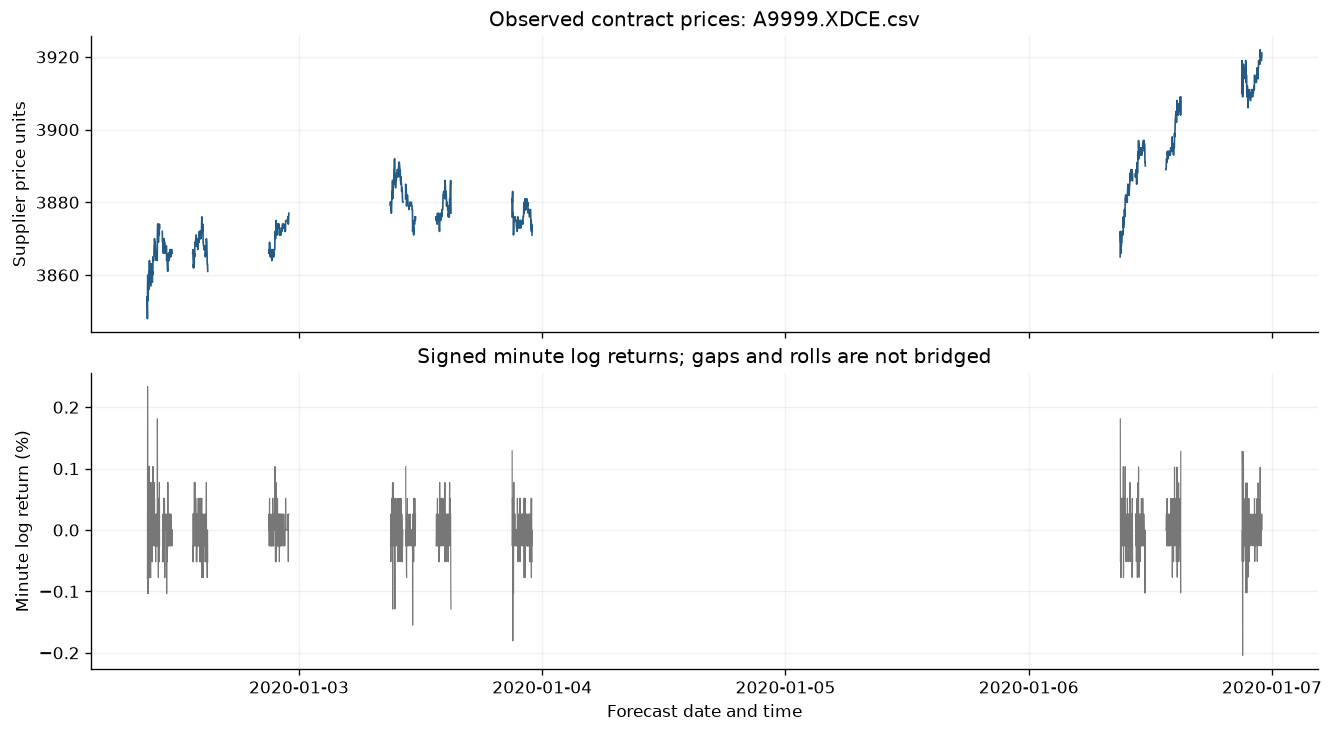

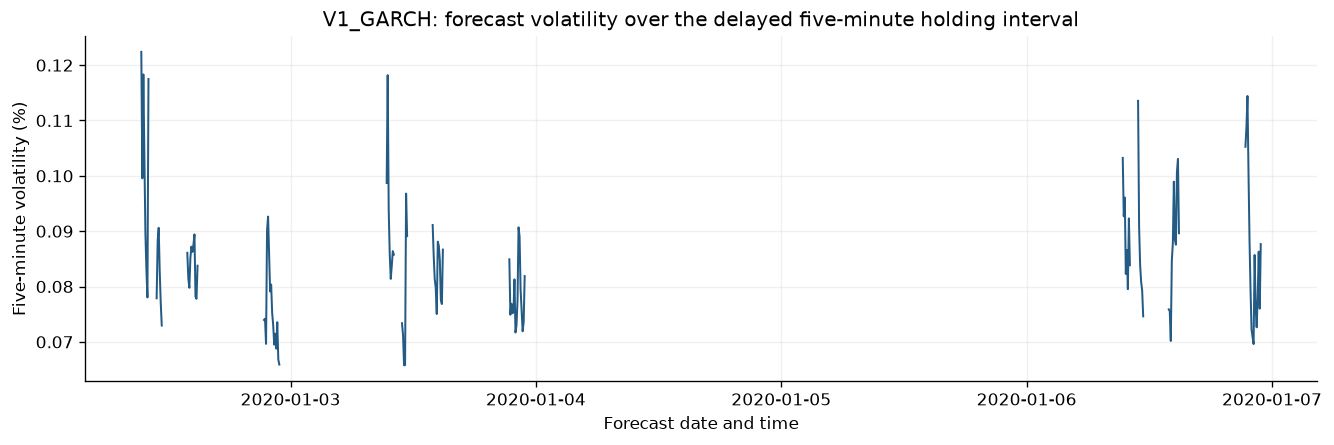

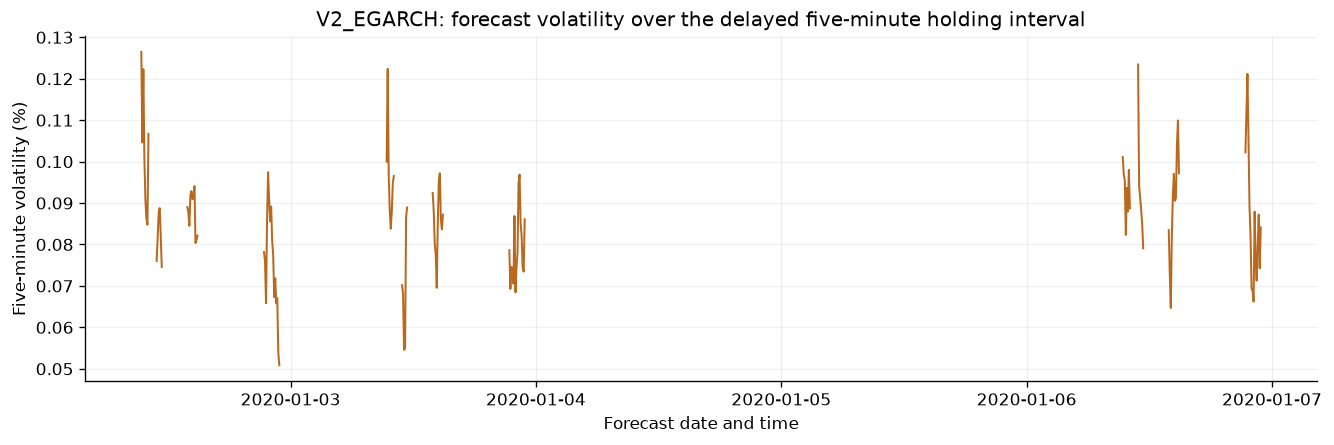

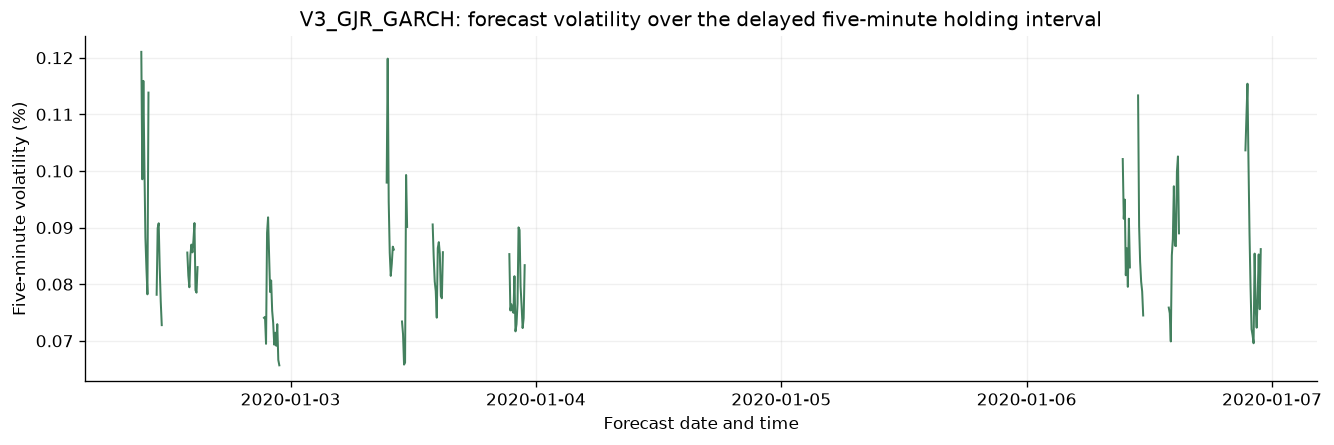

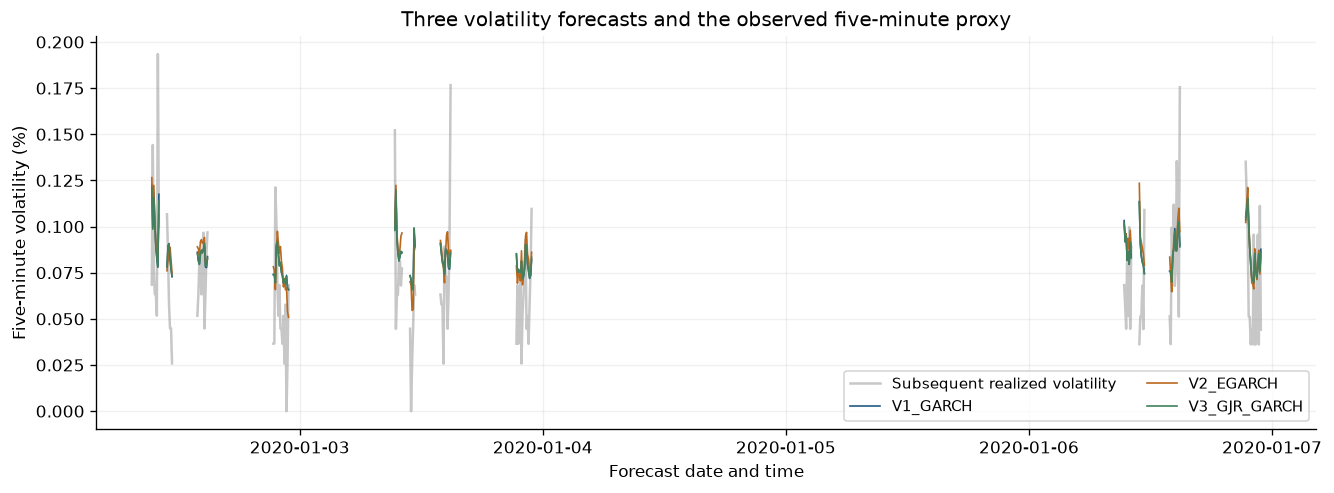

In [49]:
WF_FIGURES=WF_DIR/'figures'; WF_FIGURES.mkdir(exist_ok=True)
WF_COLORS={'V1_GARCH':'#245b85','V2_EGARCH':'#ba681e','V3_GJR_GARCH':'#43805e'}

def wf_save_figure(fig,name):
    fig.savefig(WF_FIGURES/(name+'.png'),dpi=150,bbox_inches='tight')
    plt.show(); plt.close(fig)

def wf_plot_segments(ax, frame, values, label=None, **kwargs):
    first=True
    for _,indices in frame.groupby('segment_id',sort=False).groups.items():
        ax.plot(frame.loc[indices,'date'],values.loc[indices],label=label if first else None,**kwargs)
        first=False

wf_example_file=sorted(wf_events.loc[wf_events.period.eq('holdout'),'file'].unique())[0]
wf_example_all=wf_events.loc[wf_events.file.eq(wf_example_file)&wf_events.period.eq('holdout')].copy()
example_days=np.sort(wf_example_all.day.unique())[:3]
wf_example=wf_example_all.loc[wf_example_all.day.isin(example_days)].copy()
wf_example_market=wf_load_market(wf_example_file)
wf_example_market=wf_example_market.loc[wf_example_market.date.dt.normalize().isin(example_days)]
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True,layout='constrained')
for _,group in wf_example_market.groupby('segment_id',sort=True):
    axes[0].plot(group.date,group.Close,color='#245b85',linewidth=1)
    axes[1].plot(group.date,100*group.log_return,color='#777777',linewidth=.7)
axes[0].set(title=f'Observed contract prices: {wf_example_file}',ylabel='Supplier price units')
axes[1].set(title='Signed minute log returns; gaps and rolls are not bridged',xlabel='Forecast date and time',ylabel='Minute log return (%)')
wf_save_figure(fig,'01_prices_and_returns')

for number,model in enumerate(VOLATILITY_NAMES,2):
    fig,ax=plt.subplots(figsize=(11,3.6),layout='constrained')
    for _,group in wf_example.groupby('segment_id',sort=True):
        ax.plot(group.date,100*np.sqrt(group['variance_H_'+model]),color=WF_COLORS[model],linewidth=1.2)
    ax.set(title=f'{model}: forecast volatility over the delayed five-minute holding interval',
        xlabel='Forecast date and time',ylabel='Five-minute volatility (%)')
    wf_save_figure(fig,f'{number:02d}_{model}_forecast')
fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
wf_plot_segments(ax,wf_example,100*np.sqrt(wf_example.realized_variance),color='#999999',alpha=.55,label='Subsequent realized volatility')
for model in VOLATILITY_NAMES:
    wf_plot_segments(ax,wf_example,100*np.sqrt(wf_example['variance_H_'+model]),label=model,color=WF_COLORS[model],linewidth=1)
ax.set(title='Three volatility forecasts and the observed five-minute proxy',xlabel='Forecast date and time',ylabel='Five-minute volatility (%)')
ax.legend(ncol=2,fontsize=9); wf_save_figure(fig,'05_volatility_comparison')

### Standardized shocks and news impact curves

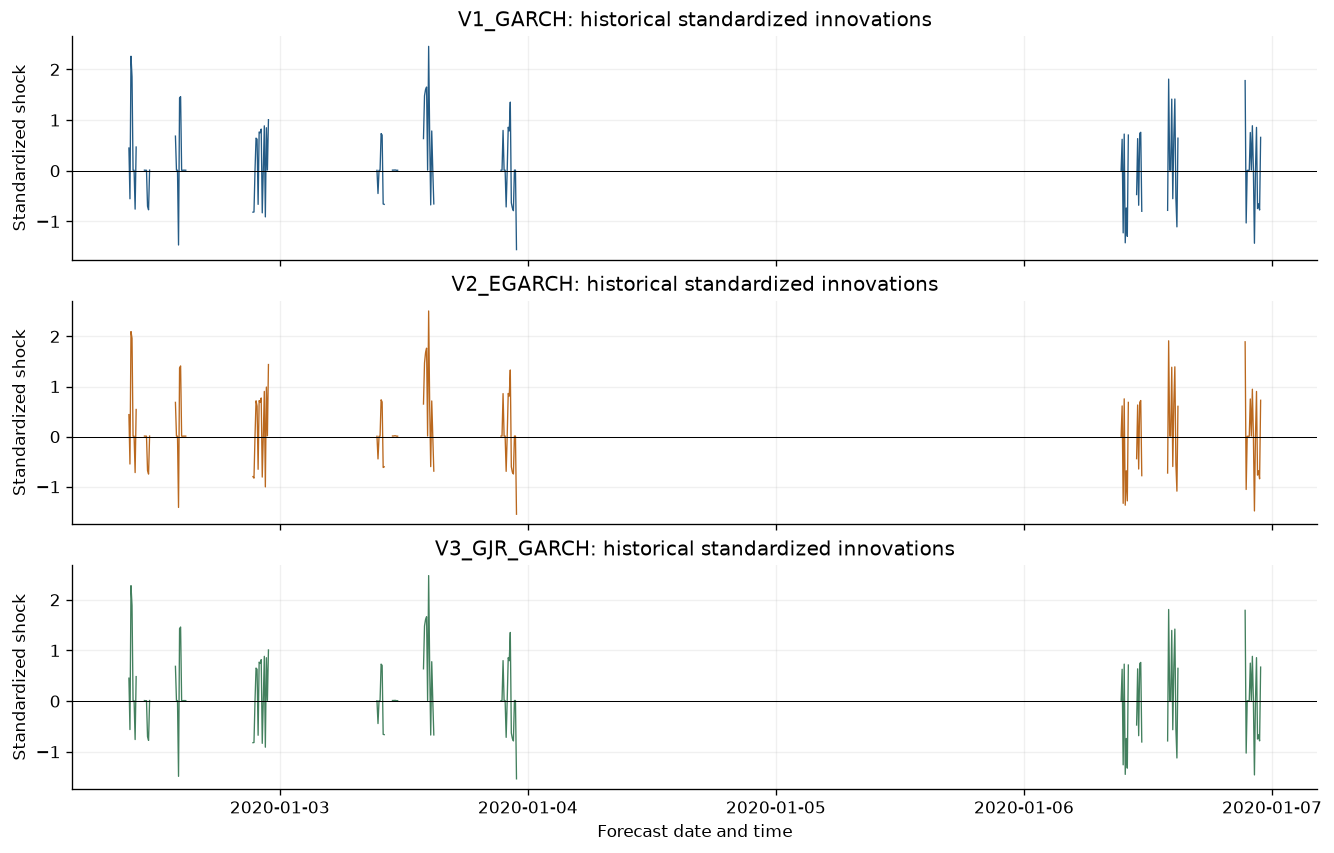

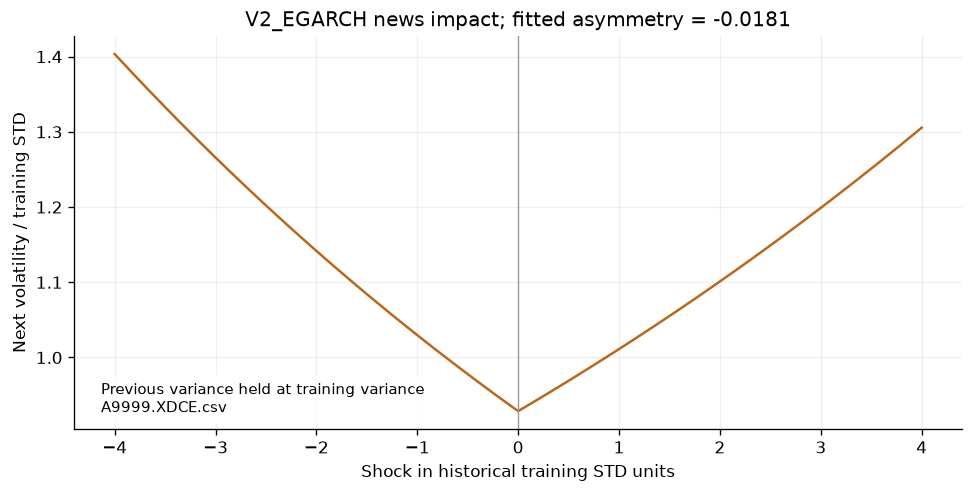

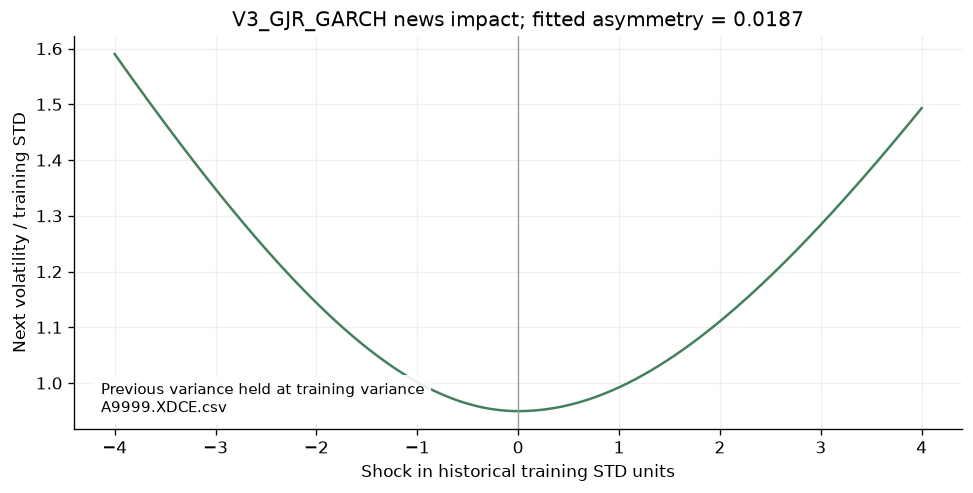

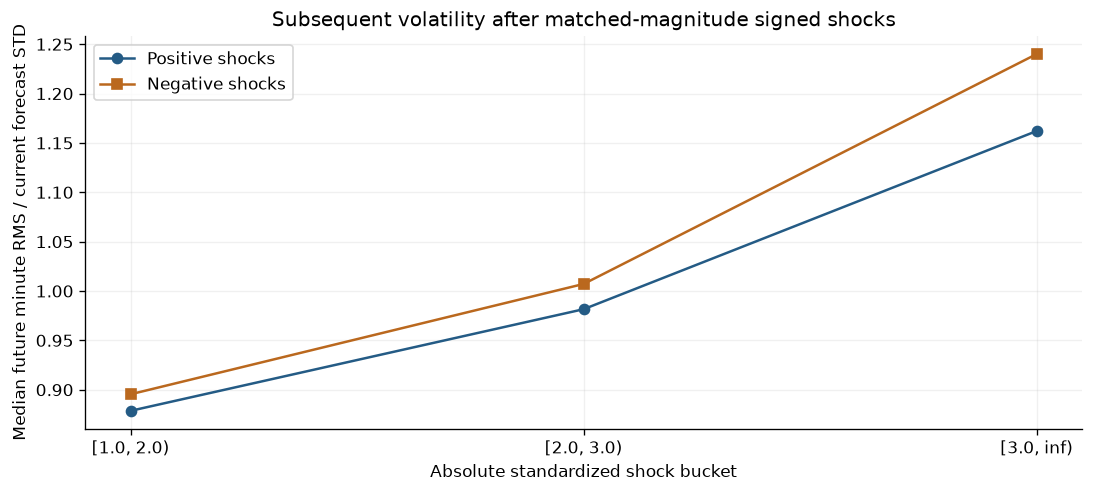

In [50]:
fig,axes=plt.subplots(3,1,figsize=(11,7),sharex=True,layout='constrained')
for ax,model in zip(axes,VOLATILITY_NAMES):
    wf_plot_segments(ax,wf_example,wf_example['innovation_'+model],color=WF_COLORS[model],linewidth=.8)
    ax.axhline(0,color='black',linewidth=.6)
    ax.set(title=f'{model}: historical standardized innovations',ylabel='Standardized shock')
axes[-1].set_xlabel('Forecast date and time'); wf_save_figure(fig,'06_standardized_innovations')
news_fits=wf_fits.loc[wf_fits.file.eq(wf_example_file)&wf_fits.layer.eq('volatility')&wf_fits.success.eq(True)].copy()
news_fits['refit_time']=pd.to_datetime(news_fits.refit_time)
news_origin=wf_example.date.min(); shock_grid=np.linspace(-4,4,201)
for number,model in [(7,'V2_EGARCH'),(8,'V3_GJR_GARCH')]:
    fitted=news_fits.loc[news_fits.model.eq(model)&news_fits.refit_time.le(news_origin)].sort_values('refit_time').iloc[-1]
    if model=='V2_EGARCH':
        next_variance=np.exp(fitted.omega+fitted.alpha*(np.abs(shock_grid)-np.sqrt(2/np.pi))+fitted.gamma*shock_grid)
    else:
        next_variance=fitted.omega+fitted.beta+(fitted.alpha+fitted.gamma*(shock_grid<0))*shock_grid**2
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    ax.plot(shock_grid,np.sqrt(next_variance),color=WF_COLORS[model])
    ax.axvline(0,color='#999999',linewidth=.8)
    ax.set(title=f'{model} news impact; fitted asymmetry = {fitted.gamma:.4f}',xlabel='Shock in historical training STD units',
        ylabel='Next volatility / training STD')
    ax.text(.03,.03,'Previous variance held at training variance\n'+wf_example_file,transform=ax.transAxes,va='bottom',fontsize=9,bbox={'facecolor':'white','alpha':.9,'edgecolor':'none'})
    wf_save_figure(fig,f'{number:02d}_{model}_news_impact')

fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
shock_chart=wf_asymmetry.loc[wf_asymmetry.period.eq('holdout')].copy()
for sign,color,marker in [('positive','#245b85','o'),('negative','#ba681e','s')]:
    group=shock_chart.loc[shock_chart.shock_sign.eq(sign)]
    ax.plot(group.magnitude_bucket.astype(str),group.relative_next_H_volatility,label=sign.capitalize()+' shocks',color=color,marker=marker)
ax.set(title='Subsequent volatility after matched-magnitude signed shocks',xlabel='Absolute standardized shock bucket',
    ylabel='Median future minute RMS / current forecast STD')
ax.legend(); wf_save_figure(fig,'09_signed_shock_response')

### Probabilities, reliability and confidence economics

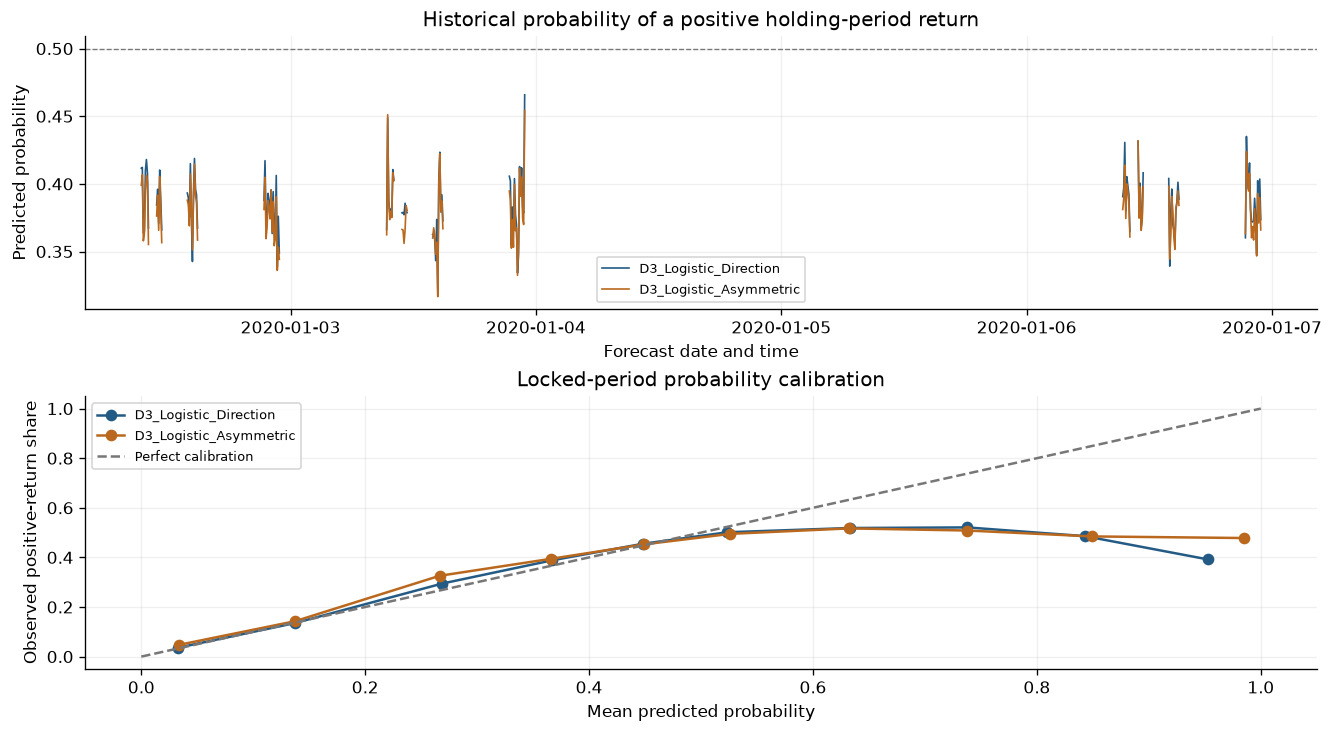

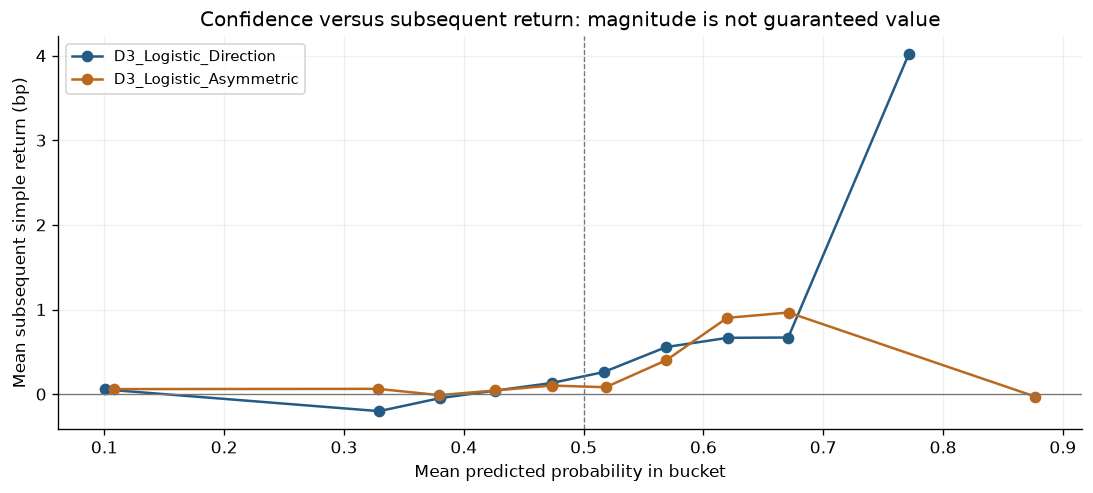

In [51]:
fig,axes=plt.subplots(2,1,figsize=(11,6),layout='constrained')
for name,color in [('D3_Logistic_Direction','#245b85'),('D3_Logistic_Asymmetric','#ba681e')]:
    wf_plot_segments(axes[0],wf_example,wf_example[name],label=name,color=color,linewidth=1)
    c=wf_calibration.loc[wf_calibration.period.eq('holdout')&wf_calibration.model.eq(name)]
    axes[1].plot(c.predicted,c.observed,marker='o',label=name,color=color)
axes[0].axhline(.5,color='#777777',linestyle='--',linewidth=.8)
axes[0].set(title='Historical probability of a positive holding-period return',xlabel='Forecast date and time',ylabel='Predicted probability')
axes[1].plot([0,1],[0,1],color='#777777',linestyle='--',label='Perfect calibration')
axes[1].set(title='Locked-period probability calibration',xlabel='Mean predicted probability',ylabel='Observed positive-return share')
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8); wf_save_figure(fig,'10_direction_probabilities')
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
for name,color in [('D3_Logistic_Direction','#245b85'),('D3_Logistic_Asymmetric','#ba681e')]:
    group=wf_confidence.loc[wf_confidence.period.eq('holdout')&wf_confidence.model.eq(name)]
    ax.plot(group.mean_probability,10000*group.mean_future_return,label=name,color=color,marker='o')
ax.axhline(0,color='#777777',linewidth=.8); ax.axvline(.5,color='#777777',linestyle='--',linewidth=.8)
ax.set(title='Confidence versus subsequent return: magnitude is not guaranteed value',xlabel='Mean predicted probability in bucket',
    ylabel='Mean subsequent simple return (bp)')
ax.legend(fontsize=9); wf_save_figure(fig,'11_confidence_returns')

### Net equity, drawdown and exposure on the locked period

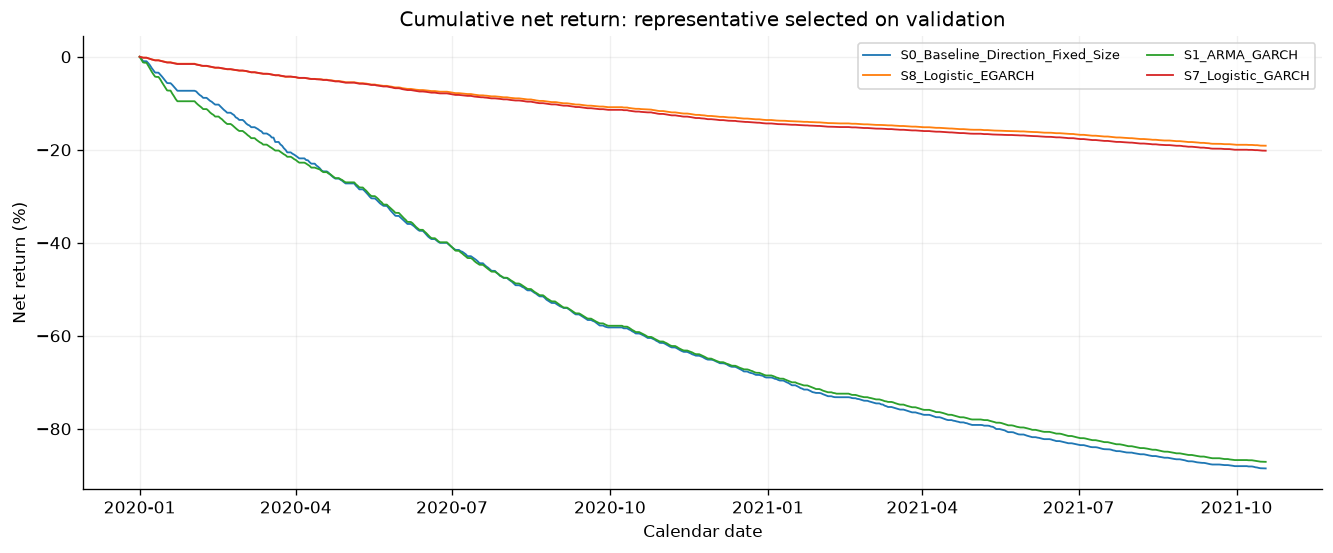

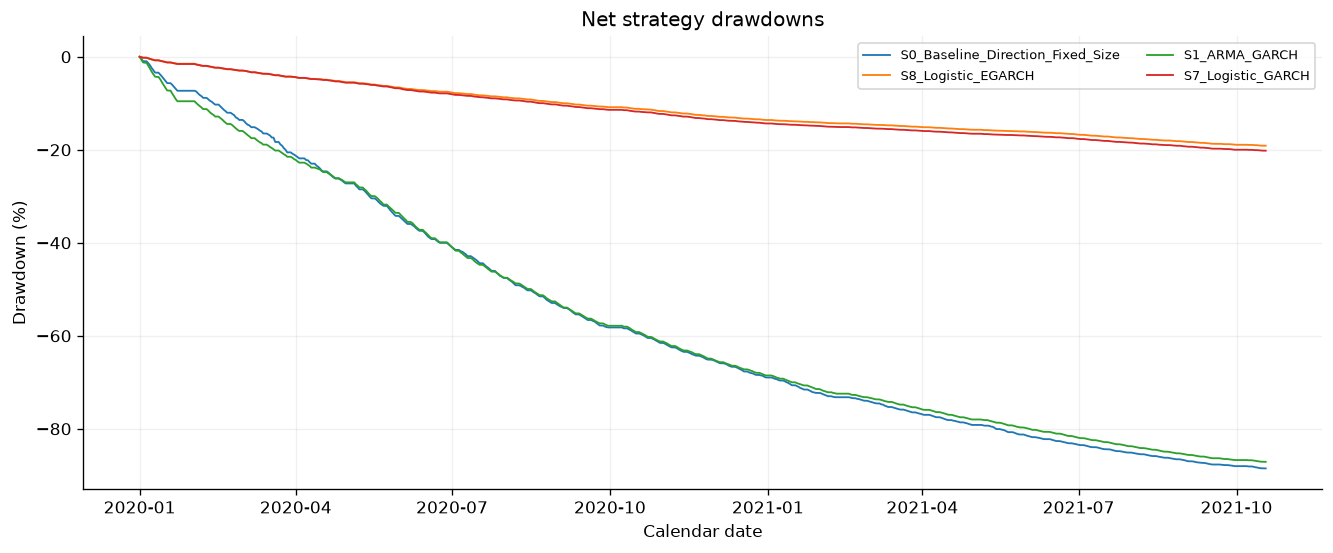

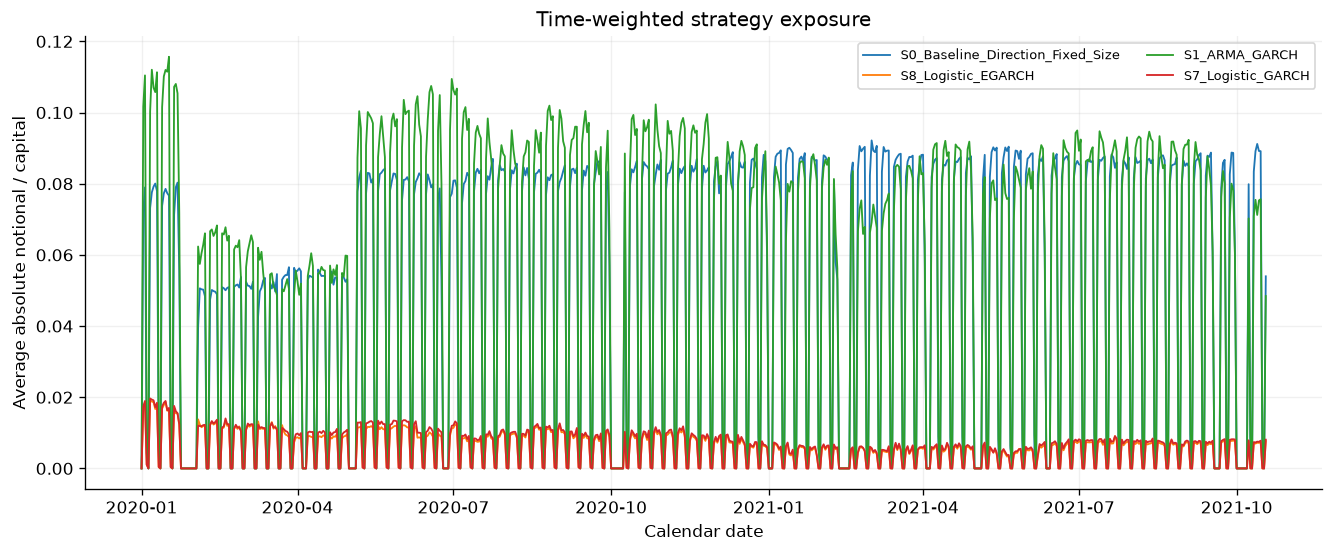

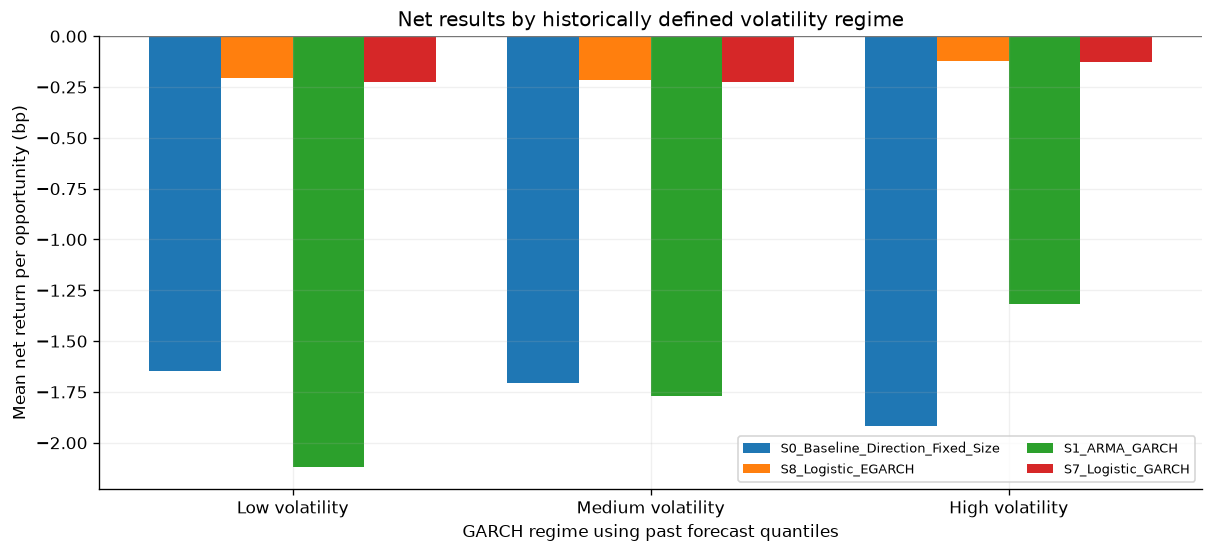

In [52]:
holdout_calendar=wf_periods['holdout']
for number,column,title,ylabel in [(12,'equity','Cumulative net return: representative selected on validation','Net return (%)'),
    (13,'drawdown','Net strategy drawdowns','Drawdown (%)'),(14,'average_absolute_exposure','Time-weighted strategy exposure','Average absolute notional / capital')]:
    fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
    for name in wf_display_names:
        daily=wf_daily_series[name].loc[holdout_calendar]
        equity=(1+daily.net).cumprod()
        if column=='equity': series=100*(equity-1)
        elif column=='drawdown': series=100*(equity/equity.cummax().clip(lower=1)-1)
        else: series=daily[column]
        ax.plot(daily.index,series,label=name,linewidth=1.1)
    ax.set(title=title,xlabel='Calendar date',ylabel=ylabel);ax.legend(fontsize=8,ncol=2)
    wf_save_figure(fig,f'{number:02d}_{column}')

fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
regime_order=['low','medium','high']; width=.8/len(wf_display_names)
for j,name in enumerate(wf_display_names):
    group=wf_regimes.loc[wf_regimes.period.eq('holdout')&wf_regimes.strategy.eq(name)].set_index('regime').reindex(regime_order)
    ax.bar(np.arange(3)+(j-(len(wf_display_names)-1)/2)*width,10000*group.mean_net,width,label=name)
ax.set_xticks(np.arange(3),['Low volatility','Medium volatility','High volatility'])
ax.set(title='Net results by historically defined volatility regime',xlabel='GARCH regime using past forecast quantiles',
    ylabel='Mean net return per opportunity (bp)')
ax.axhline(0,color='#777777',linewidth=.8);ax.legend(fontsize=8,ncol=2);wf_save_figure(fig,'15_regime_performance')

### Identical breakout entries under three expansion filters

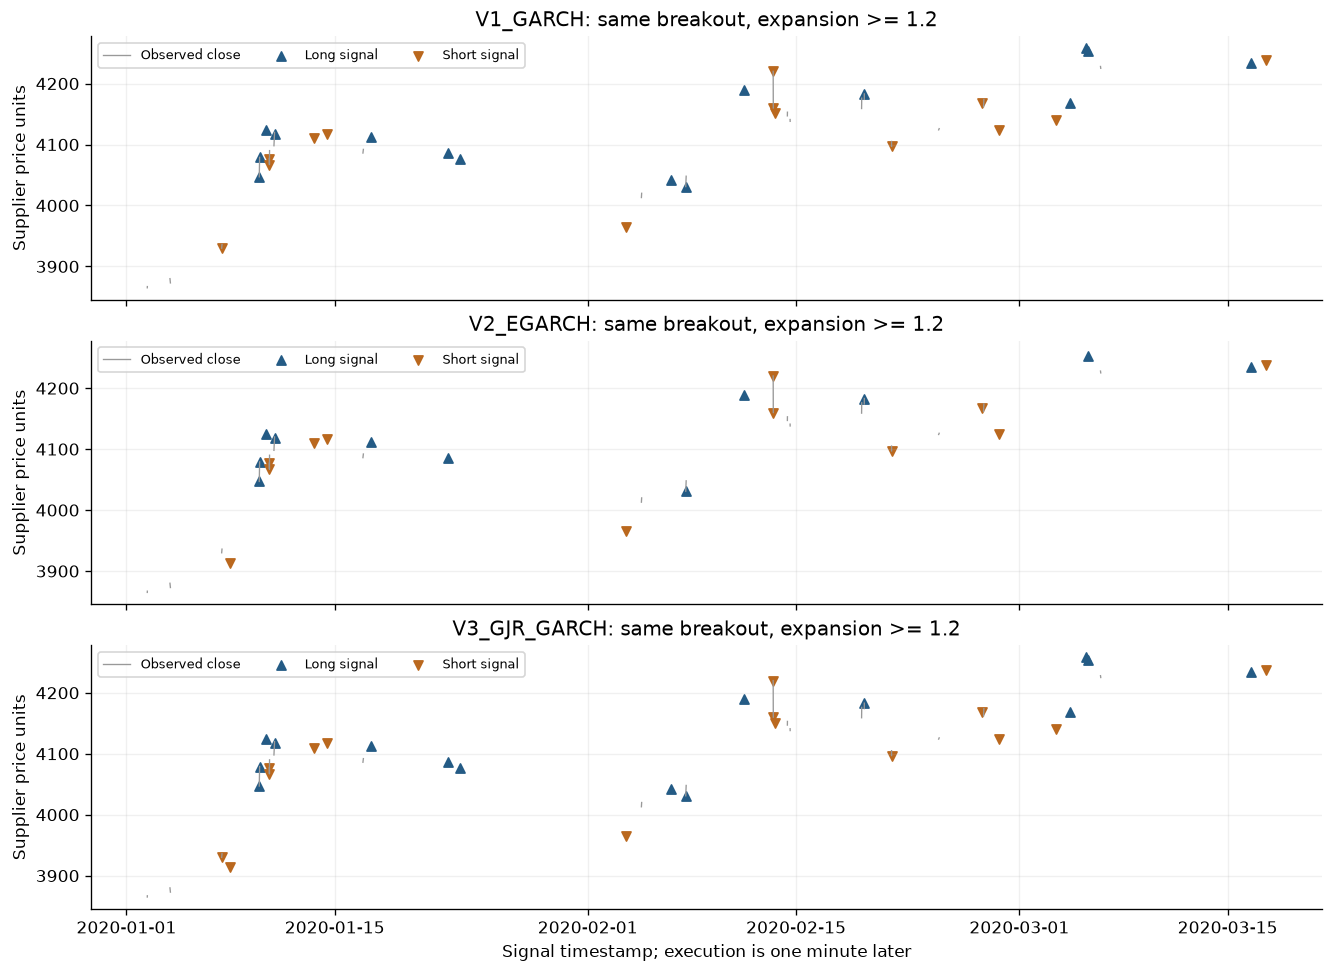

In [53]:
breakout_example=wf_example_all.loc[wf_example_all.breakout.ne(0)].head(90).copy()
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True,layout='constrained')
for ax,model,short in zip(axes,VOLATILITY_NAMES,['garch','egarch','gjr']):
    wf_plot_segments(ax,breakout_example,breakout_example.Close,color='#999999',linewidth=.8,label='Observed close')
    accepted=breakout_example['expansion_'+short].ge(EXPANSION_THRESHOLD)
    for side,marker,color in [(1,'^','#245b85'),(-1,'v','#ba681e')]:
        subset=breakout_example.loc[accepted&breakout_example.breakout.eq(side)]
        ax.scatter(subset.date,subset.Close,marker=marker,color=color,s=30,label='Long signal' if side==1 else 'Short signal')
    ax.set(title=f'{model}: same breakout, expansion >= {EXPANSION_THRESHOLD}',ylabel='Supplier price units')
    ax.legend(fontsize=8,ncol=3)
axes[-1].set_xlabel('Signal timestamp; execution is one minute later');wf_save_figure(fig,'16_breakout_filters')

### Research conclusions: direction, volatility, costs and remaining uncertainty

**Reading the paired tests in this execution.** All four statistically detectable asymmetric-logistic mean-return differences are **negative**: the augmented model worsens net results. Its small AUC gain does not establish incremental trading value. Across the 21 same-direction sizing comparisons, absolute mean losses decrease but every net Sharpe difference versus the fixed-score control is negative. These outcomes do not support a risk-adjusted trading improvement from the tested sizing rule. Statistical significance below means a detectable difference, not necessarily a favorable one.


In [54]:
holdout_direction=wf_direction_summary.loc[wf_direction_summary.period.eq('holdout')].set_index('model')
holdout_volatility=wf_vol_summary.loc[wf_vol_summary.period.eq('holdout')].set_index('model')
holdout_performance=wf_performance_table.loc[wf_performance_table.period.eq('holdout')].set_index('strategy')
primary_holdout=holdout_performance.loc[wf_primary_names]
best_primary=primary_holdout.sharpe.idxmax()
raw_direction=holdout_direction.loc['D1_ARMA_Raw_Returns']
base_direction=holdout_direction.loc['D0_Baseline']
logistic_direction=holdout_direction.loc['D3_Logistic_Direction']
augmented_direction=holdout_direction.loc['D3_Logistic_Asymmetric']
std_candidates=holdout_direction.loc[DIRECTION_NAMES[2:5]]
best_standardized=std_candidates.nonzero_sign_accuracy.idxmax()
vol_best=holdout_volatility.qlike.idxmin()
contrasts=wf_volatility_contrasts.loc[wf_volatility_contrasts.period.eq('holdout')].set_index('candidate')
shock_diagnostic=wf_asymmetry.loc[wf_asymmetry.period.eq('holdout')].pivot(index='magnitude_bucket',columns='shock_sign',values='relative_next_H_volatility')
ratio=(shock_diagnostic.negative/shock_diagnostic.positive).replace([np.inf,-np.inf],np.nan)
selected_row=holdout_performance.loc[wf_selected_strategy]
selected_sensitivity=wf_sensitivity.loc[wf_sensitivity.period.eq('holdout')&wf_sensitivity.strategy.eq(wf_selected_strategy)&wf_sensitivity.parameter.ne('cost')]
selected_uncertainty=wf_uncertainty.loc[wf_uncertainty.period.eq('holdout')&wf_uncertainty.strategy.eq(wf_selected_strategy)].iloc[0]
selected_fixed=lookup[(selected_specification['direction'],'Fixed')]
selected_fixed_row=holdout_performance.loc[selected_fixed]
positive_net=int((primary_holdout.total_return>0).sum())
family_q=wf_attribution.loc[wf_attribution.period.eq('holdout')&wf_attribution.comparison.eq('Asymmetric logistic predictors'),'paired_q_by']
conclusions=[
    f"**1. Directional predictability.** On a common instrument cohort, baseline nonzero sign accuracy is {base_direction.nonzero_sign_accuracy:.2%}; raw ARMA is {raw_direction.nonzero_sign_accuracy:.2%}; logistic direction is {logistic_direction.nonzero_sign_accuracy:.2%}. Strict sign accuracy excludes zero targets and neutral forecasts; baseline direction coverage is {base_direction.direction_coverage:.2%}. Binary accuracy instead uses positive versus nonpositive targets. These denominators, score calibration and net outcomes must be considered together.",
    f"**2. Raw-return ARMA.** Its equal-instrument mean score/return correlation is {raw_direction.correlation:.4f}, versus {base_direction.correlation:.4f} for momentum. This measures incremental out-of-sample association at the specified delayed five-minute horizon, not a proof that futures prices are predictable at arbitrary horizons.",
    f"**3. Volatility standardization.** The strongest standardized variant by descriptive holdout nonzero sign accuracy is `{best_standardized}` at {std_candidates.loc[best_standardized,'nonzero_sign_accuracy']:.2%}, compared with raw ARMA at {raw_direction.nonzero_sign_accuracy:.2%}. Fixed-size paired tests in `controlled_attribution.csv` separate normalization from volatility sizing; this ranking does not change the frozen strategy.",
    f"**4. Direct probabilistic direction.** The core logistic model has mean instrument AUC {logistic_direction.auc:.4f} and Brier score {logistic_direction.brier:.4f}. Its nonzero sign accuracy differs from raw ARMA by {100*(logistic_direction.nonzero_sign_accuracy-raw_direction.nonzero_sign_accuracy):+.2f} percentage points. Calibration and confidence buckets show whether probability magnitude adds useful discrimination.",
    f"**5. Standard GARCH.** Median instrument correlation with subsequent realized volatility is {holdout_volatility.loc['V1_GARCH','volatility_correlation']:.3f}. The lowest equal-instrument holdout QLIKE among all five variance models is `{vol_best}`. Realized squared-return variance is noisy; positive correlation alone does not establish superiority over EWMA or trailing volatility.",
    f"**6. EGARCH versus GARCH.** The mean paired QLIKE difference is {contrasts.loc['V2_EGARCH','mean_qlike_difference']:+.4f}; EGARCH improves QLIKE in {int(contrasts.loc['V2_EGARCH','lower_qlike_files'])}/{int(contrasts.loc['V2_EGARCH','files'])} instruments. Negative differences favor EGARCH. Its variance MSE is {holdout_volatility.loc['V2_EGARCH','mse']:.3g} versus {holdout_volatility.loc['V1_GARCH','mse']:.3g} for GARCH: extreme EGARCH forecasts expose numerical/model fragility. They are flagged and retained, not winsorized.",
    f"**7. GJR versus GARCH.** The mean paired QLIKE difference is {contrasts.loc['V3_GJR_GARCH','mean_qlike_difference']:+.4f}; GJR improves in {int(contrasts.loc['V3_GJR_GARCH','lower_qlike_files'])}/{int(contrasts.loc['V3_GJR_GARCH','files'])} instruments. An asymmetric specification is not automatically better merely because it has an additional parameter.",
    f"**8. Signed-shock asymmetry.** Across magnitude buckets, negative/positive ratios of median scale-normalized subsequent volatility range from {ratio.min():.3f} to {ratio.max():.3f}. Values above one indicate higher subsequent volatility after negative shocks in that bucket. Instrument-level tables and estimated gamma values must accompany this pooled diagnostic; it is not causal evidence.",
    f"**9. Indirect directional value of asymmetry.** Adding asymmetric predictors changes mean AUC by {augmented_direction.auc-logistic_direction.auc:+.4f} and Brier score by {augmented_direction.brier-logistic_direction.brier:+.4f}. {int((family_q<.05).sum())}/{len(family_q)} sizing comparisons pass the reported BY-adjusted paired mean-return test. These results concern a probabilistic direction model; EGARCH/GJR themselves do not predict a negative or positive return.",
    f"**10. Direction plus volatility.** The descriptive primary holdout Sharpe leader is `{best_primary}` (Sharpe {primary_holdout.loc[best_primary,'sharpe']:.2f}, net total return {primary_holdout.loc[best_primary,'total_return']:.2%}). The representative chosen strictly on validation is `{wf_selected_strategy}` (holdout Sharpe {selected_row.sharpe:.2f}). The former is a reported ranking, not a deployable selection made before the holdout.",
    f"**11. Transaction costs.** {positive_net}/{len(primary_holdout)} primary variants have positive net total return at 1 bp per side. The validation-selected strategy has net total return {selected_row.total_return:.2%} and gross PnL {selected_row.gross_pnl:.4f} versus costs {selected_row.transaction_costs:.4f} per unit starting equity. The cost grid shows how quickly any gross effect disappears.",
    f"**12. Locked-period evidence.** For the validation-selected strategy the daily mean 95% HAC interval is [{selected_uncertainty.hac_mean_lower:.6f}, {selected_uncertainty.hac_mean_upper:.6f}]. Orders, features and thresholds use past/training/validation data, but the historical dataset was already examined in earlier research. A claim of survival on a truly untouched holdout is therefore unavailable; new market data are required.",
    f"**13. Direction versus risk management.** The selected model's fixed-size control has Sharpe {selected_fixed_row.sharpe:.2f}, compared with {selected_row.sharpe:.2f} for its selected sizing. A higher net Sharpe can reflect lower turnover or exposure, including spending more time in cash. Controlled gross direction, cost and sizing contrasts are needed before describing any difference as alpha; volatility forecast improvement alone is risk information.",
    f"**14. Nearby settings.** The selected strategy's tested neighboring exposure/threshold settings produce holdout Sharpe from {selected_sensitivity.sharpe.min():.2f} to {selected_sensitivity.sharpe.max():.2f}. This limited robustness check does not cover every train window, refit schedule or forecast horizon. No parameter is reselected using these holdout results."
]
display(Markdown('## Two-layer research conclusions\n\n'+'\n\n'.join(conclusions)))
(WF_DIR/'research_conclusions.md').write_text('# Two-layer research conclusions\n\n'+'\n\n'.join(conclusions)+'\n')

## Two-layer research conclusions

**1. Directional predictability.** On a common instrument cohort, baseline nonzero sign accuracy is 47.27%; raw ARMA is 50.39%; logistic direction is 50.33%. Strict sign accuracy excludes zero targets and neutral forecasts; baseline direction coverage is 77.20%. Binary accuracy instead uses positive versus nonpositive targets. These denominators, score calibration and net outcomes must be considered together.

**2. Raw-return ARMA.** Its equal-instrument mean score/return correlation is -0.0026, versus -0.0139 for momentum. This measures incremental out-of-sample association at the specified delayed five-minute horizon, not a proof that futures prices are predictable at arbitrary horizons.

**3. Volatility standardization.** The strongest standardized variant by descriptive holdout nonzero sign accuracy is `D2_ARMA_Standardized_EGARCH` at 50.50%, compared with raw ARMA at 50.39%. Fixed-size paired tests in `controlled_attribution.csv` separate normalization from volatility sizing; this ranking does not change the frozen strategy.

**4. Direct probabilistic direction.** The core logistic model has mean instrument AUC 0.5343 and Brier score 0.2184. Its nonzero sign accuracy differs from raw ARMA by -0.06 percentage points. Calibration and confidence buckets show whether probability magnitude adds useful discrimination.

**5. Standard GARCH.** Median instrument correlation with subsequent realized volatility is 0.511. The lowest equal-instrument holdout QLIKE among all five variance models is `V3_GJR_GARCH`. Realized squared-return variance is noisy; positive correlation alone does not establish superiority over EWMA or trailing volatility.

**6. EGARCH versus GARCH.** The mean paired QLIKE difference is +0.0362; EGARCH improves QLIKE in 22/70 instruments. Negative differences favor EGARCH. Its variance MSE is 7.69e+06 versus 1.85e-08 for GARCH: extreme EGARCH forecasts expose numerical/model fragility. They are flagged and retained, not winsorized.

**7. GJR versus GARCH.** The mean paired QLIKE difference is -0.0006; GJR improves in 36/70 instruments. An asymmetric specification is not automatically better merely because it has an additional parameter.

**8. Signed-shock asymmetry.** Across magnitude buckets, negative/positive ratios of median scale-normalized subsequent volatility range from 1.019 to 1.067. Values above one indicate higher subsequent volatility after negative shocks in that bucket. Instrument-level tables and estimated gamma values must accompany this pooled diagnostic; it is not causal evidence.

**9. Indirect directional value of asymmetry.** Adding asymmetric predictors changes mean AUC by +0.0009 and Brier score by +0.0007. 4/4 sizing comparisons pass the reported BY-adjusted paired mean-return test. These results concern a probabilistic direction model; EGARCH/GJR themselves do not predict a negative or positive return.

**10. Direction plus volatility.** The descriptive primary holdout Sharpe leader is `S8_Logistic_EGARCH` (Sharpe -20.67, net total return -19.12%). The representative chosen strictly on validation is `S8_Logistic_EGARCH` (holdout Sharpe -20.67). The former is a reported ranking, not a deployable selection made before the holdout.

**11. Transaction costs.** 0/10 primary variants have positive net total return at 1 bp per side. The validation-selected strategy has net total return -19.12% and gross PnL -0.0011 versus costs 0.1901 per unit starting equity. The cost grid shows how quickly any gross effect disappears.

**12. Locked-period evidence.** For the validation-selected strategy the daily mean 95% HAC interval is [-0.000350, -0.000296]. Orders, features and thresholds use past/training/validation data, but the historical dataset was already examined in earlier research. A claim of survival on a truly untouched holdout is therefore unavailable; new market data are required.

**13. Direction versus risk management.** The selected model's fixed-size control has Sharpe -14.96, compared with -20.67 for its selected sizing. A higher net Sharpe can reflect lower turnover or exposure, including spending more time in cash. Controlled gross direction, cost and sizing contrasts are needed before describing any difference as alpha; volatility forecast improvement alone is risk information.

**14. Nearby settings.** The selected strategy's tested neighboring exposure/threshold settings produce holdout Sharpe from -21.57 to -17.82. This limited robustness check does not cover every train window, refit schedule or forecast horizon. No parameter is reselected using these holdout results.

4634

### Save lineage, model diagnostics and execution audit

In [55]:
import importlib.metadata
versions={package:importlib.metadata.version(package) for package in ['numpy','pandas','scipy','pyarrow','matplotlib','numba','statsmodels','threadpoolctl']}
volatility_fits=wf_fits.loc[wf_fits.layer.eq('volatility')&wf_fits.success.eq(True)]
parameter_summary=volatility_fits.groupby('model').agg(refits=('model','size'),median_alpha=('alpha','median'),
    median_beta=('beta','median'),median_gamma=('gamma','median'),negative_gamma_share=('gamma',lambda s:s.lt(0).mean()),
    median_persistence=('persistence','median'),median_aic=('aic','median'),median_bic=('bic','median'),
    numerical_bound_hits=('numerical_bound_hits','sum'),filtered_state_bound_hits=('numerical_forecast_bound_hits','sum')).reset_index()
parameter_summary.to_csv(WF_DIR/'volatility_parameter_summary.csv',index=False)
wf_show_table(parameter_summary[['model','refits','median_alpha','median_beta','median_gamma','median_persistence','numerical_bound_hits']],
    'Estimated conditional variance parameters; AIC/BIC are training diagnostics',rows=3)
innovations=[]
for period,sample in wf_vol_events.groupby('period'):
    for model in VOLATILITY_NAMES:
        series=sample['innovation_'+model].dropna()
        innovations.append(dict(period=period,model=model,n=len(series),mean=series.mean(),std=series.std(),skew=series.skew(),excess_kurtosis=series.kurt()))
pd.DataFrame(innovations).to_csv(WF_DIR/'standardized_innovation_diagnostics.csv',index=False)
selected_order_rows=wf_fits.loc[wf_fits.layer.eq('direction')&wf_fits.model.isin(DIRECTION_NAMES[1:5])].copy()
assert (pd.to_datetime(selected_order_rows.specification_frozen_at)<HOLDOUT_START).all()
assert (pd.to_datetime(wf_fits.loc[wf_fits.success.eq(True),'train_end'])<pd.to_datetime(wf_fits.loc[wf_fits.success.eq(True),'refit_time'])).all()
for (filename,model),group in selected_order_rows.groupby(['file','model']):
    assert group.order.map(str).nunique()==1,'An ARMA order changed after its first calibration.'
selected_order_rows.drop_duplicates(['file','model'])[['file','model','order','specification_frozen_at']].to_csv(WF_DIR/'frozen_arma_orders.csv',index=False)
wf_lineage=dict(config=WF_CONFIG,cache_key=WF_CACHE_KEY,feature_sha256=source_hashes[str(FEATURE_PATH)],versions=versions,
    source_files=len(files),model_forecast_instruments=int(wf_predictions.file.nunique()),trading_instruments=int(wf_events.file.nunique()),
    eligible_origins=len(wf_events),cancelled_entries=int(wf_predictions.entry_cancelled.sum()),unresolved_entries=len(unresolved),
    period_start=str(wf_events.date.min()),period_end=str(wf_events.date.max()),selected_on_validation=wf_selected_strategy,
    thresholds=wf_thresholds,annualization='365.25 calendar days after daily aggregation',
    history_previously_examined=True,stage_1_and_2_unchanged=True,raw_data_modified=False)
(WF_DIR/'run_manifest.json').write_text(json.dumps(wf_json_safe(wf_lineage),indent=2)+'\n')
assert file_hash(FEATURE_PATH)==source_hashes[str(FEATURE_PATH)],'The feature artifact changed during research.'
print('Walk-forward results, forecasts, execution audit and figures saved to:',WF_DIR)
print('Stage 1 and Stage 2 inputs are unchanged; the original strategy_hypothesis_results.csv is preserved.')
print('This is normalized-notional research, not evidence of realizable fills or a production-ready profitable strategy.')

model,refits,median alpha,median beta,median gamma,median persistence,numerical bound hits
V1_GARCH,1496,0.0875471,0.888055,0,0.977555,0
V2_EGARCH,1496,0.188427,0.963363,-0.00685463,0.963363,27
V3_GJR_GARCH,1496,0.0825913,0.888153,0.00838733,0.977686,0


Walk-forward results, forecasts, execution audit and figures saved to: artifacts/strategies/two_layer_walk_forward
Stage 1 and Stage 2 inputs are unchanged; the original strategy_hypothesis_results.csv is preserved.
This is normalized-notional research, not evidence of realizable fills or a production-ready profitable strategy.
